# IterOrbit: data, figures and tables

Every number, table and figure of the paper, and the exploratory analyses behind it, from the CSVs in
`analysis/data/` (built once from the experiments' logs by `analysis/build_data.py`; this script reads no log).
Neither the CSVs nor `build_data.py` are in the repository; both are available from the authors on request.

Run it as a script (`python analysis/analysis.py`) or open it as a notebook: the `# %%` lines are cells
(VS Code and Jupyter with Jupytext read them; `jupytext --to notebook analysis/analysis.py` writes an
`.ipynb`). Each section is one function that prints its results and returns its main tables. In a notebook the
figures are shown under their cells and not saved; as a script they are written as PDFs to `analysis/figures/`
(the paper's figures to `../paper/figures/` instead when the paper's checkout sits next to this repository;
`ANALYSIS_SAVE_FIGURES=1`/`0` overrides either default; `ANALYSIS_FIG_DIR` writes them elsewhere).

Conventions used throughout:
- **End-to-end time** is each system's own filter + order + enumerate timers, graph loading excluded, plus the
  build time of the indexes its filter reads (`with_index`), amortised over the instances on each data graph
  that every compared system completed (`INDEX_CHARGE`; the end-to-end figures charge each run in full,
  `E2E_INDEX_CHARGE`), plus IterOrbit's symmetry breaking, floored at 0.1 ms (`TIME_FLOOR_MS`).
- **Speed-up** of IterOrbit over a system is the geometric mean of (system's time / IterOrbit's) over the
  instances both completed; "fastest" counts ties for every tied system.
- **Reduction** is measured against round 1's LDF + NLF + arc-consistency candidates.

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import matplotlib

INTERACTIVE = "ipykernel" in sys.modules
if not INTERACTIVE:
    matplotlib.use("Agg")
import matplotlib._mathtext
import matplotlib.pyplot as plt
import matplotlib.text
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)


def _find_root():
    here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    for p in [here, *here.parents]:
        if (p / "analysis" / "data" / "MANIFEST.csv").exists():
            return p
    raise FileNotFoundError("analysis/data not found (the CSVs are available from the authors on request)")


ROOT = _find_root()
DATA = ROOT / "analysis" / "data"
_PAPER = ROOT.parent / "paper" / "figures"   # the paper's checkout next to this repository, if there is one
PAPER_FIG_DIR = Path(os.environ.get("ANALYSIS_FIG_DIR", _PAPER if _PAPER.is_dir() else ROOT / "analysis" / "figures"))
EXTRA_FIG_DIR = Path(os.environ.get("ANALYSIS_FIG_DIR", ROOT / "analysis" / "figures"))
# In a notebook the figures are only shown; as a script they are written as PDFs. ANALYSIS_SAVE_FIGURES=1 or 0 overrides.
SAVE_FIGURES = os.environ.get("ANALYSIS_SAVE_FIGURES", "0" if INTERACTIVE else "1") == "1"


def csv(name, **kw):
    """One of the data files (analysis/data/MANIFEST.csv lists them and their sources)."""
    return pd.read_csv(DATA / name, **kw)


def _rel(p):
    return os.path.relpath(p, ROOT)


print(f"data: {_rel(DATA)}\n" + (f"paper figures -> {_rel(PAPER_FIG_DIR)}\nother figures -> {_rel(EXTRA_FIG_DIR)}"
                                  if SAVE_FIGURES else "figures: shown only, not saved"))

data: analysis/data
figures: shown only, not saved


## Toolkit
Benchmarks, tools, colours, the print-scaled figure style (`visualisation_style.md`), and the loaders every
section shares.

In [2]:
IMSM = ["hprd", "human", "patents", "wordnet", "yeast"]   # the five labelled graphs of the earlier drafts
IMSM_ALL = ["dblp", "eu2005", "hprd", "human", "patents", "wordnet", "yeast", "youtube"]
PLOT_IMSM = IMSM_ALL
MCC = ["LV", "images-CVIU11", "meshes-CVIU11", "scalefree", "si"]
LABEL = {"dblp": "DBLP", "eu2005": "EU2005", "youtube": "YouTube",
         "hprd": "HPRD", "human": "Human", "patents": "Patents", "wordnet": "WordNet", "yeast": "Yeast",
         "LV": "LV", "images-CVIU11": "Images", "meshes-CVIU11": "Meshes", "scalefree": "Scalefree",
         "si": "SI"}
BENCH = {"imsm": "Labelled", "mccreesh": "Unlabelled"}

S = sns.color_palette("Set2")
OKABE_ITO = {"orange": "#E69F00", "sky blue": "#56B4E9", "bluish green": "#009E73", "yellow": "#F0E442",
             "blue": "#0072B2", "vermillion": "#D55E00", "reddish purple": "#CC79A7", "black": "#000000"}
TOOLS = ["IterOrbit", "RM", "DP-iso", "VEQ", "CaLiG"]
TOOL_COLOR = {"IterOrbit": S[1], "RM": S[0], "VEQ": S[2], "DP-iso": S[3], "CaLiG": S[4], "OrbitSI": S[5], "GraphQL": S[6]}
TOOL_MARKER = {"IterOrbit": "D", "RM": "s", "CaLiG": "^", "VEQ": "o", "DP-iso": "v", "OrbitSI": "P", "GraphQL": "p"}
PLOT_TOOLS = ["IterOrbit", "OrbitSI", "RM", "DP-iso", "VEQ", "CaLiG"]
SHORT = {"IterOrbit": "IO", "OrbitSI": "OSI", "Glasgow": "GSS", "GraphQL": "GQL"}
MODES = ["Baseline", "OrbitSI", "IterOrbit"]
MODE_LABEL = {"Baseline": "Baseline", "OrbitSI": r"$\mathbf{I_{max}=1}$ (≈ OSI)",
              "IterOrbit": r"$\mathbf{I_{max}=0}$ (IO, to fixpoint)"}
MODE_LABEL_PLAIN = {"Baseline": "Baseline", "OrbitSI": r"$\mathbf{I_{max}=1}$", "IterOrbit": r"$\mathbf{I_{max}=0}$"}
MODE_COLOR = {"Baseline": S[2], "OrbitSI": S[0], "IterOrbit": S[1]}
MODE_HATCH = {"Baseline": "//", "OrbitSI": "\\\\", "IterOrbit": "xx"}
SIZES = [3, 4, 5]
SIZE_MARKER = {3: "o", 4: "s", 5: "^"}
SIZE_LINESTYLE = {3: "solid", 4: "dashed", 5: "dotted"}

COLUMN_IN = 238.96 / 72.27   # svjour3 two-column \columnwidth
TEXT_IN = 495.0 / 72.27      # \textwidth
PRINT_TICK_PT = 7.5          # printed size of a style-guide size-10 tick label
FONT = 1.0                   # multiplier on every style-guide font size, set by setup()


def fs(size):
    """A style-guide font size (ticks 10, axis labels 12, global labels 14, ...), scaled for print."""
    return size * FONT


def setup(fig_width=None, print_width=COLUMN_IN):
    """Start a figure drawn fig_width inches wide that prints print_width wide: sets the font scale."""
    global FONT
    FONT = PRINT_TICK_PT / 10 * fig_width / print_width if fig_width else 1.0
    matplotlib._mathtext.SHRINK_FACTOR = 0.8
    sns.set_context("paper", font_scale=1.2 * FONT)
    sns.set_style("whitegrid")


def gmean(x, floor=1e-3):
    x = np.asarray(x, dtype=float)
    return float(np.exp(np.log(np.clip(x, floor, None)).mean())) if len(x) else np.nan


def style_axis(ax, title=None, tick_size=10):
    if title:
        ax.set_title(title, fontweight="bold", fontsize=fs(11))
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(fs(tick_size))
    ax.tick_params(labelbottom=True, labelleft=True)
    sns.despine(ax=ax)


def _extent(fig, axes):
    """Union of the axes' full extents (tick labels, titles, ...) in figure fractions: x0, y0, x1, y1."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    inv = fig.transFigure.inverted()
    boxes = [inv.transform(ax.get_tightbbox(r)) for ax in axes]
    return (min(b[0][0] for b in boxes), min(b[0][1] for b in boxes),
            max(b[1][0] for b in boxes), max(b[1][1] for b in boxes))


def block_heading(fig, axes, text, pad=0.008, fontsize=13):
    """A benchmark's name centred above a block of panels."""
    _, _, _, y1 = _extent(fig, axes)
    pos = [ax.get_position() for ax in axes]
    xc = (min(p.x0 for p in pos) + max(p.x1 for p in pos)) / 2
    fig.text(xc, y1 + pad, text, ha="center", va="bottom", weight="bold", fontsize=fs(fontsize))


def shared_ylabel(fig, axes, text, pad=0.01, fontsize=12):
    """One y-axis label for the whole figure, left of every panel's tick labels."""
    x0, _, _, _ = _extent(fig, axes)
    pos = [ax.get_position() for ax in axes]
    yc = (min(p.y0 for p in pos) + max(p.y1 for p in pos)) / 2
    fig.text(x0 - pad, yc, text, rotation=90, ha="right", va="center", weight="bold", fontsize=fs(fontsize))


def shared_xlabel(fig, axes, text, pad=0.008, fontsize=12):
    """One x-axis label for the whole figure, below every panel's tick labels."""
    _, y0, _, _ = _extent(fig, axes)
    pos = [ax.get_position() for ax in axes]
    xc = (min(p.x0 for p in pos) + max(p.x1 for p in pos)) / 2
    fig.text(xc, y0 - pad, text, ha="center", va="top", weight="bold", fontsize=fs(fontsize))


def bench_grid(figsize, hspace=0.62, wspace=0.32, block_gap=0, **adjust):
    """Two rows of four labelled panels, then one row of five unlabelled ones, every row the full width.
    Returns the figure, the labelled axes (PLOT_IMSM order) and the unlabelled ones (MCC order)."""
    fig = plt.figure(figsize=figsize)
    if block_gap:
        adjust = {**adjust, "bottom": adjust.get("bottom", 0.1) + block_gap}
    gs = fig.add_gridspec(3, 20, hspace=hspace, wspace=wspace * 4, **adjust)
    lab = [fig.add_subplot(gs[i // 4, (i % 4) * 5:(i % 4) * 5 + 5]) for i in range(8)]
    unl = [fig.add_subplot(gs[2, j * 4:j * 4 + 4]) for j in range(5)]
    for ax in unl:
        p = ax.get_position()
        ax.set_position([p.x0, p.y0 - block_gap, p.width, p.height])
    return fig, lab, unl


def stack_rows(fig, rows, panel_in, gap_in=0.15, heading_in=None, top_in=0.0, bottom_in=0.05):
    """Restacks rows of axes from the top in inches: every panel panel_in tall, each row's text (titles and
    counts above, tick labels below) measured and kept clear of the next row, gap_in between rows and
    heading_in[i] (or 0) of room above row i for a block heading; top_in of room above everything (a legend).
    Resizes the figure to the stack's height, keeping its width."""
    heading_in = heading_in or [0.0] * len(rows)
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    dpi = fig.dpi
    over = []
    for row in rows:
        above = max((ax.get_tightbbox(r).y1 - ax.bbox.y1) / dpi for ax in row)
        below = max((ax.bbox.y0 - ax.get_tightbbox(r).y0) / dpi for ax in row)
        over.append((above, below))
    y, tops = top_in, []
    for i, (above, below) in enumerate(over):
        y += heading_in[i] + above
        tops.append(y)
        y += panel_in + below + gap_in
    height = y - gap_in + bottom_in
    width = fig.get_size_inches()[0]
    fig.set_size_inches(width, height)
    for row, top in zip(rows, tops):
        for ax in row:
            p = ax.get_position()
            ax.set_position([p.x0, 1 - (top + panel_in) / height, p.width, panel_in / height])
    return height


def equal_gaps(fig, axes, left, right, gap):
    """Repositions one row of axes so the space between neighbouring panels' full extents is `gap`."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    inv = fig.transFigure.inverted()
    pads = []
    for ax in axes:
        box = ax.get_position()
        (x0, _), (x1, _) = inv.transform(ax.get_tightbbox(r))
        pads.append((box.x0 - x0, x1 - box.x1))
    w = (right - left - sum(a + b for a, b in pads) - gap * (len(axes) - 1)) / len(axes)
    x = left
    for ax, (lpad, rpad) in zip(axes, pads):
        box = ax.get_position()
        ax.set_position([x + lpad, box.y0, w, box.height])
        x += lpad + w + rpad + gap


def legend_row(fig, title, handles, y, fontsize=10, **kw):
    """One legend row with its title as the first entry (an invisible handle), centred."""
    t = plt.Line2D([0], [0], linestyle="none", marker=None, label=title)
    leg = fig.legend(handles=[t] + handles, bbox_to_anchor=(0.5, y), loc="center", ncol=len(handles) + 1,
                     frameon=False, **kw)
    for text in leg.get_texts():
        text.set_fontweight("bold")
        text.set_fontsize(fs(fontsize))
    leg.get_texts()[0].set_fontsize(fs(fontsize + 1))
    return leg


def row_major(handles, ncol):
    """Reorders legend handles so a legend with ncol columns reads in the handles' order row by row."""
    nrow = -(-len(handles) // ncol)
    rows = [handles[i * ncol:(i + 1) * ncol] for i in range(nrow)]
    return [r[c] for c in range(ncol) for r in rows if c < len(r)]


def save(fig, name, paper=True):
    """Shows the figure in a notebook and, with SAVE_FIGURES, writes it as PDF (paper figures to PAPER_FIG_DIR,
    the others to EXTRA_FIG_DIR); then closes it."""
    boxes = [t.get_bbox_patch() for t in fig.findobj(matplotlib.text.Text) if t.get_bbox_patch() is not None]
    extra = fig.get_default_bbox_extra_artists() + fig.texts + fig.legends + boxes if boxes else None
    if SAVE_FIGURES:
        out = PAPER_FIG_DIR if paper else EXTRA_FIG_DIR
        out.mkdir(parents=True, exist_ok=True)
        path = out / f"{name}.pdf"
        fig.savefig(path, bbox_inches="tight", pad_inches=0.03, bbox_extra_artists=extra)
        print(f"Saved {path}")
    if INTERACTIVE:
        from IPython.display import display
        display(fig)
    plt.close(fig)


def ms_tick(v, _):
    """0.1, 1, 10 as plain numbers, 100 and up as bold powers of ten."""
    if v >= 100:
        return rf"$\mathbf{{10^{{{int(round(np.log10(v)))}}}}}$"
    return f"{v:g}"


def common_patterns(df, by=("dataset", "graphlet_size")):
    """Restrict every mode to the patterns present in all modes, per (dataset, graphlet size)."""
    out = []
    for _, grp in df.groupby(list(by)):
        common = None
        for m in grp["mode"].unique():
            pats = set(grp.loc[grp["mode"] == m, "pattern_name"])
            common = pats if common is None else common & pats
        out.append(grp[grp.pattern_name.isin(common)])
    return pd.concat(out, ignore_index=True)


# ---- filtering --------------------------------------------------------------------------------------
def imsm_filtering(datasets=None, modes=None):
    """Labelled single pass (Baseline = full graph, OrbitSI = candidate subgraph) and fixpoint (IterOrbit)
    filter runs, with reduction_pct and cost_ms; patterns intersected over the modes. EU2005's g=5 full-graph
    Baseline is left out (it completes 6 of 100 patterns)."""
    s = csv("labelled_filter_singlepass.csv")
    s["mode"] = np.where(s.use_full_graph == 1, "Baseline", "OrbitSI")
    f = csv("labelled_filter_fixpoint.csv")
    f["mode"] = "IterOrbit"
    cols = ["dataset", "pattern_name", "graphlet_size", "mode", "total_filter_ms", "reduction_vs_semijoin"]
    d = pd.concat([s[cols], f[cols]], ignore_index=True)
    d = d[d.dataset.isin(IMSM if datasets is None else datasets)].copy()
    d = d[~((d.dataset == "eu2005") & (d.graphlet_size == 5) & (d["mode"] == "Baseline"))]
    d = d[d["mode"].isin(MODES if modes is None else modes)]
    d["reduction_pct"] = 100.0 * d.reduction_vs_semijoin
    d["cost_ms"] = d.total_filter_ms
    return common_patterns(d)


def mcc_filtering():
    """As imsm_filtering() for the unlabelled pairs. A refuted pair counts as 100% at its full filtering
    time; pairs LDF+NLF+arc consistency already refute in round 1 are flagged (cheap_refuted)."""
    s = csv("unlabelled_filter_singlepass.csv")
    s["mode"] = np.where(s.use_full_graph == 1, "Baseline", "OrbitSI")
    f = csv("unlabelled_filter_fixpoint.csv")
    f["mode"] = "IterOrbit"
    cols = ["dataset", "pattern_name", "graphlet_size", "mode", "outcome", "refuted_stage", "refuted_round",
            "total_filter_ms", "reduction_vs_semijoin"]
    d = pd.concat([s[cols], f[cols]], ignore_index=True)
    d = d[d.outcome.isin(["completed", "refuted"])].copy()
    d["cheap_refuted"] = ((d.outcome == "refuted") & (d.refuted_round.fillna(1) == 1)
                          & d.refuted_stage.isin(["LDF", "NLF", "Semi-Join"]))
    d["reduction_pct"] = 100.0 * d.reduction_vs_semijoin
    d["cost_ms"] = d.total_filter_ms
    return d


# ---- end to end ---------------------------------------------------------------------------------------
INCLUDE_LOADING = False   # end-to-end times leave graph loading out
INCLUDE_INDEX = True      # ... and charge each filter's index build (with_index)
E2E_INDEX_CHARGE = "per query"  # the end-to-end figures charge each run its whole index build
INDEX_CHARGE = "amortised"  # "amortised": a data graph's index build shared by the instances on it that every
                            # system completed; "per query": in full
INCLUDE_SYMMETRY = True   # ... and IterOrbit's symmetry breaking (its own timer, between ordering and search;
                          # the baselines and OrbitSI run none, the enumeration sweep has it off)
TIME_FLOOR_MS = 0.1       # the baselines' framework prints seconds to four decimals


def imsm_phases(datasets=None):
    """Long frame tool, dataset, pattern_name, read/filter/order/enumerate (ms): every completed labelled
    counting run of IterOrbit and the four baselines on the given datasets (default IMSM)."""
    ox = csv("labelled_iterorbit_e2e.csv")
    ox = ox[ox.status == "COMPLETED"]
    a = pd.DataFrame({"tool": "IterOrbit", "dataset": ox.dataset, "pattern_name": ox.pattern_name,
                      "read": ox.load_time_ms, "filter": ox.filter_time_ms,
                      "order": ox.order_time_us.fillna(0) / 1000.0, "symmetry": ox.symmetry_time_ms.fillna(0),
                      "enumerate": ox.search_time_ms.fillna(0)})
    s = csv("labelled_sota_runs.csv")
    s = s[s.status == "COMPLETED"]
    b = pd.DataFrame({"tool": s.tool.map({"rapidmatch": "RM", "dpiso": "DP-iso", "veq": "VEQ", "calig": "CaLiG"}),
                      "dataset": s.dataset, "pattern_name": s.pattern_name,
                      "read": s.load_graphs_time_s * 1e3, "filter": s.filter_vertices_time_s * 1e3,
                      "order": s.generate_query_plan_time_s * 1e3,
                      "symmetry": 0.0,
                      "enumerate": (s.build_table_time_s.fillna(0) + s.enumerate_time_s.fillna(0)) * 1e3})
    d = pd.concat([a, b], ignore_index=True)
    return d[d.dataset.isin(IMSM if datasets is None else datasets)].dropna(subset=["read", "filter"])


def mcc_phases():
    """As imsm_phases() for the unlabelled pairs."""
    d = csv("unlabelled_e2e_phases.csv")
    d = d[d.status == "COMPLETED"].replace({"tool": {"OrbitEX": "IterOrbit", "RapidMatch": "RM"}})
    d = d[d.tool.isin(TOOLS)]
    return pd.DataFrame({"tool": d.tool, "dataset": d.dataset, "pattern_name": d.pattern_name,
                         "read": d.read_ms, "filter": d.filter_ms, "order": d.order_ms.fillna(0),
                         "symmetry": d.symmetry_ms.fillna(0),
                         "enumerate": d.enumerate_ms.fillna(0)}).dropna(subset=["read", "filter"])


def phase_time(d):
    t = d["filter"] + d["order"] + d["enumerate"]
    if INCLUDE_SYMMETRY and "symmetry" in d:
        t = t + d["symmetry"].fillna(0)
    if INCLUDE_INDEX and "index" in d:
        t = t + d["index"]
    return (t + d["read"] if INCLUDE_LOADING else t).clip(lower=TIME_FLOOR_MS)


def with_index(d, bench, charge=None):
    """d (a phase frame of one benchmark) with an "index" column (ms): the build time of the indexes the
    tool's filter reads on that instance's data graph; for IterOrbit its label index where the run built one
    (label_index, the enumeration sweep), else 0 (its filter counts labels itself); GuP's own index_ms.
    Under INDEX_CHARGE "amortised" each build is divided by the number of instances on that data graph that
    every system in d completed (on a labelled graph, the panels' n); "index_full" keeps the whole build.
    `charge` overrides INDEX_CHARGE (the end-to-end figures charge "per query")."""
    ix = csv("index_build_times.csv")
    ix = ix[ix.bench == bench].set_index("graph")
    if bench == "imsm":
        graph = d.dataset
    else:
        pairs = csv("unlabelled_pairs.csv")
        target = dict(zip(zip(pairs.dataset, pairs.instance), pairs.target_path))
        graph = pd.Series([target[k] for k in zip(d.dataset, d.pattern_name)], index=d.index)
    col = np.where(d.tool == "OrbitSI", "orbitsi_used_ms", "framework_used_ms")
    used = np.array([ix.at[g, c] for g, c in zip(graph, col)])
    io = np.array([ix.at[g, "iterorbit_used_ms"] for g in graph])
    io = np.where(d.label_index.fillna(False).astype(bool), io, 0.0) if "label_index" in d else np.zeros(len(d))
    gup = d.index_ms.to_numpy() if "index_ms" in d else np.full(len(d), np.nan)
    full = np.select([d.tool == "IterOrbit", d.tool == "GuP"], [io, gup], used)
    share = 1.0
    if (charge or INDEX_CHARGE) == "amortised":
        # each data graph's indexes built once, for the instances on that graph that every system in d
        # completed (the panels' n); a graph with none is charged in full
        keys = all_completed(d, list(d.tool.unique()))
        on_graph = pd.Series(graph.to_numpy(), index=pd.MultiIndex.from_arrays([d.dataset, d.pattern_name]))
        on_graph = on_graph[~on_graph.index.duplicated()]
        n = on_graph[on_graph.index.isin(keys)].value_counts()
        share = 1.0 / graph.map(n).fillna(1.0).to_numpy()
    return d.assign(index=full * share, index_full=full)


def all_completed(d, tools=TOOLS):
    """(dataset, pattern_name) keys every one of the tools completed."""
    k = d[d.tool.isin(tools)].groupby(["dataset", "pattern_name"]).tool.nunique()
    return set(k[k == len(tools)].index)


def instance_keys(bench):
    """Every instance of a benchmark: 800 labelled patterns or 480 unlabelled pairs, as (dataset, pattern_name)."""
    if bench == "imsm":
        return [tuple(x) for x in csv("labelled_patterns.csv")[["dataset", "pattern_name"]].values]
    return [tuple(x) for x in csv("unlabelled_pairs.csv")[["dataset", "instance"]].values]


# ---- the OrbitSI package (published configuration, C++ core) --------------------------------------------
def orbitsi_runs(bench, sweep):
    """The package's runs: sweep "e2e" (counting) or "filter" (--filter-only); `line` is the run's STAGES or
    FILTER line as logged."""
    o = csv("orbitsi_published_runs.csv", dtype={"line": str}, low_memory=False)
    return o[(o.bench == bench) & (o.sweep == sweep)]


def _stage_ms(line):
    return {k: float(v) for k, v in re.findall(r"(\S+)=([\d.]+)", line) if not k.startswith(("n_", "m_", "count"))}


def orbitsi_phases(bench):
    """The package's completed end-to-end runs in the frame of imsm_phases(): filter = pattern orbits +
    LDF/NLF + orbit stage + "front" (the Python side of the call); order; enumerate = search; read = loading."""
    rows = []
    for r in orbitsi_runs(bench, "e2e").itertuples():
        if not isinstance(r.line, str):
            continue
        kv = dict(re.findall(r"(\S+)=(\S+)", r.line))
        ms = {k: float(v) for k, v in kv.items() if not k.startswith(("n_", "m_", "count")) and "." not in k}
        rows.append({"tool": "OrbitSI", "dataset": r.dataset, "pattern_name": r.pattern_name, "read": r.load_ms,
                     "filter": sum(v for k, v in ms.items() if k not in ("order", "search")),
                     "order": ms.get("order", 0.0), "enumerate": ms.get("search", 0.0)})
    return pd.DataFrame(rows)


def orbitsi_filter(bench):
    """The package's filter on every instance it finished: refuted, cand (mean candidates per pattern vertex,
    0 when refuted) and cost_ms (the filter stages plus the Python side of the call)."""
    rows = []
    for r in orbitsi_runs(bench, "filter").itertuples():
        if not isinstance(r.line, str):
            continue
        kv = dict(re.findall(r"(\S+)=(\S+)", r.line))
        ms = {k: float(v) for k, v in kv.items()
              if k not in ("status", "n_pattern", "cand_sum", "cand_avg") and k not in ("order", "search")}
        rows.append({"dataset": r.dataset, "pattern_name": r.pattern_name, "refuted": kv["status"] == "refuted",
                     "cand": float(kv["cand_avg"]), "cost_ms": sum(ms.values())})
    return pd.DataFrame(rows)


def orbitsi_e2e_totals(bench):
    """Per run of the package's counting sweep: load (ms), t (sum of its top-level stage timers, completed runs
    only), count (exact integer) and wall = load + t; indexed by (dataset, pattern_name)."""
    rows = []
    for r in orbitsi_runs(bench, "e2e").itertuples():
        x = {"dataset": r.dataset, "pattern_name": r.pattern_name, "load": r.load_ms}
        if isinstance(r.line, str):
            x["t"] = sum(v for k, v in _stage_ms(r.line).items() if "." not in k)
            x["count"] = int(re.search(r" count=(\d+)", r.line).group(1))
        rows.append(x)
    d = pd.DataFrame(rows).set_index(["dataset", "pattern_name"])
    d["wall"] = d.load + d.t
    return d


# ---- IterOrbit's extra sweeps (no accelerations, ablations, OrbitSI-filter variants, re-sweep) -----------
def iterorbit_sweep(sweep, bench=None):
    """Runs of one of IterOrbit's extra sweeps (iterorbit_runs.csv), with filter/order/enumerate in ms (order
    converted from us) and count as a float, converted by Python's float() as the logs' parsers did (pandas'
    own string parser rounds 2^63-1, the saturated count, to a different float)."""
    r = csv("iterorbit_runs.csv", dtype={"count": str, "symmetry_multiplier": str})
    r = r[r.sweep == sweep]
    if bench is not None:
        r = r[r.bench == bench]
    return r.assign(filter=r.filter_ms, order=r.order_us / 1e3, enumerate=r.search_ms,
                    count=r["count"].map(lambda c: float(c) if isinstance(c, str) else np.nan))


def iterorbit_resweep(bench):
    """The IterOrbit end-to-end re-sweep of 2026-10-17: status, t (filter + order + search, ms), sym (symmetry
    time), t_sym, count, indexed by (dataset, pattern_name)."""
    r = iterorbit_sweep("resweep_20261017", bench)
    done = r.status == "COMPLETED"
    d = pd.DataFrame({"dataset": r.dataset, "pattern_name": r.pattern_name, "status": r.status,
                      "t": (r.filter_ms + r.order_us.fillna(0) / 1e3 + r.search_ms.fillna(0)).where(done),
                      "sym": r.symmetry_ms.fillna(0).where(done), "count": r["count"].where(done),
                      "elapsed_ms": r.elapsed_ms})
    d = d.set_index(["dataset", "pattern_name"])
    d["t_sym"] = d.t + d.sym
    return d


def glasgow_runs():
    """The Glasgow solver's counting runs on the unlabelled benchmark: decided (status true/false), runtime
    (ms, its own timer, after reading the graphs; whole ms), wall (ms), count; indexed by (dataset, pattern_name)."""
    g = csv("glasgow_count.csv", dtype={"status": str, "solution_count": str})
    g = g.rename(columns={"instance": "pattern_name"})
    g["decided"] = g.status.isin(["true", "false"])
    g["runtime"] = pd.to_numeric(g.runtime, errors="coerce").where(g.decided)
    g["wall"] = (pd.to_numeric(g.wall_s, errors="coerce") * 1000.0).where(g.decided)
    return g.set_index(["dataset", "pattern_name"])


GRAPHQL = "GraphQL"


def graphql_phases(bench, sweep):
    """GraphQL's completed runs of one sweep ("count" or "enum") in the frame of imsm_phases(), or None until
    every instance of the benchmark has a final status (its sweep is complete)."""
    g = csv("graphql_runs.csv")
    g = g[(g.bench == bench) & (g.sweep == sweep)]
    final = g[g.status.isin(["COMPLETED", "TIMEOUT", "ERROR"])]
    if final[["dataset", "pattern_name"]].drop_duplicates().shape[0] < len(instance_keys(bench)):
        return None
    g = g[g.status == "COMPLETED"]
    return pd.DataFrame({"tool": GRAPHQL, "dataset": g.dataset, "pattern_name": g.pattern_name, "read": g.read_ms,
                         "filter": g.filter_ms, "order": g.order_ms.fillna(0), "symmetry": 0.0,
                         "enumerate": g.build_table_ms.fillna(0) + g.enumerate_ms.fillna(0)})


def graphql_filter(bench):
    """GraphQL's filter-only runs on one benchmark: dataset, pattern_name, status, cost_ms (its timed filter), cand
    (mean candidates per pattern vertex, 0 when refuted), refuted; None until every instance has a final status."""
    g = csv("graphql_runs.csv")
    g = g[(g.bench == bench) & (g.sweep == "filter")]
    final = g[g.status.isin(["COMPLETED", "TIMEOUT", "ERROR"])]
    if final[["dataset", "pattern_name"]].drop_duplicates().shape[0] < len(instance_keys(bench)):
        return None
    return pd.DataFrame({"dataset": g.dataset, "pattern_name": g.pattern_name, "status": g.status,
                         "cost_ms": g.filter_ms, "cand": g.avg_candidates,
                         "refuted": g.refuted.astype("boolean").fillna(False).astype(bool)})


# ---- tool order in the figures ------------------------------------------------------------------------
_ORDER = None


def plot_tool_order():
    """PLOT_TOOLS with OrbitSI and IterOrbit last (in that order), the others sorted by overall end-to-end
    time, slowest first: each tool's geometric mean over the instances all six completed, both benchmarks
    pooled."""
    global _ORDER
    if _ORDER is None:
        frames = []
        for bench, loader in (("imsm", lambda: imsm_phases(PLOT_IMSM)), ("mccreesh", mcc_phases)):
            d = with_index(pd.concat([loader(), orbitsi_phases(bench)], ignore_index=True), bench)
            keys = all_completed(d, PLOT_TOOLS)
            frames.append(d[[k in keys for k in zip(d.dataset, d.pattern_name)]])
        d = pd.concat(frames, ignore_index=True).assign(t=lambda f: phase_time(f))
        g = {t: gmean(d[d.tool == t].t, TIME_FLOOR_MS) for t in PLOT_TOOLS}
        last = ["OrbitSI", "IterOrbit"]
        _ORDER = sorted((t for t in PLOT_TOOLS if t not in last), key=g.get, reverse=True) + last
        print("tool order (overall geo ms): " + ", ".join(f"{t} {g[t]:.3g}" for t in _ORDER))
    return _ORDER

# Paper
## Benchmarks (Tables `tab:datasets-overview`, `tab:mccreesh-overview`)

In [3]:
def benchmarks():
    """The labelled data graphs (vertices, edges, mean degree, labels) and the unlabelled benchmark's families
    (pairs, pattern and target vertex ranges, pairs without an embedding per the Glasgow solver)."""
    lab = csv("labelled_graphs.csv").assign(dataset=lambda d: d.dataset.map(LABEL)).set_index("dataset")
    print("Labelled data graphs:\n" + lab.round(3).to_string())
    pairs = csv("unlabelled_pairs.csv")
    gt = csv("unlabelled_glasgow_ground_truth.csv", dtype={"glasgow_status": str})
    nomatch = gt[gt.glasgow_status.str.lower() == "false"].groupby("dataset").size()
    unl = pairs.groupby("dataset").agg(pairs=("instance", "size"), pattern_min=("pattern_n", "min"),
                                       pattern_max=("pattern_n", "max"), target_min=("target_n", "min"),
                                       target_max=("target_n", "max")).reindex(MCC)
    unl["no_match"] = nomatch.reindex(MCC).fillna(0).astype(int)
    unl.index = [LABEL[d] for d in unl.index]
    print("\nUnlabelled families:\n" + unl.to_string())
    return lab, unl


benchmarks();

Labelled data graphs:
         vertices     edges  mean_degree  labels
dataset                                         
DBLP       317080   1049866        6.622      15
EU2005     862664  16138468       37.415      40
HPRD         9460     34998        7.399     307
Human        4674     86282       36.920      44
Patents   3774768  16518947        8.752      20
WordNet     76853    120399        3.133       5
Yeast        3112     12519        8.046      71
YouTube   1134890   2987624        5.265      25

Unlabelled families:
           pairs  pattern_min  pattern_max  target_min  target_max  no_match
LV           100           10          128          10         128        60
Images       100           15          151        2299        3875       100
Meshes       100           40          199         208        5873       100
Scalefree     80          180          900         200        1000         0
SI           100           40          777         200        1296         0


## Filtering on labelled graphs and without labels
The single pass ($I_{max}=1$, "OrbitSI" mode in the CSVs) and the fixpoint ($I_{max}=0$, "IterOrbit"), as
plotted in `filter_tradeoff.pdf` (mean reduction, geometric-mean time) and `iteration_gain.pdf`.

In [4]:
def filtering_section():
    """Every number of the "Filtering on Labelled Graphs" and "Filtering Without Labels" subsections."""
    MODES2 = ["OrbitSI", "IterOrbit"]
    NAME = {"OrbitSI": "single", "IterOrbit": "fixpoint"}

    def table(d, title):
        m = d.groupby(["dataset", "graphlet_size", "mode"]).agg(red=("reduction_pct", "mean"), ms=("cost_ms", gmean),
                                                               n=("pattern_name", "size")).unstack("mode")
        print(f"\n== {title}: mean reduction % / geo ms per dataset, g (single | fixpoint | +pp, cost x)")
        for (ds, g), r in m.iterrows():
            print(f"  {LABEL[ds]:10s} g={g} n={int(r['n']['OrbitSI']):3d}  single {r['red']['OrbitSI']:5.1f}% {r['ms']['OrbitSI']:9.2f}ms"
                  f" | fix {r['red']['IterOrbit']:5.1f}% {r['ms']['IterOrbit']:9.2f}ms | +{r['red']['IterOrbit'] - r['red']['OrbitSI']:5.1f}pp"
                  f" {r['ms']['IterOrbit'] / r['ms']['OrbitSI']:.2f}x")
        pooled = d.groupby(["graphlet_size", "mode"]).agg(red=("reduction_pct", "mean"), ms=("cost_ms", gmean)).unstack("mode")
        print("  pooled:\n" + pooled.round(2).to_string())
        per = m["red"].groupby(level="graphlet_size").mean()
        print("  mean over datasets of per-dataset mean reduction:\n" + per.round(2).to_string())
        return m

    def rounds(fixpoint_csv, datasets, g=None):
        f = csv(fixpoint_csv)
        f = f[f.dataset.isin(datasets) & f.reduction_vs_semijoin.notna()]
        if g is not None:
            f = f[f.graphlet_size == g]
        return f

    imsm = imsm_filtering(PLOT_IMSM, MODES2)
    m = table(imsm, "Labelled")
    others = [d for d in PLOT_IMSM if d != "wordnet"]
    s = m["red"]["OrbitSI"]
    print("  single pass, mean over the seven datasets other than WordNet: "
          + " ".join(f"g={g} {s.loc[others].xs(g, level='graphlet_size').mean():.1f}%" for g in SIZES))
    print("  single pass WordNet: " + " ".join(f"g={g} {s.loc['wordnet', g]:.1f}%" for g in SIZES))
    gain = (m["red"]["IterOrbit"] - m["red"]["OrbitSI"]).groupby(level="graphlet_size").mean()
    ratio = (m["ms"]["IterOrbit"] / m["ms"]["OrbitSI"])
    print("  fixpoint - single, mean over datasets (pp): " + " ".join(f"g={g} {v:.1f}" for g, v in gain.items()))
    print("  fixpoint / single cost, geo mean over datasets: " + " ".join(f"g={g} {gmean(ratio.xs(g, level='graphlet_size')):.2f}x" for g in SIZES)
          + f"  range {ratio.min():.2f}-{ratio.max():.2f}x")
    f = rounds("labelled_filter_fixpoint.csv", PLOT_IMSM)
    print(f"  rounds to converge (all g, {len(f)} runs): mean {f.n_rounds.mean():.1f} median {f.n_rounds.median():.0f} max {f.n_rounds.max()}")
    for ds, x in f.groupby("dataset"):
        print(f"    {LABEL[ds]:10s} mean {x.n_rounds.mean():.1f} median {x.n_rounds.median():.0f} max {x.n_rounds.max()}")
    f4 = f[f.graphlet_size == 4]
    print(f"  g=4: mean {f4.n_rounds.mean():.1f} median {f4.n_rounds.median():.0f} max {f4.n_rounds.max()}")

    mcc = mcc_filtering()
    cheap = mcc[mcc.cheap_refuted]
    print(f"\nUnlabelled: pairs refuted in round 1 by LDF+NLF+AC: {cheap.drop_duplicates(['dataset', 'pattern_name']).shape[0]}")
    for mode in MODES2:
        for g in SIZES:
            x = mcc[(mcc["mode"] == mode) & (mcc.graphlet_size == g) & (mcc.outcome == "refuted")]
            print(f"  {NAME[mode]:8s} g={g}: refuted {x.pattern_name.size}")
    mm = table(common_patterns(mcc[~mcc.cheap_refuted & mcc["mode"].isin(MODES2)]), "Unlabelled (round-1 refutations left out)")
    full = mcc[mcc["mode"].isin(MODES2)]
    t = full.groupby(["graphlet_size", "mode"]).cost_ms.agg([gmean, "max"]).unstack("mode")
    print("  geo filtering ms over all pairs (incl. cheap refutations), and max:\n" + t.round(2).to_string())
    for g in SIZES:
        f = rounds("unlabelled_filter_fixpoint.csv", MCC, g)
        print(f"  g={g} rounds (all pairs): mean {f.n_rounds.mean():.1f} median {f.n_rounds.median():.0f} max {f.n_rounds.max()}")
        im = f[f.dataset == "images-CVIU11"]
        print(f"     Images: median rounds {im.n_rounds.median():.0f}, geo ms {gmean(im.total_filter_ms):.1f}")
    f5 = rounds("unlabelled_filter_fixpoint.csv", MCC, 5)
    for ds, x in f5.groupby("dataset"):
        print(f"    g=5 {LABEL[ds]:10s} mean {x.n_rounds.mean():.1f} median {x.n_rounds.median():.0f} max {x.n_rounds.max()}")
    return m, mm


filtering_section();


== Labelled: mean reduction % / geo ms per dataset, g (single | fixpoint | +pp, cost x)
  DBLP       g=3 n=100  single   0.3%     18.70ms | fix  10.3%     23.25ms | + 10.0pp 1.24x
  DBLP       g=4 n=100  single   0.5%     21.91ms | fix  10.5%     33.50ms | + 10.0pp 1.53x
  DBLP       g=5 n=100  single   0.6%    160.06ms | fix  10.6%    416.75ms | + 10.0pp 2.60x
  EU2005     g=3 n=100  single   0.3%    139.51ms | fix   7.4%    212.92ms | +  7.1pp 1.53x
  EU2005     g=4 n=100  single   0.4%    198.60ms | fix   7.7%    406.80ms | +  7.3pp 2.05x
  EU2005     g=5 n=100  single   0.5%   4538.75ms | fix   7.8%  15209.12ms | +  7.3pp 3.35x
  HPRD       g=3 n=100  single   0.5%      0.87ms | fix   1.4%      1.22ms | +  0.8pp 1.40x
  HPRD       g=4 n=100  single   1.0%      0.88ms | fix   1.6%      1.26ms | +  0.6pp 1.42x
  HPRD       g=5 n=100  single   1.6%      2.27ms | fix   2.0%      2.55ms | +  0.4pp 1.12x
  Human      g=3 n=100  single   0.9%      2.10ms | fix   1.7%      3.67ms | +  0.8

  fixpoint - single, mean over datasets (pp): g=3 10.2 g=4 10.6 g=5 10.5
  fixpoint / single cost, geo mean over datasets: g=3 1.54x g=4 1.71x g=5 2.00x  range 1.03-3.42x
  rounds to converge (all g, 2400 runs): mean 3.4 median 3 max 15
    DBLP       mean 3.2 median 3 max 7
    EU2005     mean 3.7 median 4 max 7
    HPRD       mean 2.1 median 2 max 4
    Human      mean 2.3 median 2 max 5
    Patents    mean 3.5 median 3 max 7
    WordNet    mean 5.1 median 5 max 15
    Yeast      mean 2.9 median 3 max 7
    YouTube    mean 4.8 median 4 max 11
  g=4: mean 3.5 median 3 max 13

Unlabelled: pairs refuted in round 1 by LDF+NLF+AC: 87
  single   g=3: refuted 107
  single   g=4: refuted 131
  single   g=5: refuted 193
  fixpoint g=3: refuted 151
  fixpoint g=4: refuted 227
  fixpoint g=5: refuted 251

== Unlabelled (round-1 refutations left out): mean reduction % / geo ms per dataset, g (single | fixpoint | +pp, cost x)
  LV         g=3 n= 68  single  21.6%      0.73ms | fix  22.9%      0.8

## Choosing the iteration cap and graphlet size
From the labelled fixpoint trajectories; a run that converged earlier is carried forward.

In [5]:
def params_section():
    """Every number of the "Choosing the Iteration Cap and Graphlet Size" subsection."""
    r = csv("labelled_filter_fixpoint_rounds.csv")
    r = r[r.dataset.isin(PLOT_IMSM)].sort_values("round")
    traj = []
    for (d, p, g), grp in r.groupby(["dataset", "pattern_name", "graphlet_size"]):
        pct = grp.set_index("round").pct_of_sj_baseline
        cost = grp.set_index("round").cumulative_cost_ms
        last = pct.index.max()
        row = dict(dataset=d, pattern_name=p, graphlet_size=g, n_rounds=last, final_red=100.0 - pct.loc[last], final_cost=cost.loc[last])
        for t in range(1, 6):
            tt = min(t, last)
            row[f"red_{t}"], row[f"cost_{t}"] = 100.0 - pct.loc[tt], cost.loc[tt]
        traj.append(row)
    traj = pd.DataFrame(traj)
    tr = traj[traj.final_red > 1e-9]
    print(f"trajectories {len(traj)}, with a gain beyond arc consistency {len(tr)}, none {len(traj) - len(tr)}")
    print(tr.groupby("dataset").size().to_string())
    rows = []
    for t in range(1, 6):
        cap = 100 * tr[f"red_{t}"] / tr.final_red
        cst = 100 * tr[f"cost_{t}"] / tr.final_cost
        rows.append(dict(I_max=t, cap_median=cap.median(), cap_mean=cap.mean(), cost_median=cst.median(), cost_mean=cst.mean()))
    caps = pd.DataFrame(rows)
    print(caps.round(1).to_string(index=False))
    c3 = tr.assign(c=100 * tr.red_3 / tr.final_red).groupby("dataset").c.agg(["mean", "min"])
    print("captured by round 3 per dataset (mean, min):\n" + c3.round(1).to_string())
    print("rounds per dataset (all g): max\n" + traj.groupby("dataset").n_rounds.max().to_string())
    print("rounds by dataset x g max:\n" + traj.pivot_table(index="dataset", columns="graphlet_size", values="n_rounds", aggfunc="max").to_string())

    k = traj[["dataset", "pattern_name", "graphlet_size", "red_3", "cost_3"]]
    n = k.groupby(["dataset", "pattern_name"]).graphlet_size.nunique()
    k = k.merge(n[n == 3].reset_index()[["dataset", "pattern_name"]])
    print("\npatterns with all three g:", k.groupby("dataset").pattern_name.nunique().to_dict())
    per = k.groupby(["dataset", "graphlet_size"]).agg(red_mean=("red_3", "mean"), cost_mean=("cost_3", "mean"), cost_geo=("cost_3", gmean))
    print(per.round(2).unstack().to_string())
    for label, sub in (("all eight", per), ("without EU2005", per.drop("eu2005", level="dataset"))):
        avg = sub.groupby("graphlet_size").mean()
        avg["roi_mean"] = avg.red_mean.diff() / avg.cost_mean.diff()
        avg["roi_geo"] = avg.red_mean.diff() / avg.cost_geo.diff()
        avg["cost_ratio_mean"] = avg.cost_mean / avg.cost_mean.shift()
        print(f"\naveraged across datasets ({label}):\n" + avg.to_string(float_format=lambda v: f"{v:.4g}"))
    w = per.unstack("graphlet_size")
    print("\nper dataset g4->g5: +pp, geo cost ratio, mean cost ratio; g3->g4 likewise")
    for ds in w.index:
        print(f"  {LABEL[ds]:9s} g4->5 +{w.red_mean[5][ds] - w.red_mean[4][ds]:.2f}pp ({w.red_mean[4][ds]:.2f}->{w.red_mean[5][ds]:.2f}%)"
              f" x{w.cost_geo[5][ds] / w.cost_geo[4][ds]:.1f} geo ({w.cost_geo[4][ds]:.1f}->{w.cost_geo[5][ds]:.1f} ms)"
              f" | g3->4 +{w.red_mean[4][ds] - w.red_mean[3][ds]:.2f}pp x{w.cost_geo[4][ds] / w.cost_geo[3][ds]:.2f}")
    return caps, per


params_section();

trajectories 2400, with a gain beyond arc consistency 1775, none 625
dataset
dblp       266
eu2005     290
hprd        38
human      102
patents    282
wordnet    291
yeast      209
youtube    297
 I_max  cap_median  cap_mean  cost_median  cost_mean
     1        12.1      30.8         65.3       66.6
     2       100.0      95.3         98.1       86.5
     3       100.0      99.3        100.0       94.9
     4       100.0      99.8        100.0       98.1
     5       100.0     100.0        100.0       99.1
captured by round 3 per dataset (mean, min):
          mean    min
dataset              
dblp      99.8   93.8
eu2005    99.5   75.4
hprd     100.0  100.0
human     99.7   88.4
patents   99.3   58.8
wordnet   99.8   96.9
yeast     99.7   90.0
youtube   97.9   73.9
rounds per dataset (all g): max
dataset
dblp        6
eu2005      6
hprd        3
human       4
patents     6
wordnet    14
yeast       6
youtube    10
rounds by dataset x g max:
graphlet_size   3   4   5
dataset        

### Figure `filter_tradeoff.pdf`
Filtering time vs mean reduction, single pass vs fixpoint, four datasets per benchmark; markers are the
geometric-mean time and arithmetic-mean reduction, lines their 95% confidence intervals.

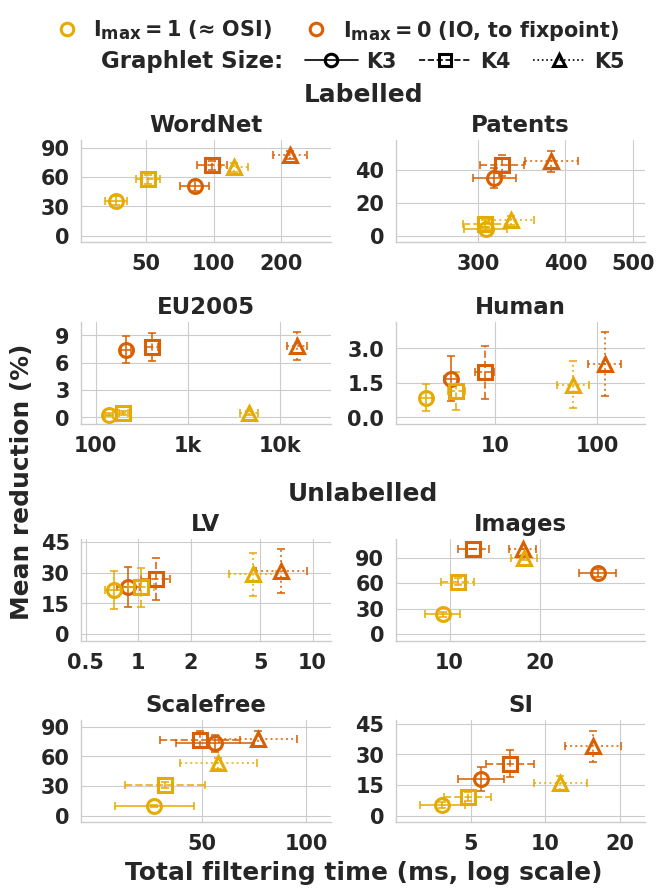

In [6]:
def fig_filter_tradeoff():
    setup(6.6)
    SHOWN = {"imsm": ["wordnet", "patents", "eu2005", "human"],
             "mccreesh": ["LV", "images-CVIU11", "scalefree", "si"]}
    MODES2 = ["OrbitSI", "IterOrbit"]
    Z = 1.96
    # markers as in sota_filter.pdf: hollow, in the cactus plots' darker Dark2 colours (I_max=1 ~ OrbitSI's,
    # the fixpoint IterOrbit's), with its marker size, edge width and confidence bars
    D = sns.color_palette("Dark2")
    COLOR = {"OrbitSI": D[5], "IterOrbit": D[1]}
    MS, EDGE = 10, 2.2
    CI_ALPHA, CI_WIDTH, CI_CAP = 0.8, 1.4, 3

    def tick(v, _):
        return f"{v / 1000:g}k" if v >= 1000 else f"{v:g}"

    def panel(ax, d, title):
        m = d.groupby(["mode", "graphlet_size"]).agg(
            x=("cost_ms", lambda c: gmean(c)), y=("reduction_pct", "mean"),
            lse=("cost_ms", lambda c: Z * np.log(np.clip(c, 1e-3, None)).std(ddof=1) / np.sqrt(len(c)) if len(c) > 1 else 0.0),
            yse=("reduction_pct", lambda r: Z * r.std(ddof=1) / np.sqrt(len(r)) if len(r) > 1 else 0.0),
        ).reset_index()
        m["x1"], m["x3"] = m.x / np.exp(m.lse), m.x * np.exp(m.lse)
        m["y1"], m["y3"] = m.y - m.yse, m.y + m.yse
        for _, r in m.iterrows():
            col, ls = COLOR[r["mode"]], SIZE_LINESTYLE[r.graphlet_size]
            _, _, bars = ax.errorbar(r.x, r.y, xerr=[[r.x - r.x1], [r.x3 - r.x]], yerr=[[r.y - r.y1], [r.y3 - r.y]],
                                     fmt="none", ecolor=col, elinewidth=CI_WIDTH, capsize=CI_CAP, capthick=CI_WIDTH,
                                     alpha=CI_ALPHA, zorder=2)
            for b in bars:
                b.set_linestyle(ls)
            ax.plot(r.x, r.y, marker=SIZE_MARKER[r.graphlet_size], markersize=MS, markerfacecolor="none",
                    markeredgecolor=col, markeredgewidth=EDGE, linestyle="none", zorder=3)
        ax.set_xscale("log")
        lo, hi = min(0.0, m.y1.min()), max(m.y.max(), m.y3.max())
        span = max(hi - lo, 1.0)
        ax.set_ylim(lo - 0.08 * span, hi + 0.12 * span)
        if hi < 1.0:
            ax.set_ylim(-0.25, 5)
        xmin, xmax = m.x1.min(), m.x3.max()
        pad = max((xmax / xmin) ** 0.12, 1.25)
        ax.set_xlim(xmin / pad, xmax * pad)
        decades = np.log10(ax.get_xlim()[1] / ax.get_xlim()[0])
        if decades < 0.6:
            ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=3))
        else:
            ax.xaxis.set_major_locator(mticker.LogLocator(base=10, subs=(1, 2, 5) if decades < 2.2 else (1,), numticks=12))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(tick))
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())
        ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=4))
        style_axis(ax, title, tick_size=10)
        ax.title.set_fontsize(fs(11))

    fig = plt.figure(figsize=(6.6, 8.8))
    BLOCK_GAP = 0.04
    gs = fig.add_gridspec(4, 2, hspace=0.78, wspace=0.26, top=0.85, bottom=0.075 + BLOCK_GAP, left=0.12, right=0.975)
    axes = [fig.add_subplot(gs[r, c]) for r in range(4) for c in range(2)]
    for ax in axes[4:]:
        p = ax.get_position()
        ax.set_position([p.x0, p.y0 - BLOCK_GAP, p.width, p.height])
    imsm = imsm_filtering(SHOWN["imsm"], MODES2)
    for ax, ds in zip(axes[:4], SHOWN["imsm"]):
        panel(ax, imsm[imsm.dataset == ds], LABEL[ds])
    mcc = mcc_filtering()
    mcc = common_patterns(mcc[~mcc.cheap_refuted & mcc["mode"].isin(MODES2)])
    for ax, ds in zip(axes[4:], SHOWN["mccreesh"]):
        panel(ax, mcc[mcc.dataset == ds], LABEL[ds])
    block_heading(fig, axes[:4], "Labelled", fontsize=12)
    block_heading(fig, axes[4:], "Unlabelled", fontsize=12)
    shared_ylabel(fig, axes, "Mean reduction (%)")
    shared_xlabel(fig, axes, "Total filtering time (ms, log scale)")
    mode_h = [plt.Line2D([0], [0], marker="o", linestyle="none", markersize=9, markerfacecolor="none",
                         markeredgecolor=COLOR[m], markeredgewidth=EDGE, label=MODE_LABEL[m]) for m in MODES2]
    size_h = [plt.Line2D([0], [0], marker=SIZE_MARKER[s], linestyle=SIZE_LINESTYLE[s], color="black", markersize=9,
                         markerfacecolor="none", markeredgecolor="black", markeredgewidth=EDGE, label=f"K{s}") for s in SIZES]
    leg = fig.legend(handles=mode_h, bbox_to_anchor=(0.5, 0.975), loc="center", ncol=2, frameon=False,
                     columnspacing=1.0, handletextpad=0.2)
    for t in leg.get_texts():
        t.set_fontweight("bold")
        t.set_fontsize(fs(10))
    legend_row(fig, "Graphlet Size:", size_h, 0.94, fontsize=10, columnspacing=1.0, handletextpad=0.4, handlelength=2.4)
    save(fig, "filter_tradeoff")


fig_filter_tradeoff()

### Figure `iteration_gain.pdf`
Per-round cost and gain of iterating in the end-to-end configuration (labelled g=4, solid to $I_{max}=3$;
unlabelled g=5 to the fixpoint).

Labelled, g=4
  dblp           n=100  rounds 1..6: r1 1.00x/0.0pp  r2 1.22x/9.1pp  r3 1.27x/9.9pp  r4 1.29x/10.0pp  r5 1.29x/10.0pp  r6 1.29x/10.0pp
  eu2005         n=100  rounds 1..6: r1 1.00x/0.0pp  r2 1.45x/6.6pp  r3 1.67x/7.2pp  r4 1.73x/7.3pp  r5 1.74x/7.3pp  r6 1.74x/7.3pp
  hprd           n=100  rounds 1..2: r1 1.00x/0.0pp  r2 1.01x/0.6pp
  human          n=100  rounds 1..4: r1 1.00x/0.0pp  r2 1.13x/0.8pp  r3 1.14x/0.8pp  r4 1.15x/0.8pp
  patents        n=100  rounds 1..6: r1 1.00x/0.0pp  r2 1.03x/31.8pp  r3 1.04x/35.3pp  r4 1.04x/35.5pp  r5 1.05x/35.5pp  r6 1.05x/35.6pp
  wordnet        n=100  rounds 1..12: r1 1.00x/0.0pp  r2 1.34x/13.6pp  r3 1.53x/14.0pp  r4 1.65x/14.0pp  r5 1.72x/14.1pp  r6 1.75x/14.1pp  ... r12 1.77x/14.1pp
  yeast          n=100  rounds 1..5: r1 1.00x/0.0pp  r2 1.24x/5.0pp  r3 1.31x/5.3pp  r4 1.32x/5.3pp  r5 1.33x/5.3pp
  youtube        n=100  rounds 1..10: r1 1.00x/0.0pp  r2 1.44x/8.6pp  r3 1.82x/10.7pp  r4 1.99x/11.2pp  r5 2.04x/11.3pp  r6 2.06x/11.4pp  

  LV             n= 68  rounds 1..19: r1 1.00x/0.0pp  r2 1.14x/1.0pp  r3 1.17x/1.2pp  r4 1.18x/1.3pp  r5 1.19x/1.3pp  r6 1.19x/1.4pp  ... r19 1.20x/1.8pp
  images-CVIU11  n=100  rounds 1..2: r1 1.00x/0.0pp  r2 1.00x/10.1pp
  meshes-CVIU11  n= 45  rounds 1..7: r1 1.00x/0.0pp  r2 1.02x/3.2pp  r3 1.02x/3.3pp  r4 1.02x/3.3pp  r5 1.02x/3.4pp  r6 1.02x/3.4pp  ... r7 1.02x/3.5pp
  scalefree      n= 80  rounds 1..3: r1 1.00x/0.0pp  r2 1.26x/24.9pp  r3 1.33x/24.9pp
  si             n=100  rounds 1..7: r1 1.00x/0.0pp  r2 1.34x/17.7pp  r3 1.48x/17.9pp  r4 1.51x/17.9pp  r5 1.52x/18.0pp  r6 1.52x/18.0pp  ... r7 1.52x/18.0pp


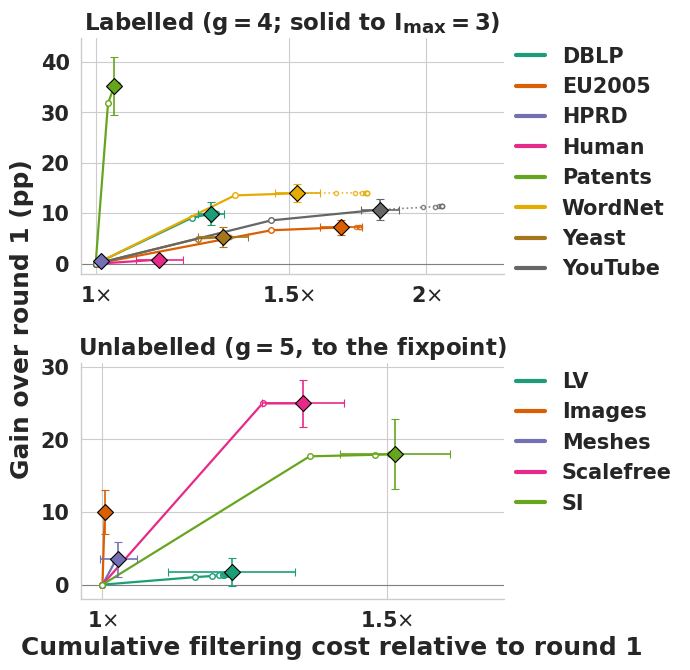

In [7]:
def fig_iteration_gain():
    setup(6.6)
    Z = 1.96
    E2E_ROUND = 3

    def trajectories(rounds_csv, g, datasets, drop=frozenset()):
        r = csv(rounds_csv)
        r = r[(r.graphlet_size == g) & r.dataset.isin(datasets)]
        r = r[[k not in drop for k in zip(r.dataset, r.pattern_name)]]
        out = []
        for ds, d in r.groupby("dataset"):
            T = int(d["round"].max())
            red = d.pivot_table(index="pattern_name", columns="round", values="pct_of_sj_baseline").reindex(columns=range(1, T + 1)).ffill(axis=1)
            cost = d.pivot_table(index="pattern_name", columns="round", values="cumulative_cost_ms").reindex(columns=range(1, T + 1)).ffill(axis=1)
            gain = red[[1]].values - red
            lratio = np.log(cost.clip(lower=1e-3).div(cost[1].clip(lower=1e-3), axis=0))
            for t in range(1, T + 1):
                out.append(pd.DataFrame({"dataset": ds, "round": t, "gain": gain[t], "lratio": lratio[t]}))
        return pd.concat(out, ignore_index=True)

    def panel(ax, p, datasets, title, mark_round=None):
        m = p.groupby(["dataset", "round"]).agg(
            gain=("gain", "mean"), gse=("gain", lambda x: Z * x.std(ddof=1) / np.sqrt(len(x))),
            lr=("lratio", "mean"), lse=("lratio", lambda x: Z * x.std(ddof=1) / np.sqrt(len(x))), n=("gain", "size"))
        colors = dict(zip(datasets, sns.color_palette("Dark2", 8)))
        for ds in datasets:
            r = m.loc[ds]
            T = r.index.max()
            k = min(mark_round or T, T)
            x, y = np.exp(r.lr), r.gain
            col = colors[ds]
            ax.plot(x.loc[:k], y.loc[:k], color=col, linewidth=1.6, marker="o", markersize=4, markerfacecolor="white",
                    markeredgecolor=col, zorder=2)
            if T > k:
                ax.plot(x.loc[k:], y.loc[k:], color=col, linewidth=1.2, linestyle="dotted", marker="o", markersize=3,
                        markerfacecolor="white", markeredgecolor=col, alpha=0.8, zorder=2)
            e = r.loc[k]
            xc = np.exp(e.lr)
            ax.errorbar(xc, e.gain, xerr=[[xc - xc / np.exp(e.lse)], [xc * np.exp(e.lse) - xc]], yerr=e.gse,
                        fmt=TOOL_MARKER["IterOrbit"], markersize=8, markerfacecolor=col, markeredgecolor="black",
                        markeredgewidth=0.8, ecolor=col, elinewidth=1.2, capsize=3, capthick=1.2, zorder=4)
            last = r.loc[T]
            print(f"  {ds:14s} n={int(e.n):3d}  rounds 1..{T}: " + "  ".join(f"r{t} {np.exp(r.loc[t].lr):.2f}x/{r.loc[t].gain:.1f}pp" for t in r.index[: min(T, 6)])
                  + (f"  ... r{T} {np.exp(last.lr):.2f}x/{last.gain:.1f}pp" if T > 6 else ""))
        ax.set_xscale("log")
        ax.axhline(0, color="gray", linewidth=0.8, zorder=1)
        ax.xaxis.set_major_locator(mticker.FixedLocator([1, 1.5, 2, 3, 4, 5]))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}" + r"$\times$"))
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())
        ax.set_xlim(0.97, np.exp(m.lr + m.lse).max() * 1.08)
        ax.set_ylim(-2, (m.gain + m.gse).max() * 1.08)
        style_axis(ax, title)
        handles = [plt.Line2D([0], [0], color=colors[ds], linewidth=3, label=LABEL[ds]) for ds in datasets]
        leg = ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=fs(10),
                        handlelength=1.4, borderaxespad=0)
        for t in leg.get_texts():
            t.set_fontweight("bold")

    fig, axes = plt.subplots(2, 1, figsize=(6.6, 6.6))
    print("Labelled, g=4")
    panel(axes[0], trajectories("labelled_filter_fixpoint_rounds.csv", 4, PLOT_IMSM), PLOT_IMSM,
          r"Labelled ($\mathbf{g=4}$; solid to $\mathbf{I_{max}=3}$)", E2E_ROUND)
    mcc = mcc_filtering()
    cheap = mcc[(mcc["mode"] == "IterOrbit") & (mcc.graphlet_size == 5) & mcc.cheap_refuted]
    print("Unlabelled, g=5")
    panel(axes[1], trajectories("unlabelled_filter_fixpoint_rounds.csv", 5, MCC, frozenset(zip(cheap.dataset, cheap.pattern_name))), MCC,
          r"Unlabelled ($\mathbf{g=5}$, to the fixpoint)")
    fig.subplots_adjust(top=0.95, bottom=0.1, left=0.12, right=0.76, hspace=0.38)
    shared_ylabel(fig, axes, "Gain over round 1 (pp)")
    fig.canvas.draw()
    y0 = fig.transFigure.inverted().transform(axes[1].get_tightbbox(fig.canvas.get_renderer()))[0][1]
    fig.text(0.5, y0 - 0.008, "Cumulative filtering cost relative to round 1", ha="center", va="top",
             fontweight="bold", fontsize=fs(12))
    save(fig, "iteration_gain")


fig_iteration_gain()

### Figure `refutation.pdf`
Unsatisfiable unlabelled pairs proved so by filtering alone (LV, Images, Meshes; Scalefree and SI pairs all
have embeddings): IterOrbit (g=5 to the fixpoint, its configuration here), OrbitSI, RapidMatch, DP-iso, VEQ and
CaLiG, and Glasgow before any search (its decision runs with 0 search nodes). DP-iso's refutations come from its
filter-only run (its end-to-end build prints no candidate sets on this benchmark).

OrbitSI filter finished 480/480 pairs
GraphQL filter finished 480/480 pairs
tool order (overall geo ms): VEQ 159, CaLiG 103, RM 21, DP-iso 16.1, OrbitSI 8.15, IterOrbit 8.65
LV: 60 unsatisfiable; cheap filters refute 53%
  VEQ        26.7%
  CaLiG      28.3%
  RM         53.3%
  DP-iso     53.3%
  GraphQL    68.3%
  Glasgow    63.3%
  OrbitSI    76.7%
  IterOrbit  85.0%
images-CVIU11: 100 unsatisfiable; cheap filters refute 0%
  VEQ        17.0%
  CaLiG      27.0%
  RM          0.0%
  DP-iso      0.0%
  GraphQL    13.0%
  Glasgow    16.0%
  OrbitSI    19.0%


  IterOrbit 100.0%
meshes-CVIU11: 100 unsatisfiable; cheap filters refute 55%
  VEQ        92.0%
  CaLiG      93.0%
  RM         55.0%
  DP-iso     55.0%
  GraphQL    99.0%
  Glasgow   100.0%
  OrbitSI    51.0%
  IterOrbit 100.0%


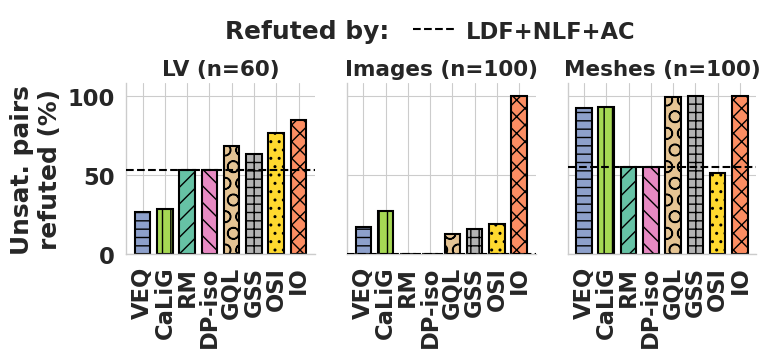

In [8]:
def fig_refutation():
    setup(7.2)
    FAMILIES = ["LV", "images-CVIU11", "meshes-CVIU11"]
    OTHERS = ["OrbitSI", "RM", "DP-iso", "VEQ", "CaLiG"]
    OTHER_HATCH = {"OrbitSI": "..", "RM": "//", "DP-iso": "\\\\", "VEQ": "--", "CaLiG": "||", GRAPHQL: "O"}
    gqf = graphql_filter("mccreesh")
    d = mcc_filtering()
    gt = csv("unlabelled_glasgow_ground_truth.csv", dtype={"glasgow_status": str})
    unsat = gt[gt.glasgow_status.astype(str).str.lower() == "false"]
    n_unsat = unsat.groupby("dataset").size()
    unsat_keys = set(zip(unsat.dataset, unsat.pattern_name))
    ref = d[d.outcome == "refuted"]
    assert all(k in unsat_keys for k in zip(ref.dataset, ref.pattern_name)), "a refuted pair is satisfiable"
    osi = orbitsi_filter("mccreesh")
    print(f"OrbitSI filter finished {len(osi)}/480 pairs")
    s = csv("unlabelled_sota_filter_candidates.csv")
    other_ref = pd.concat([osi[osi.refuted].assign(tool="OrbitSI")[["tool", "dataset", "pattern_name"]],
                           s[s.refuted == True][["tool", "dataset", "pattern_name"]]], ignore_index=True)   # noqa: E712
    if gqf is not None:
        print(f"GraphQL filter finished {int((gqf.status == 'COMPLETED').sum())}/480 pairs")
        other_ref = pd.concat([other_ref, gqf[gqf.refuted].assign(tool=GRAPHQL)[["tool", "dataset", "pattern_name"]]],
                              ignore_index=True)
    bad = [k for k in zip(other_ref.tool, other_ref.dataset, other_ref.pattern_name) if k[1:] not in unsat_keys]
    assert not bad, f"refuted pairs that are satisfiable: {bad[:5]}"

    # IterOrbit's end-to-end configuration on this benchmark: g=5 to the fixpoint
    io = ref[(ref["mode"] == "IterOrbit") & (ref.graphlet_size == 5)].assign(tool="IterOrbit")
    other_ref = pd.concat([other_ref, io[["tool", "dataset", "pattern_name"]]], ignore_index=True)
    # Glasgow has no separate filter: count the pairs it proves unsatisfiable before any search (nodes = 0, i.e.
    # its domain initialisation and root propagation fail; it counts the root as the first node)
    gl = unsat[unsat.glasgow_nodes == 0].assign(tool="Glasgow")
    other_ref = pd.concat([other_ref, gl[["tool", "dataset", "pattern_name"]]], ignore_index=True)
    systems = [t for t in plot_tool_order() if t in OTHERS]
    systems = systems[:-1] + ([GRAPHQL] if gqf is not None else []) + ["Glasgow", "OrbitSI", "IterOrbit"]   # OrbitSI, IterOrbit last
    hatch = {**OTHER_HATCH, "IterOrbit": "xx", "Glasgow": "++"}
    color = {**TOOL_COLOR, "Glasgow": S[7]}
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.0), sharey=True)
    xs = np.arange(len(systems))
    for ax, fam in zip(axes, FAMILIES):
        n = int(n_unsat[fam])
        r = ref[ref.dataset == fam]
        cheap = 100.0 * r[r.cheap_refuted].pattern_name.nunique() / n
        print(f"{fam}: {n} unsatisfiable; cheap filters refute {cheap:.0f}%")
        for x, t in zip(xs, systems):
            v = 100.0 * other_ref[(other_ref.tool == t) & (other_ref.dataset == fam)].pattern_name.nunique() / n
            print(f"  {t:9s} {v:5.1f}%")
            ax.bar(x, v, width=0.7, color=color[t], edgecolor="black", linewidth=1.5, hatch=hatch[t], zorder=2)
        ax.axhline(cheap, color="black", linestyle="--", linewidth=1.5, zorder=3)
        ax.set_xticks(xs)
        ax.set_xticklabels([SHORT.get(t, t) for t in systems], rotation=90)
        ax.set_ylim(0, 108)
        ax.set_yticks([0, 50, 100])
        style_axis(ax, f"{LABEL[fam]} (n={n})")
        ax.title.set_fontsize(fs(9.5))
    for ax in axes[1:]:
        ax.tick_params(labelleft=False)
    axes[0].set_ylabel("Unsat. pairs\nrefuted (%)", fontweight="bold", fontsize=fs(11))
    fig.subplots_adjust(top=0.79, bottom=0.22, left=0.115, right=0.99, wspace=0.17)
    lines = [plt.Line2D([0], [0], color="black", linestyle="--", linewidth=1.5, label="LDF+NLF+AC")]
    legend_row(fig, "Refuted by:", lines, 0.965, columnspacing=1.0, handletextpad=0.4, handlelength=1.8)
    save(fig, "refutation")


fig_refutation()

## Counting end to end (Table `tab:count`)
All eight labelled graphs and the five unlabelled families: IterOrbit, IterOrbit without its search
accelerations, the OrbitSI package's published configuration, RM, DP-iso, VEQ and CaLiG.

In [9]:
SIX = PLOT_TOOLS                     # IterOrbit, OrbitSI, RM, DP-iso, VEQ, CaLiG
OTHERS = SIX[1:]
NO_ACC = "IterOrbit (no acc.)"


def e2e_times(bench, datasets):
    """The counting runs of one benchmark: (long frame with t, instance x tool pivot of t), every system plus
    IterOrbit without its search accelerations."""
    loader = (lambda: imsm_phases(datasets)) if bench == "imsm" else mcc_phases
    d = with_index(pd.concat([loader(), orbitsi_phases(bench)], ignore_index=True), bench)
    d = d[d.dataset.isin(datasets)]
    raw = iterorbit_sweep("no_accel", bench)[["dataset", "pattern_name", "status", "filter", "order", "enumerate"]]
    na = raw[(raw.status == "COMPLETED") & raw.dataset.isin(datasets)].assign(tool=NO_ACC, read=0.0, index=0.0)
    na[["order", "enumerate"]] = na[["order", "enumerate"]].fillna(0)
    d = pd.concat([d, na], ignore_index=True)
    d["t"] = phase_time(d)
    return d, d.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")


def e2e_section():
    """Every number of the "End-to-End Performance" subsection: per benchmark, completed, fastest and
    IterOrbit's speed-up over each system; per dataset, the geometric means over the instances all six completed."""

    def speedup(t, a, ref="IterOrbit"):
        k = t[a].notna() & t[ref].notna()
        r = t[a][k] / t[ref][k]
        return f"{gmean(r):.2f}x ({(r > 1).sum()}/{(r < 1).sum()})"

    def report(bench, datasets, keys_total):
        d, t = e2e_times(bench, datasets)
        t = t.reindex(pd.MultiIndex.from_tuples(keys_total, names=["dataset", "pattern_name"]))
        six = t[SIX]
        fastest = six.eq(six.min(axis=1), axis=0).sum()
        print(f"\n==== {BENCH[bench]} ({len(t)} instances)")
        for s in SIX + [NO_ACC]:
            line = f"  {s:20s} done {int(t[s].notna().sum()):3d}"
            if s in SIX:
                line += f"  fastest {int(fastest[s]):3d}"
            if s != "IterOrbit":
                line += f"  speed-up of IterOrbit over it {speedup(t, s)}"
            if s in OTHERS:
                line += f"  | over it, IterOrbit without acc. {speedup(t, s, NO_ACC)}"
            print(line)
        only = t.IterOrbit.notna() & t[OTHERS].isna().all(axis=1)
        print(f"  completed by IterOrbit and none of the other five: {int(only.sum())}; by none of the six: {int(six.isna().all(axis=1).sum())}")
        keys = all_completed(d, SIX)
        print("  per dataset (geo ms over all-six-completed; IterOrbit filter share; fastest and runner-up):")
        for ds in datasets:
            x = d[(d.dataset == ds) & [k in keys for k in zip(d.dataset, d.pattern_name)]]
            g = {s: gmean(x[x.tool == s].t, TIME_FLOOR_MS) for s in SIX}
            order = sorted(SIX, key=g.get)
            io = x[x.tool == "IterOrbit"]
            share = (io["filter"] / phase_time(io)).mean()
            idx = {s: (x[x.tool == s]["index"] / x[x.tool == s].t).mean() for s in OTHERS}
            print(f"    {LABEL[ds]:10s} n={len(io):3d}  " + "  ".join(f"{s} {g[s]:.3g}" for s in SIX)
                  + f"  | fastest {order[0]}, {g[order[1]] / g[order[0]]:.2f}x ahead of {order[1]}"
                  + (f"; IterOrbit {g['IterOrbit'] / g[order[0]]:.2f}x behind" if order[0] != "IterOrbit" else "")
                  + f" | IO filter share {100 * share:.0f}% | index share " + " ".join(f"{s} {100 * v:.0f}%" for s, v in idx.items()))
            f = six.loc[ds]
            print(f"    {'':10s} fastest counts (all {len(f)}): " + " ".join(f"{s} {int(f.eq(f.min(axis=1), axis=0).sum()[s])}" for s in SIX))
        return t

    tabs = {"imsm": report("imsm", IMSM_ALL, instance_keys("imsm")),
            "mccreesh": report("mccreesh", MCC, instance_keys("mccreesh"))}
    s = csv("labelled_sota_runs.csv")
    g = s.groupby("dataset")[["data_vertices", "data_edges", "data_num_labels"]].first()
    g["avg_deg"] = 2 * g.data_edges / g.data_vertices
    print("\nlabelled data graphs:\n" + g.to_string())
    return tabs


e2e_section();


==== Labelled (800 instances)
  IterOrbit            done 472  fastest 165
  OrbitSI              done 458  fastest  94  speed-up of IterOrbit over it 1.69x (309/147)  | over it, IterOrbit without acc. 1.49x (293/163)
  RM                   done 467  fastest 119  speed-up of IterOrbit over it 1.50x (311/153)  | over it, IterOrbit without acc. 1.32x (266/197)
  DP-iso               done 422  fastest  81  speed-up of IterOrbit over it 3.56x (285/137)  | over it, IterOrbit without acc. 3.31x (317/105)
  VEQ                  done 347  fastest  27  speed-up of IterOrbit over it 8.41x (317/19)  | over it, IterOrbit without acc. 8.30x (316/19)
  CaLiG                done 436  fastest   2  speed-up of IterOrbit over it 24.56x (431/4)  | over it, IterOrbit without acc. 22.38x (431/3)
  IterOrbit (no acc.)  done 463  speed-up of IterOrbit over it 1.13x (201/262)
  completed by IterOrbit and none of the other five: 6; by none of the six: 313
  per dataset (geo ms over all-six-completed; IterOrbi

    Meshes     n=100  IterOrbit 2.01  OrbitSI 0.753  RM 11  DP-iso 1.69  VEQ 28.5  CaLiG 4.35  | fastest OrbitSI, 2.24x ahead of DP-iso; IterOrbit 2.67x behind | IO filter share 98% | index share OrbitSI 5% RM 1% DP-iso 7% VEQ 2% CaLiG 3%
               fastest counts (all 100): IterOrbit 9 OrbitSI 76 RM 0 DP-iso 15 VEQ 0 CaLiG 1
    Scalefree  n= 38  IterOrbit 42.5  OrbitSI 9.6  RM 161  DP-iso 384  VEQ 3.75e+03  CaLiG 316  | fastest OrbitSI, 4.42x ahead of IterOrbit; IterOrbit 4.42x behind | IO filter share 88% | index share OrbitSI 0% RM 0% DP-iso 0% VEQ 0% CaLiG 0%
               fastest counts (all 80): IterOrbit 2 OrbitSI 75 RM 0 DP-iso 0 VEQ 0 CaLiG 3
    SI         n= 57  IterOrbit 24.5  OrbitSI 22.4  RM 46.3  DP-iso 79.9  VEQ 746  CaLiG 200  | fastest OrbitSI, 1.09x ahead of IterOrbit; IterOrbit 1.09x behind | IO filter share 36% | index share OrbitSI 0% RM 0% DP-iso 0% VEQ 0% CaLiG 0%
               fastest counts (all 100): IterOrbit 50 OrbitSI 37 RM 5 DP-iso 4 VEQ 0 CaLiG 0


### Sensitivity to the index charge, counting (Section `subsec:counting`)
IterOrbit's speed-up and fastest counts with each system's index build charged in full (as in the paper),
shared by a data graph's 100 patterns, and fully amortised.

In [10]:
def index_amortised():
    SCALES = (("charged", 1.0), ("shared by 100 patterns", 0.01), ("fully amortised", 0.0))

    def pivot(d0, scale):
        d = d0.assign(index=d0["index_full"] * scale)
        d["t"] = phase_time(d)
        return d.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first").reindex(columns=SIX)

    def summary(t):
        sp = []
        for s in SIX[1:]:
            k = t[s].notna() & t["IterOrbit"].notna()
            sp.append(f"{SHORT.get(s, s)} {gmean(t[s][k] / t['IterOrbit'][k]):6.2f}x")
        f = t.eq(t.min(axis=1), axis=0).sum()
        return "  ".join(sp) + "  | fastest " + ", ".join(f"{SHORT.get(s, s)} {int(f[s])}" for s in SIX)

    out = {}
    for bench, datasets in (("imsm", IMSM_ALL), ("mccreesh", MCC)):
        d0, _ = e2e_times(bench, datasets)
        d0 = d0[d0.tool.isin(SIX)].copy()
        print(f"\n==== {BENCH[bench]}")
        tabs = {name: pivot(d0, sc) for name, sc in SCALES}
        out[bench] = tabs
        for name, _ in SCALES:
            print(f"  {name:24s} {summary(tabs[name])}")
        if bench != "imsm":
            continue
        rm = d0[d0.tool == "RM"].assign(t=lambda x: x["filter"] + x["order"] + x["enumerate"] + x["index_full"])
        share = (rm["index_full"] / rm["t"]).groupby(rm.dataset).median()
        print("  per dataset (index share of RM's time, median):")
        for ds in datasets:
            print(f"   {LABEL[ds]:9s} {100 * share[ds]:3.0f}%")
            for name in ("charged", "fully amortised"):
                print(f"     {name:16s} {summary(tabs[name].loc[ds])}")
    return out


index_amortised();


==== Labelled
  charged                  OSI   3.00x  RM   3.10x  DP-iso   8.95x  VEQ  14.41x  CaLiG  33.21x  | fastest IO 364, OSI 29, RM 63, DP-iso 3, VEQ 26, CaLiG 2
  shared by 100 patterns   OSI   1.66x  RM   1.46x  DP-iso   3.47x  VEQ   8.35x  CaLiG  24.55x  | fastest IO 160, OSI 93, RM 123, DP-iso 83, VEQ 27, CaLiG 2
  fully amortised          OSI   1.64x  RM   1.43x  DP-iso   3.37x  VEQ   8.26x  CaLiG  24.41x  | fastest IO 151, OSI 91, RM 124, DP-iso 93, VEQ 27, CaLiG 2
  per dataset (index share of RM's time, median):
   DBLP       50%
     charged          OSI   2.18x  RM   2.27x  DP-iso   7.95x  VEQ   3.15x  CaLiG  27.83x  | fastest IO 12, OSI 0, RM 1, DP-iso 0, VEQ 10, CaLiG 0
     fully amortised  OSI   1.28x  RM   0.81x  DP-iso   3.93x  VEQ   1.99x  CaLiG  26.23x  | fastest IO 4, OSI 0, RM 8, DP-iso 0, VEQ 11, CaLiG 0
   EU2005     85%
     charged          OSI   4.66x  RM   4.40x  DP-iso  10.66x  VEQ  11.87x  CaLiG 119.38x  | fastest IO 4, OSI 0, RM 1, DP-iso 0, VEQ 2, 


==== Unlabelled
  charged                  OSI   0.64x  RM   3.99x  DP-iso   2.47x  VEQ  37.33x  CaLiG   8.69x  | fastest IO 105, OSI 313, RM 5, DP-iso 37, VEQ 9, CaLiG 12
  shared by 100 patterns   OSI   0.62x  RM   3.96x  DP-iso   2.36x  VEQ  36.91x  CaLiG   8.57x  | fastest IO 102, OSI 310, RM 5, DP-iso 43, VEQ 9, CaLiG 12
  fully amortised          OSI   0.62x  RM   3.96x  DP-iso   2.36x  VEQ  36.90x  CaLiG   8.57x  | fastest IO 102, OSI 310, RM 5, DP-iso 46, VEQ 13, CaLiG 15


### Figure `cactus.pdf`
Instances completed within each time, per benchmark; the Glasgow solver on the unlabelled benchmark.

Labelled: instances completed  VEQ 347  CaLiG 436  RM 467  DP-iso 422  OrbitSI 458  IterOrbit 472  GraphQL 361


Unlabelled: instances completed  VEQ 351  CaLiG 417  RM 431  DP-iso 391  OrbitSI 435  IterOrbit 444  GraphQL 408  Glasgow 437
legend: Glasgow placed by 350 pairs all seven completed: VEQ 260, CaLiG 56.4, RM 25.5, DP-iso 14.3, OrbitSI 5.47, IterOrbit 7.84, Glasgow 14.8
legend: GraphQL placed by 671 instances all completed: VEQ 187, CaLiG 111, RM 31.2, DP-iso 25.6, OrbitSI 10.9, IterOrbit 7.85, GraphQL 33.6


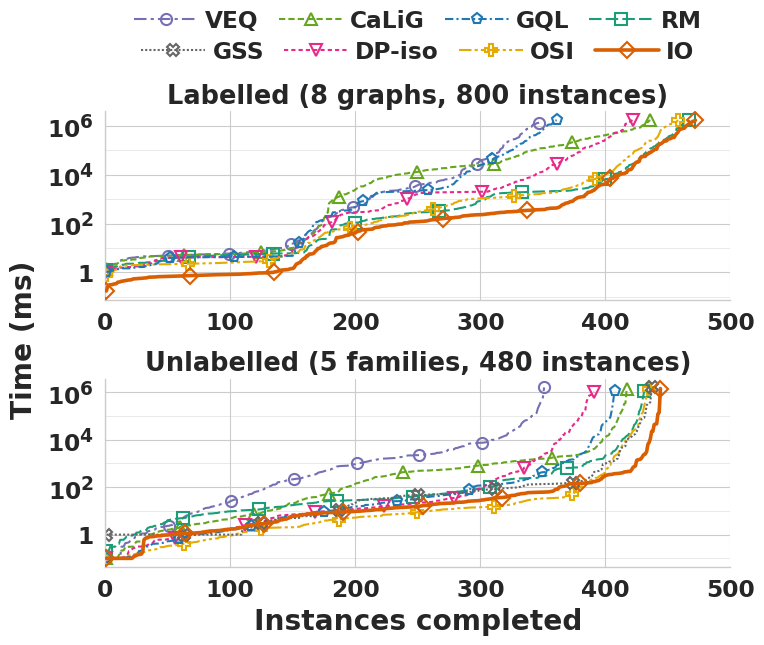

In [11]:
CACTUS_D = sns.color_palette("Dark2")
CACTUS_COLOR = {"IterOrbit": CACTUS_D[1], "RM": CACTUS_D[0], "VEQ": CACTUS_D[2], "DP-iso": CACTUS_D[3], "CaLiG": CACTUS_D[4],
                "OrbitSI": CACTUS_D[5], "Glasgow": CACTUS_D[7], "GuP": CACTUS_D[6],
                "GraphQL": "#1f78b4"}   # all eight Dark2 colours are taken: ColorBrewer's dark blue (Dark2 has no blue)
CACTUS_MARKER = {**TOOL_MARKER, "Glasgow": "X", "GuP": "h"}


def place_by_gmean(order, tool, t):
    """order with tool inserted by geometric mean over the rows of t (instances x systems, every column of order +
    [tool] present) that all of them completed, slowest first, the last two (OrbitSI, IterOrbit) kept last."""
    t = t[[c for c in order + [tool] if c in t.columns]].dropna()
    g = {c: gmean(t[c]) for c in t.columns}
    i = min(next((k for k, c in enumerate(order) if c in g and g[c] < g[tool]), len(order)), len(order) - 2)
    print(f"legend: {tool} placed by {len(t)} instances all completed: " + ", ".join(f"{c} {g[c]:.3g}" for c in t.columns))
    return order[:i] + [tool] + order[i:]
CACTUS_LINE_WIDTH = {"IterOrbit": 2.6}
CACTUS_DEFAULT_WIDTH = 1.5
# IterOrbit solid; every other system thinner, with its own dash pattern
CACTUS_LINE_STYLE = {"IterOrbit": "solid", "RM": (0, (6, 2)), "DP-iso": (0, (2, 1.5)), "VEQ": (0, (6, 2, 1.5, 2)),
                     "CaLiG": (0, (3, 1.5)), "OrbitSI": (0, (6, 1.5, 1.5, 1.5, 1.5, 1.5)), "Glasgow": (0, (1, 1)),
                     "GuP": (0, (9, 2)), "GraphQL": (0, (4, 1.5, 1, 1.5))}
CACTUS_N_MARKERS = 8


def _cactus_line(ax, t, y):
    ax.plot(np.arange(1, len(y) + 1), y, color=CACTUS_COLOR[t], marker=CACTUS_MARKER[t],
            markevery=np.unique(np.linspace(0, len(y) - 1, CACTUS_N_MARKERS).astype(int)).tolist(),
            markerfacecolor="none", markeredgecolor=CACTUS_COLOR[t], markeredgewidth=1.5,
            markersize=8, linewidth=CACTUS_LINE_WIDTH.get(t, CACTUS_DEFAULT_WIDTH), linestyle=CACTUS_LINE_STYLE[t],
            zorder=3 if t == "IterOrbit" else 2, label=SHORT.get(t, t))


def _cactus_axis(ax):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.FixedLocator([1, 1e2, 1e4, 1e6]))
    ax.yaxis.set_minor_locator(mticker.LogLocator(base=10, subs=(1.0,), numticks=12))
    ax.grid(which="minor", axis="y", linewidth=0.5, alpha=0.6)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(ms_tick))
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())


def _cactus_finish(fig, axes, order, name):
    fig.subplots_adjust(top=0.83, bottom=0.095, left=0.13, right=0.975, hspace=0.42)
    for ax in axes:
        style_axis(ax)
    axes[1].set_xlabel("Instances completed", fontweight="bold", fontsize=fs(12))
    handles = [plt.Line2D([0], [0], color=CACTUS_COLOR[t], marker=CACTUS_MARKER[t], markerfacecolor="none",
                          markeredgecolor=CACTUS_COLOR[t], markeredgewidth=1.5, markersize=8,
                          linewidth=CACTUS_LINE_WIDTH.get(t, CACTUS_DEFAULT_WIDTH), linestyle=CACTUS_LINE_STYLE[t],
                          label=SHORT.get(t, t)) for t in order]
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    inv = fig.transFigure.inverted()
    left = min(inv.transform(ax.get_tightbbox(r))[0][0] for ax in axes)
    top, bottom = axes[0].get_position(), axes[1].get_position()
    fig.text(left - 0.012, (top.y1 + bottom.y0) / 2, "Time (ms)", rotation=90, ha="right", va="center",
             weight="bold", fontsize=fs(12))
    for row, y in ((handles[:4], 0.976), (handles[4:], 0.926)):
        leg = fig.legend(handles=row, bbox_to_anchor=((top.x0 + top.x1) / 2, y), loc="center",
                         ncol=len(row), frameon=False, borderpad=0, borderaxespad=0,
                         columnspacing=0.8, handletextpad=0.3, handlelength=2.6)
        for text in leg.get_texts():
            text.set_fontweight("bold")
            text.set_fontsize(fs(10))
    save(fig, name)


CACTUS_TITLE = {"imsm": f"Labelled ({len(PLOT_IMSM)} graphs, 800 instances)",
                "mccreesh": f"Unlabelled ({len(MCC)} families, 480 instances)"}


def fig_cactus():
    setup(7.4)
    GLASGOW, FLOOR = "Glasgow", 1.0
    g = glasgow_runs()
    g = g[g.decided & g.index.get_level_values(0).isin(MCC)]
    glasgow = g.runtime.clip(lower=FLOOR)

    def legend_order(mcc):
        order = plot_tool_order()
        t = mcc.assign(t=phase_time(mcc)).pivot_table(index=["dataset", "pattern_name"], columns="tool",
                                                       values="t", aggfunc="first")[order]
        t[GLASGOW] = glasgow.reindex(t.index)
        t = t.dropna().clip(lower=FLOOR)
        gm = {c: gmean(t[c]) for c in t.columns}
        i = min(next((k for k, c in enumerate(order) if gm[c] < gm[GLASGOW]), len(order)), len(order) - 2)
        print(f"legend: Glasgow placed by {len(t)} pairs all seven completed: " + ", ".join(f"{c} {gm[c]:.3g}" for c in t.columns))
        return order[:i] + [GLASGOW] + order[i:]

    fig, axes = plt.subplots(2, 1, figsize=(7.4, 6.2))
    pooled = []
    for ax, (bench, loader, datasets) in zip(axes, [("imsm", lambda: imsm_phases(PLOT_IMSM), PLOT_IMSM),
                                                     ("mccreesh", mcc_phases, MCC)]):
        frames = [loader(), orbitsi_phases(bench), graphql_phases(bench, "count")]
        d = with_index(pd.concat([f for f in frames if f is not None], ignore_index=True), bench, charge=E2E_INDEX_CHARGE)
        sub = d[d.dataset.isin(datasets)]
        pooled.append(sub.assign(bench=bench))
        series = {t: np.sort(phase_time(sub[sub.tool == t]).to_numpy()) for t in plot_tool_order() + [GRAPHQL]}
        if bench == "mccreesh":
            series[GLASGOW] = np.sort(glasgow.to_numpy())
        done = {}
        for t, y in series.items():
            done[t] = len(y)
            if len(y):
                _cactus_line(ax, t, y)
        _cactus_axis(ax)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=6, integer=True))
        style_axis(ax, CACTUS_TITLE[bench])
        print(f"{BENCH[bench]}: instances completed  " + "  ".join(f"{t} {n}" for t, n in done.items()))
        if bench == "mccreesh":
            order = legend_order(sub)
        ax.set_xlim(0, 500)
        ax.xaxis.set_major_locator(mticker.MultipleLocator(100))
    if all(len(p[p.tool == GRAPHQL]) for p in pooled):
        x = pd.concat(pooled, ignore_index=True)
        x["t"] = phase_time(x)
        order = place_by_gmean(order, GRAPHQL, x.pivot_table(index=["bench", "dataset", "pattern_name"], columns="tool",
                                                              values="t", aggfunc="first"))
    _cactus_finish(fig, axes, order, "cactus")


fig_cactus()

### Figures `e2e_phases.pdf` (counting) and `e2e_phases_enum.pdf` (enumeration)
Shifted geometric-mean time per dataset and system (shift `SGM_SHIFT_MS`, 10 s), over the instances some system
in the row solved, an unsolved one counted at the time limit, with 95% bootstrap intervals. Each bar is divided
exactly in log space: log((SGM + s) / s) is the mean of log(1 + t_i / s) over the instances, each solved
instance's term split by its phases' shares of its time, each unsolved one's term going to "Unsolved".
Above each panel: the instances on which each system is the fastest (leaders bold; rotated in
`e2e_phases_enum.pdf` to fit seven or eight bars in one row); in each x label: the instances it completed (the
most completed in bold). GraphQL is in a row once its sweep on that benchmark is complete (graphql_phases). GuP's
rejected unlabelled pairs (patterns over 256 vertices) count as unsolved for it.
`e2e_phases_enum.pdf` is not in the paper.


Labelled: shifted geometric-mean time (ms, shift 10 s, unsolved at 1800 s) and shares (index/filter/order/symmetry/enumerate/unsolved) over instances some system solved
  dblp           n= 23  VEQ 3.972e+04 [0/0/0/0/71/28]  CaLiG 1.226e+05 [0/2/0/0/1/96]  GraphQL 1.501e+05 [0/0/0/0/10/90]  RM 1.044e+05 [0/0/0/0/16/83]  DP-iso 1.156e+05 [0/0/0/0/2/98]  OrbitSI 1.09e+05 [0/0/0/0/18/82]  IterOrbit 9.477e+04 [0/0/0/0/33/67]
                 of 100: VEQ done 21 fastest 10  CaLiG done 12 fastest 0  GQL done 12 fastest 0  RM done 14 fastest 1  DP-iso done 12 fastest 0  OSI done 14 fastest 0  IO done 16 fastest 12
  eu2005         n=  7  VEQ 5.206e+04 [2/1/0/0/56/41]  CaLiG 1.683e+05 [1/27/0/0/21/52]  GraphQL 1.332e+05 [1/0/0/0/15/84]  RM 4.747e+04 [3/0/0/0/12/85]  DP-iso 8.082e+04 [2/0/0/0/31/67]  OrbitSI 4.847e+04 [2/0/0/0/13/84]  IterOrbit 4.558e+04 [0/0/0/0/13/87]
                 of 100: VEQ done 6 fastest 2  CaLiG done 5 fastest 0  GQL done 4 fastest 0  RM done 5 fastest 1  DP-iso done 

  hprd           n=100  VEQ 6.285 [57/38/1/0/4/0]  CaLiG 40.42 [9/5/0/0/86/0]  GraphQL 125.7 [3/0/0/0/97/0]  RM 6.933 [52/22/3/0/23/0]  DP-iso 28.75 [13/1/0/0/86/0]  OrbitSI 6.806 [25/9/0/0/67/0]  IterOrbit 1.675 [0/35/1/2/61/0]
                 of 100: VEQ done 100 fastest 1  CaLiG done 100 fastest 0  GQL done 100 fastest 0  RM done 100 fastest 0  DP-iso done 100 fastest 0  OSI done 100 fastest 0  IO done 100 fastest 99


  human          n= 18  VEQ 4.27e+04 [0/0/0/0/13/87]  CaLiG 1.456e+05 [0/0/0/0/5/95]  GraphQL 1.343e+05 [0/0/0/0/13/87]  RM 1.105e+05 [0/0/0/0/30/70]  DP-iso 1.5e+05 [0/0/0/0/6/94]  OrbitSI 1.128e+05 [0/0/0/0/19/81]  IterOrbit 5.109e+04 [0/0/0/0/68/32]
                 of 100: VEQ done 13 fastest 7  CaLiG done 9 fastest 0  GQL done 10 fastest 0  RM done 12 fastest 2  DP-iso done 9 fastest 0  OSI done 11 fastest 0  IO done 16 fastest 9
  patents        n= 87  VEQ 5.344e+04 [5/6/0/0/27/61]  CaLiG 2.916e+05 [1/83/0/0/6/11]  GraphQL 5.956e+04 [5/1/0/0/14/80]  RM 8636 [21/3/0/0/76/0]  DP-iso 1.999e+04 [11/2/0/0/61/27]  OrbitSI 8602 [11/8/0/0/71/10]  IterOrbit 7026 [0/5/0/0/62/34]
                 of 100: VEQ done 68 fastest 0  CaLiG done 81 fastest 0  GQL done 61 fastest 0  RM done 87 fastest 8  DP-iso done 82 fastest 1  OSI done 86 fastest 8  IO done 84 fastest 70


  wordnet        n= 94  VEQ 7.439e+05 [0/0/0/0/13/87]  CaLiG 3.344e+04 [0/56/0/0/26/19]  GraphQL 3.199e+05 [0/0/0/0/29/71]  RM 3828 [0/2/0/0/81/17]  DP-iso 4.72e+04 [0/0/0/0/49/51]  OrbitSI 5522 [0/1/0/0/86/13]  IterOrbit 2731 [0/3/0/0/97/0]
                 of 100: VEQ done 26 fastest 1  CaLiG done 89 fastest 1  GQL done 49 fastest 0  RM done 93 fastest 8  DP-iso done 78 fastest 1  OSI done 93 fastest 18  IO done 94 fastest 65
  yeast          n= 93  VEQ 8174 [0/0/0/0/34/65]  CaLiG 5903 [0/0/0/0/52/48]  GraphQL 8115 [0/0/0/0/44/56]  RM 3358 [0/0/0/0/81/19]  DP-iso 6224 [0/0/0/0/42/58]  OrbitSI 5326 [0/0/0/0/74/26]  IterOrbit 3083 [0/0/0/0/100/0]
                 of 100: VEQ done 86 fastest 5  CaLiG done 89 fastest 0  GQL done 87 fastest 1  RM done 92 fastest 17  DP-iso done 88 fastest 0  OSI done 91 fastest 3  IO done 93 fastest 67


  youtube        n= 65  VEQ 2.881e+05 [0/0/0/0/10/90]  CaLiG 9.03e+04 [0/15/0/0/36/49]  GraphQL 1.673e+05 [0/0/0/0/24/75]  RM 1.844e+04 [2/0/0/0/90/8]  DP-iso 7.753e+04 [1/0/0/0/37/63]  OrbitSI 3.128e+04 [1/1/0/0/59/39]  IterOrbit 1.94e+04 [0/1/0/0/92/7]
                 of 100: VEQ done 27 fastest 0  CaLiG done 51 fastest 1  GQL done 38 fastest 0  RM done 64 fastest 26  DP-iso done 48 fastest 1  OSI done 58 fastest 0  IO done 64 fastest 37



Unlabelled: shifted geometric-mean time (ms, shift 10 s, unsolved at 1800 s) and shares (index/filter/order/symmetry/enumerate/unsolved) over instances some system solved
  LV             n= 69  VEQ 1.492e+04 [0/0/0/0/26/74]  CaLiG 7256 [0/0/0/0/45/55]  RM 7249 [0/0/2/0/42/55]  GraphQL 9155 [0/0/0/0/42/58]  DP-iso 1.32e+04 [0/0/0/0/46/54]  OrbitSI 6217 [0/0/0/0/53/47]  IterOrbit 1006 [0/0/0/0/100/0]
                 of 100: VEQ done 60 fastest 9  CaLiG done 65 fastest 8  RM done 65 fastest 0  GQL done 64 fastest 18  DP-iso done 63 fastest 14  OSI done 66 fastest 29  IO done 69 fastest 41
  images-CVIU11  n=100  VEQ 8206 [0/15/0/0/50/35]  CaLiG 847.3 [0/100/0/0/0/0]  RM 37.38 [1/46/3/0/51/0]  GraphQL 260.9 [0/6/0/0/94/0]  DP-iso 21.32 [1/37/2/0/60/0]  OrbitSI 9.434 [1/97/0/0/2/0]  IterOrbit 17.38 [0/100/0/0/0/0]
                 of 100: VEQ done 96 fastest 0  CaLiG done 100 fastest 0  RM done 100 fastest 0  GQL done 100 fastest 0  DP-iso done 100 fastest 7  OSI done 100 fastest 93  IO 

  meshes-CVIU11  n=100  VEQ 479.6 [0/30/0/0/70/0]  CaLiG 8.95 [2/95/0/0/2/0]  RM 20.41 [1/78/2/0/19/0]  GraphQL 2.877 [7/88/1/0/4/0]  DP-iso 4.788 [4/43/1/0/52/0]  OrbitSI 1.647 [4/92/1/0/3/0]  IterOrbit 4.597 [0/100/0/0/0/0]
                 of 100: VEQ done 100 fastest 0  CaLiG done 100 fastest 1  RM done 100 fastest 0  GQL done 100 fastest 5  DP-iso done 100 fastest 12  OSI done 100 fastest 74  IO done 100 fastest 11
  scalefree      n= 80  VEQ 2.013e+05 [0/3/1/0/7/89]  CaLiG 1188 [0/92/0/0/8/0]  RM 2635 [0/9/3/0/32/56]  GraphQL 275.4 [0/30/0/0/70/0]  DP-iso 3.897e+04 [0/0/0/0/18/82]  OrbitSI 2234 [0/1/0/0/35/64]  IterOrbit 608 [0/18/0/0/82/0]
                 of 80: VEQ done 38 fastest 0  CaLiG done 80 fastest 1  RM done 78 fastest 0  GQL done 80 fastest 7  DP-iso done 60 fastest 0  OSI done 78 fastest 72  IO done 80 fastest 0


  si             n= 96  VEQ 9.458e+04 [0/0/0/0/10/90]  CaLiG 3.846e+04 [0/2/0/0/15/82]  RM 8790 [0/2/0/0/29/69]  GraphQL 6.094e+04 [0/0/0/0/12/88]  DP-iso 4.801e+04 [0/0/0/0/14/86]  OrbitSI 6616 [0/0/0/0/47/53]  IterOrbit 1928 [0/2/0/1/66/31]
                 of 100: VEQ done 57 fastest 0  CaLiG done 72 fastest 0  RM done 88 fastest 5  GQL done 64 fastest 2  DP-iso done 68 fastest 4  OSI done 91 fastest 35  IO done 95 fastest 50


figure 13.5 x 8.7 in drawn; at \textwidth 6.85 x 4.39 in


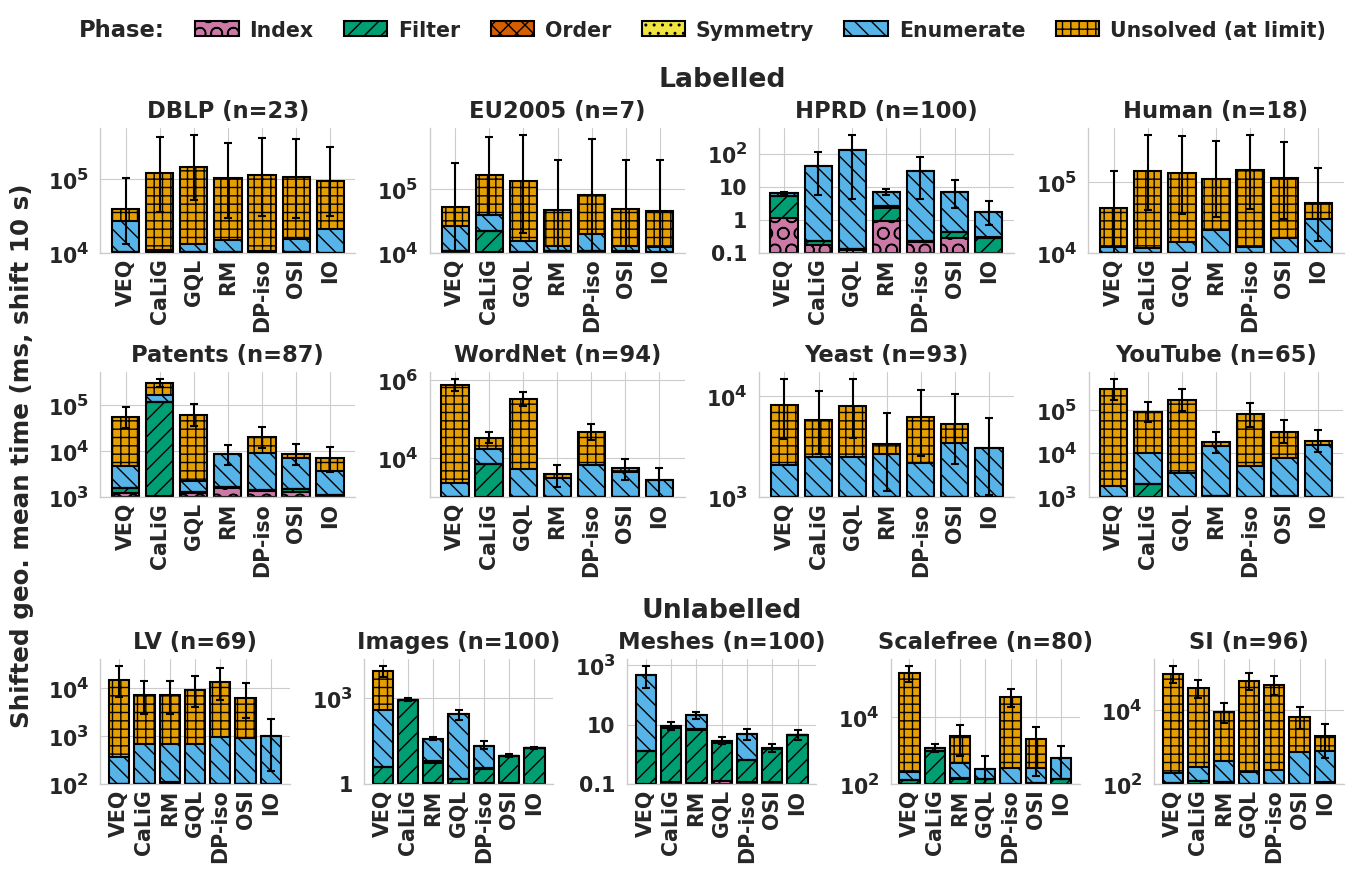

In [12]:
SGM_SHIFT_MS = 10_000.0      # shifted geometric mean: the shift (MIP benchmarking's usual 10 s)
TIME_LIMIT_MS = 1_800_000.0  # every end-to-end run's limit; an unsolved instance counts as this


def sgm(t, shift=SGM_SHIFT_MS):
    """Shifted geometric mean of times t (ms; NaN = unsolved, counted at TIME_LIMIT_MS)."""
    t = np.asarray(pd.Series(t).fillna(TIME_LIMIT_MS), dtype=float)
    return float(np.exp(np.log(t + shift).mean()) - shift)


def fig_e2e_phases(enum=False):
    N_BOOT = 2000
    PHASES = ((["read"] if INCLUDE_LOADING else []) + (["index"] if INCLUDE_INDEX else []) + ["filter", "order"]
              + (["symmetry"] if INCLUDE_SYMMETRY and not enum else []) + ["enumerate"])
    SEGMENTS = PHASES + ["unsolved"]
    PHASE_LABEL = {"read": "Read", "index": "Index", "filter": "Filter", "order": "Order", "symmetry": "Symmetry",
                   "enumerate": "Enumerate", "unsolved": "Unsolved (at limit)"}
    # Okabe-Ito (colour-blind safe); dark blue only for Read, which is off by default (hatching barely shows on it)
    PHASE_COLOR = {"filter": OKABE_ITO["bluish green"], "order": OKABE_ITO["vermillion"], "symmetry": OKABE_ITO["yellow"],
                   "enumerate": OKABE_ITO["sky blue"], "index": OKABE_ITO["reddish purple"], "read": OKABE_ITO["blue"],
                   "unsolved": OKABE_ITO["orange"]}
    PHASE_HATCH = {"filter": "//", "order": "xx", "symmetry": "..", "enumerate": "\\\\", "index": "O", "read": "--",
                   "unsolved": "++"}
    setup(13.5, TEXT_IN)
    XTICK_SIZE = 10
    PANEL_IN = 1.25         # drawn height of every panel's plot area (the figure is 13.5 in wide)
    LEGEND_IN = 0.55        # drawn room above the panels for the legend
    HEADING_IN = 0.42       # drawn room for "Labelled" / "Unlabelled"
    rng = np.random.default_rng(0)
    GUP = "GuP"
    if enum:
        enum_data = csv("enum_e2e.csv")
        enum_data = enum_data[enum_data.status == "COMPLETED"]
    sweep = "enum" if enum else "count"
    gql = {b: graphql_phases(b, sweep) for b in ("imsm", "mccreesh")}

    def load(bench):
        if enum:
            d = enum_data[enum_data.bench == bench].copy()
        else:
            loader = (lambda: imsm_phases(PLOT_IMSM)) if bench == "imsm" else mcc_phases
            d = pd.concat([loader(), orbitsi_phases(bench)], ignore_index=True)
        if gql[bench] is not None:
            d = pd.concat([d, gql[bench]], ignore_index=True)
        return with_index(d, bench, charge=E2E_INDEX_CHARGE)

    def universe(bench):
        """The instances a row's bars average over: every instance of the benchmark. The unlabelled pairs GuP
        rejects (patterns over 256 vertices) count as unsolved for it."""
        return set(instance_keys(bench))

    def insert(order, tool, bench):
        """order with tool placed by its geometric mean over the instances all of order + [tool] completed (as
        the order itself, slowest first), OrbitSI and IterOrbit kept last."""
        x = load(bench)
        x["t"] = phase_time(x)
        t = x.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")
        t = t.reindex(columns=[c for c in order + [tool] if c in t.columns]).dropna()
        g = {c: gmean(t[c]) for c in t.columns}
        i = min(next((k for k, c in enumerate(order) if c in g and g[c] < g[tool]), len(order)), len(order) - 2)
        return order[:i] + [tool] + order[i:]

    def bar_order(bench):
        order = list(plot_tool_order())
        if enum:
            x = pd.concat([with_index(enum_data[enum_data.bench == b], b, charge=E2E_INDEX_CHARGE) for b in ("imsm", "mccreesh")])
            x["t"] = phase_time(x)
            t = x.pivot_table(index=["bench", "dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")[order + [GUP]].dropna()
            g = {c: gmean(t[c]) for c in t.columns}
            i = min(next((k for k, c in enumerate(order) if g[c] < g[GUP]), len(order)), len(order) - 2)
            order = order[:i] + [GUP] + order[i:]
        if gql[bench] is not None:
            order = insert(order, GRAPHQL, bench)
        return order

    def summarise(d, keys, ds, tools):
        """Per tool: (SGM, CI low, CI high, segment shares, n) over the instances of keys on ds that some tool solved."""
        x = d[d.dataset == ds].assign(t=lambda f: phase_time(f))
        names = sorted(p for k, p in keys if k == ds)
        t = x.pivot_table(index="pattern_name", columns="tool", values="t", aggfunc="first").reindex(index=names, columns=tools)
        t = t[t.notna().any(axis=1)]
        out = {}
        for tool in tools:
            v = t[tool]
            logs = np.log(v.fillna(TIME_LIMIT_MS).to_numpy() + SGM_SHIFT_MS)
            boots = rng.choice(logs, size=(N_BOOT, len(logs)), replace=True).mean(axis=1)
            # exact split of log((SGM + s) / s) = mean_i log(1 + t_i / s)
            solved = v.dropna()
            ph = (x[x.tool == tool].set_index("pattern_name").reindex(solved.index)
                  .reindex(columns=PHASES).fillna(0).clip(lower=0))
            tot = ph.sum(axis=1)
            frac = ph.div(tot.where(tot > 0), axis=0).fillna(0)
            frac.loc[tot <= 0, "filter"] = 1.0
            w = np.log1p(solved / SGM_SHIFT_MS)
            shares = np.append(frac.mul(w, axis=0).sum().to_numpy(),
                               v.isna().sum() * np.log1p(TIME_LIMIT_MS / SGM_SHIFT_MS))
            shares = shares / shares.sum() if shares.sum() > 0 else np.eye(len(SEGMENTS))[SEGMENTS.index("filter")]
            out[tool] = (float(np.exp(logs.mean()) - SGM_SHIFT_MS), float(np.exp(np.percentile(boots, 2.5)) - SGM_SHIFT_MS),
                         float(np.exp(np.percentile(boots, 97.5)) - SGM_SHIFT_MS), shares, len(t))
        return out

    def instance_counts(d, ds, total, tools):
        x = d[d.dataset == ds].assign(t=lambda f: phase_time(f))
        t = x.pivot_table(index="pattern_name", columns="tool", values="t", aggfunc="first").reindex(columns=tools)
        best = t.min(axis=1)
        fastest = t.eq(best, axis=0).sum()
        done = t.notna().sum()
        assert done.max() <= total
        return {tool: (int(done[tool]), int(fastest[tool])) for tool in tools}

    def panel(ax, summ, title, order):
        ymin = 10 ** np.floor(np.log10(min(v[0] for v in summ.values()) / 2))
        for i, t in enumerate(order):
            g, lo, hi, shares, _ = summ[t]
            span, bottom, cum = np.log(g / ymin), ymin, 0.0
            for p, s in zip(SEGMENTS, shares):
                cum += s
                top = ymin * np.exp(span * cum)
                ax.bar(i, top - bottom, 0.8, bottom=bottom, color=PHASE_COLOR[p], edgecolor="black",
                       hatch=PHASE_HATCH[p], linewidth=0)
                if bottom > ymin:
                    ax.hlines(bottom, i - 0.4, i + 0.4, colors="black", linewidth=1.5, zorder=3)
                bottom = top
            ax.bar(i, g - ymin, 0.8, bottom=ymin, fill=False, edgecolor="black", linewidth=1.5)
            ax.errorbar(i, g, yerr=[[g - lo], [hi - g]], ecolor="black", elinewidth=1.5, capsize=3,
                        capthick=1.5, fmt="none")
        ax.set_yscale("log")
        top = max(v[2] for v in summ.values())
        ax.set_ylim(bottom=ymin, top=top * (top / ymin) ** 0.06)
        ax.yaxis.set_major_locator(mticker.LogLocator(base=10))
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(ms_tick))
        ax.yaxis.set_minor_formatter(mticker.NullFormatter())
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels([SHORT.get(t, t) for t in order], rotation=90,
                           rotation_mode="anchor", ha="right", va="center")
        ax.tick_params(axis="x", length=0, pad=4)
        style_axis(ax)
        ax.set_title(title, fontweight="bold", fontsize=fs(11), pad=fs(5))
        for label in ax.get_xticklabels():
            label.set_fontsize(fs(XTICK_SIZE))

    # stack_rows sets the final height; this grid only places the panels side by side
    fig, lab, unl = bench_grid((13.5, 11.8), top=0.875, bottom=0.11, left=0.075, right=0.995, hspace=1.42,
                               wspace=0.32, block_gap=0.03)
    for bench, datasets, axes in [("imsm", PLOT_IMSM, lab), ("mccreesh", MCC, unl)]:
        d = load(bench)
        order = bar_order(bench)
        tools = order
        keys = universe(bench)
        sel = csv("labelled_patterns.csv") if bench == "imsm" else csv("unlabelled_pairs.csv")
        totals = sel.groupby("dataset").size()
        print(f"\n{BENCH[bench]}: shifted geometric-mean time (ms, shift {SGM_SHIFT_MS / 1e3:.0f} s, unsolved at "
              f"{TIME_LIMIT_MS / 1e3:.0f} s) and shares ({'/'.join(SEGMENTS)}) over instances some system solved")
        for ax, ds in zip(axes, datasets):
            summ = summarise(d, keys, ds, tools)
            n = summ[tools[0]][4]
            print(f"  {ds:14s} n={n:3d}  " + "  ".join(f"{t} {summ[t][0]:.4g} [" + "/".join(f"{100 * s:.0f}" for s in summ[t][3]) + "]"
                                                   for t in tools))
            counts = instance_counts(d, ds, int(totals[ds]), tools)
            print(f"  {'':14s} of {int(totals[ds])}: " + "  ".join(f"{SHORT.get(t, t)} done {c[0]} fastest {c[1]}" for t, c in counts.items()))
            panel(ax, summ, f"{LABEL[ds]} (n={n})", order)

    for row in (lab[:4], lab[4:], unl):
        equal_gaps(fig, row, left=0.035, right=0.995, gap=0.016)
    # a wide figure: fixed-height panels stacked under the legend, the height following from the text
    height = stack_rows(fig, [lab[:4], lab[4:], unl], PANEL_IN, gap_in=0.12, heading_in=[HEADING_IN, 0.0, HEADING_IN],
                        top_in=LEGEND_IN)
    block_heading(fig, lab, "Labelled")
    block_heading(fig, unl, "Unlabelled")
    shared_ylabel(fig, lab + unl, f"Shifted geo. mean time (ms, shift {SGM_SHIFT_MS / 1e3:.0f} s)")
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=PHASE_COLOR[p], edgecolor="black", linewidth=1.5,
                             hatch=PHASE_HATCH[p], label=PHASE_LABEL[p]) for p in SEGMENTS]
    legend_row(fig, "Phase:", handles, 1 - LEGEND_IN / 2 / height, columnspacing=1.4, handletextpad=0.5, handlelength=2.0)
    print(f"figure {fig.get_size_inches()[0]:.1f} x {height:.1f} in drawn; at \\textwidth "
          f"{TEXT_IN:.2f} x {height * TEXT_IN / fig.get_size_inches()[0]:.2f} in")
    save(fig, "e2e_phases_enum" if enum else "e2e_phases")


fig_e2e_phases()

### The Glasgow solver (unlabelled)
Glasgow's runtime starts after both graphs are read and is reported in whole milliseconds, so both systems are
floored at 1 ms here.

In [13]:
def glasgow_section():
    FLOOR = 1.0

    def gm(x):
        return float(np.exp(np.log(np.asarray(x, dtype=float)).mean()))

    g = glasgow_runs()
    g = pd.DataFrame({"g_done": g.decided, "g_ms": g.runtime, "g_wall": g.wall})
    ph = mcc_phases()
    ox = ph[ph.tool == "IterOrbit"].set_index(["dataset", "pattern_name"])
    e = csv("unlabelled_e2e_results.csv")
    od = e[e.tool == "OrbitEX"].set_index(["dataset", "pattern_name"])
    o_done = od.done.astype(bool)
    g_done = g.g_done.reindex(od.index).fillna(False).astype(bool)
    print(f"completed: IterOrbit {int(o_done.sum())}, Glasgow {int(g_done.sum())}; "
          f"only IterOrbit {int((o_done & ~g_done).sum())}, only Glasgow {int((~o_done & g_done).sum())}")
    j = pd.concat([g, (ox["filter"] + ox["order"] + ox["symmetry"] + ox["enumerate"]).rename("o_ms"),
                   od.wall_ms.where(o_done).rename("o_wall")], axis=1).dropna(subset=["g_ms", "o_ms"])
    r = j.g_ms.clip(lower=FLOOR) / j.o_ms.clip(lower=FLOOR)
    print(f"both completed {len(j)}; excl. loading (floor {FLOOR} ms): {gm(r):.2f}x, "
          f"IterOrbit wins {(r > 1).sum()}, losses {(r < 1).sum()}, ties {(r == 1).sum()}")
    t = r.groupby(level=0).agg(n="size", speedup=gm, wins=lambda x: (x > 1).sum(), losses=lambda x: (x < 1).sum(),
                               ties=lambda x: (x == 1).sum())
    t["glasgow_ms"] = j.g_ms.clip(lower=FLOOR).groupby(level=0).agg(gm)
    t["iterorbit_ms"] = j.o_ms.clip(lower=FLOOR).groupby(level=0).agg(gm)
    print(t.round(2).to_string())
    long_ = (j.g_ms >= 1000) | (j.o_ms >= 1000)
    rl = r[long_]
    print(f"pairs either takes >= 1 s: {int(long_.sum())}; {gm(rl):.2f}x, IterOrbit wins {(rl > 1).sum()}, "
          f"losses {(rl < 1).sum()}; by family " + ", ".join(f"{d} {len(x)}: {gm(x):.2f}x" for d, x in rl.groupby(level=0)))
    w = j.dropna(subset=["o_wall"])
    rw = w.g_wall / w.o_wall
    print(f"wall clock: {gm(rw):.2f}x, wins {(rw > 1).sum()}, losses {(rw < 1).sum()}")
    print("\nfamily         pairs  done_IO  done_G  both  excl   W/L/T        wall")
    for fam in MCC + ["All"]:
        sel = (lambda ix: ix.get_level_values(0) == fam) if fam != "All" else (lambda ix: np.ones(len(ix), bool))
        o, gd, rr, ww = o_done[sel(o_done.index)], g_done[sel(g_done.index)], r[sel(r.index)], rw[sel(rw.index)]
        print(f"{fam:14s} {len(o):5d} {int(o.sum()):8d} {int(gd.sum()):7d} {len(rr):5d} {gm(rr):5.2f}x "
              f"{(rr > 1).sum():3d}/{(rr < 1).sum():3d}/{(rr == 1).sum():3d} {gm(ww):6.2f}x")
    return t


glasgow_section();

completed: IterOrbit 444, Glasgow 437; only IterOrbit 9, only Glasgow 2
both completed 435; excl. loading (floor 1.0 ms): 1.67x, IterOrbit wins 214, losses 172, ties 49
                 n  speedup  wins  losses  ties  glasgow_ms  iterorbit_ms
dataset                                                                  
LV              67     1.07    11      19    37        4.07          3.81
images-CVIU11  100     3.47   100       0     0       53.47         15.42
meshes-CVIU11  100     1.14    38      50    12        2.66          2.33
scalefree       80     0.57     5      75     0       48.69         85.44
si              88     4.13    60      28     0      208.55         50.46
pairs either takes >= 1 s: 41; 10.04x, IterOrbit wins 35, losses 6; by family LV 10: 2.87x, scalefree 3: 0.01x, si 28: 32.46x
wall clock: 0.87x, wins 171, losses 258

family         pairs  done_IO  done_G  both  excl   W/L/T        wall
LV               100       69      68    67  1.07x  11/ 19/ 37   0.67x
image

### Induced subgraph isomorphism (unlabelled)
IterOrbit (g=5 fixpoint, `--count-only --induced`) against the Glasgow solver (`--count-solutions --induced`),
all 480 pairs; times floored at 1 ms. IterOrbit's time is filter + order + search, and also with its symmetry
timer added.

In [14]:
def induced_section():
    FLOOR = 1.0
    d = csv("unlabelled_induced_e2e.csv")
    io = d[d.tool == "IterOrbit"].set_index(["dataset", "pattern_name"])
    gl = d[d.tool == "Glasgow"].set_index(["dataset", "pattern_name"])
    print(f"runs: IterOrbit {len(io)}, Glasgow {len(gl)}")
    iod, gld = io[io.status == "COMPLETED"], gl[gl.status == "COMPLETED"]
    print(f"completed: IterOrbit {len(iod)}, Glasgow {len(gld)}; only IterOrbit {len(iod.index.difference(gld.index))}, "
          f"only Glasgow {len(gld.index.difference(iod.index))}, neither {480 - len(iod.index.union(gld.index))}")
    io_t = (iod.filter_ms + iod.order_ms.fillna(0) + iod.search_ms.fillna(0)).clip(lower=FLOOR)
    io_ts = (io_t + iod.symmetry_ms.fillna(0)).clip(lower=FLOOR)
    gl_t = gld.runtime_ms.clip(lower=FLOOR)
    j = pd.DataFrame({"io": iod["count"], "sat": iod.saturated, "gl": gld["count"]}).dropna(subset=["io", "gl"])
    bad = j[(j.io != j.gl) & ~j.sat.astype(bool)]
    print(f"counts compared on {len(j)} pairs: {len(bad)} differ (excluding {int(j.sat.astype(bool).sum())} saturated at 2^63)")
    if len(bad):
        print(bad.head(10).to_string())
    unsat = gld[gld.satisfiable == False].index   # noqa: E712
    ref = iod[iod.search_ms.isna()].index
    print(f"unsatisfiable (Glasgow): {len(unsat)}; IterOrbit refutes {len(ref.intersection(unsat))} of them by filtering alone"
          f" (and {len(ref.difference(unsat))} pairs Glasgow does not call unsatisfiable)")
    both = io_t.index.intersection(gl_t.index)
    r, rs = gl_t[both] / io_t[both], gl_t[both] / io_ts[both]
    print(f"\nboth complete: {len(both)}; Glasgow/IterOrbit geo {gmean(r):.2f}x (with IterOrbit's symmetry timer "
          f"{gmean(rs):.2f}x); IterOrbit faster on {(r > 1).sum()}, Glasgow on {(r < 1).sum()}, tied {(r == 1).sum()}")
    print(f"  IterOrbit symmetry timer: median {iod.symmetry_ms.median():.2g} ms, max {iod.symmetry_ms.max():.3g} ms")
    print("per family (n both, geo speed-up, IterOrbit done / Glasgow done of the family):")
    for ds in MCC:
        b = [k for k in both if k[0] == ds]
        n_all = (d[(d.tool == "IterOrbit") & (d.dataset == ds)]).shape[0]
        print(f"  {LABEL[ds]:10s} n={len(b):3d}  {gmean(r[b]):6.2f}x   IO {(iod.index.get_level_values(0) == ds).sum():3d} / "
              f"Glasgow {(gld.index.get_level_values(0) == ds).sum():3d} of {n_all}")
    ni = mcc_phases()
    ni = ni[ni.tool == "IterOrbit"]
    ni_t = pd.Series(phase_time(ni).clip(lower=FLOOR).to_numpy(), index=pd.MultiIndex.from_arrays([ni.dataset, ni.pattern_name]))
    k = ni_t.index.intersection(io_t.index)
    print(f"\nIterOrbit induced vs non-induced (paper's runs, different build), {len(k)} pairs both complete: "
          f"induced/non-induced time geo {gmean(io_t[k] / ni_t[k]):.2f}; non-induced completed {len(ni_t)}, induced {len(io_t)}")


induced_section()

runs: IterOrbit 480, Glasgow 480
completed: IterOrbit 473, Glasgow 472; only IterOrbit 6, only Glasgow 5, neither 2
counts compared on 467 pairs: 0 differ (excluding 0 saturated at 2^63)
unsatisfiable (Glasgow): 294; IterOrbit refutes 251 of them by filtering alone (and 0 pairs Glasgow does not call unsatisfiable)

both complete: 467; Glasgow/IterOrbit geo 1.33x (with IterOrbit's symmetry timer 1.27x); IterOrbit faster on 241, Glasgow on 185, tied 41
  IterOrbit symmetry timer: median 0.46 ms, max 246 ms
per family (n both, geo speed-up, IterOrbit done / Glasgow done of the family):
  LV         n= 93    0.35x   IO  95 / Glasgow  98 of 100
  Images     n=100    4.12x   IO 100 / Glasgow 100 of 100
  Meshes     n=100    1.12x   IO 100 / Glasgow 100 of 100
  Scalefree  n= 80    0.64x   IO  80 / Glasgow  80 of 80
  SI         n= 94    3.37x   IO  98 / Glasgow  94 of 100

IterOrbit induced vs non-induced (paper's runs, different build), 444 pairs both complete: induced/non-induced time geo 

## What the orbit stage contributes (Table `tab:orbit-ablation`)
1. The orbit-free fixpoint against the fixpoint with orbits (labelled g=4, unlabelled g=5), both to convergence.
2. The search accelerations end to end (IterOrbit vs its no-acceleration rerun).
3. The one-at-a-time acceleration ablation (process wall-clock times, timeout = 1800 s; HPRD left out).

In [15]:
def orbit_section():
    def ablation(fixpoint_csv, no_orbit_csv, datasets, g):
        fx = csv(fixpoint_csv)
        fx = fx[(fx.graphlet_size == g) & fx.dataset.isin(datasets)]
        no = csv(no_orbit_csv)
        no = no[no.dataset.isin(datasets)]
        if "outcome" not in fx:
            fx = fx.assign(outcome="completed")
        m = fx.merge(no, on=["dataset", "pattern_name"], suffixes=("_o", "_n"))
        m = m[m.reduction_vs_semijoin_o.notna() & m.reduction_vs_semijoin_n.notna()]
        out = m.groupby("dataset").agg(
            n=("pattern_name", "size"),
            orb=("reduction_vs_semijoin_o", lambda r: 100 * r.mean()), none=("reduction_vs_semijoin_n", lambda r: 100 * r.mean()),
            ref_o=("outcome_o", lambda o: int((o == "refuted").sum())), ref_n=("outcome_n", lambda o: int((o == "refuted").sum())),
            t_o=("total_filter_ms_o", gmean), t_n=("total_filter_ms_n", gmean))
        out["gap"] = out.orb - out["none"]
        out["t_ratio"] = out.t_n / out.t_o
        tighter = (m.reduction_vs_semijoin_n > m.reduction_vs_semijoin_o + 1e-9).sum()
        print(f"\n== orbit ablation g={g}: none tighter than orbits on {tighter} of {len(m)}")
        print(out.round(2).rename(index=LABEL).to_string())
        return out

    lab = ablation("labelled_filter_fixpoint.csv", "labelled_filter_no_orbit.csv", PLOT_IMSM, 4)
    unl = ablation("unlabelled_filter_fixpoint.csv", "unlabelled_filter_no_orbit.csv", MCC, 5)
    rich = ["dblp", "eu2005", "hprd", "human"]
    print(f"label-rich {rich}: max gap {lab.loc[rich].gap.max():.2f} pp, none/orbits time {lab.loc[rich].t_ratio.min():.2f}-{lab.loc[rich].t_ratio.max():.2f}")

    print("\n== search accelerations end to end")
    for bench, datasets in (("imsm", IMSM_ALL), ("mccreesh", MCC)):
        d, t = e2e_times(bench, datasets)
        done = t.notna().sum()
        k = t.IterOrbit.notna() & t[NO_ACC].notna()
        r = t[NO_ACC][k] / t.IterOrbit[k]
        print(f"  {BENCH[bench]}: done IO {done['IterOrbit']} no-acc {done[NO_ACC]}; IO over no-acc {gmean(r):.2f}x on {k.sum()}")
        per = pd.Series({ds: gmean(r.xs(ds, level='dataset')) for ds in datasets if ds in r.index.get_level_values(0)})
        print("    per dataset: " + "  ".join(f"{LABEL[ds]} {v:.2f}x" for ds, v in per.sort_values(ascending=False).items()))
        best = t[OTHERS].min(axis=1)
        kk = t[NO_ACC].notna() & best.notna()
        print(f"    no-acc vs fastest other per instance: {gmean(best[kk] / t[NO_ACC][kk]):.2f}x on {kk.sum()};"
              f" most completed by another system: {t[OTHERS].notna().sum().idxmax()} {t[OTHERS].notna().sum().max()}")
        print("    no-acc fastest-of-six-with-no-acc-in-place-of-IO: " + str(int(t[[NO_ACC] + OTHERS].eq(t[[NO_ACC] + OTHERS].min(axis=1), axis=0).sum()[NO_ACC])))

    print("\n== one-at-a-time ablation (wall clock, timeout 1800 s), HPRD left out")
    a = csv("accel_ablation.csv")
    x = a[a.dataset != "hprd"]
    g = lambda v: float(np.exp(np.log(v).mean()))
    print(f"  {len(x)} instances: {x.groupby('bench').size().to_dict()}; per dataset {x.groupby('dataset').size().to_dict()}")
    print("  completed:", {c: int(x[f'{c}_done'].sum()) for c in ('old', 'edge', 'sym', 'new')})
    for name, s in [("all", x)] + list(x.groupby("bench")):
        print(f"  {name}: speed-up over both off  edge {g(s.old_eff / s.edge_eff):.2f}  sym {g(s.old_eff / s.sym_eff):.2f}  both {g(s.old_eff / s.new_eff):.2f}")
    sf = x.dataset == "scalefree"
    for label, s in (("scalefree", x[sf]), ("not scalefree", x[~sf])):
        print(f"  {label} ({len(s)}): edge-only/both-off {g(s.edge_eff / s.old_eff):.3f}; sym-only/both-off {g(s.sym_eff / s.old_eff):.3f}")
    print("  symmetric (multiplier > 1):", int((x.multiplier > 1).sum()), "of", len(x), "; median multiplier", float(x[x.multiplier > 1].multiplier.median()))
    return lab, unl


orbit_section();


== orbit ablation g=4: none tighter than orbits on 0 of 800
           n    orb   none  ref_o  ref_n     t_o     t_n    gap  t_ratio
dataset                                                                 
DBLP     100  10.47  10.13      0      0   33.50   17.51   0.35     0.52
EU2005   100   7.74   6.99      0      0  406.80  129.40   0.75     0.32
HPRD     100   1.57   1.30      0      0    1.26    0.97   0.27     0.77
Human    100   1.96   0.93      0      0    7.96    1.38   1.03     0.17
Patents  100  42.84  29.99      0      0  324.45  306.29  12.85     0.94
WordNet  100  71.94  11.41      0      0   98.57   53.86  60.53     0.55
Yeast    100  10.88   5.42      0      0    2.14    1.24   5.46     0.58
YouTube  100  14.86  10.31      0      0  234.04   85.67   4.55     0.37

== orbit ablation g=5: none tighter than orbits on 0 of 393
             n     orb   none  ref_o  ref_n    t_o    t_n    gap  t_ratio
dataset                                                                  


  Labelled: done IO 472 no-acc 463; IO over no-acc 1.13x on 463
    per dataset: Human 3.47x  WordNet 1.60x  DBLP 1.15x  Yeast 1.07x  Patents 1.02x  EU2005 1.02x  YouTube 1.01x  HPRD 0.89x
    no-acc vs fastest other per instance: 0.79x on 463; most completed by another system: RM 467
    no-acc fastest-of-six-with-no-acc-in-place-of-IO: 127


  Unlabelled: done IO 444 no-acc 434; IO over no-acc 1.14x on 434
    per dataset: LV 1.46x  SI 1.32x  Scalefree 1.11x  Images 0.99x  Meshes 0.98x
    no-acc vs fastest other per instance: 0.47x on 434; most completed by another system: OrbitSI 435
    no-acc fastest-of-six-with-no-acc-in-place-of-IO: 74

== one-at-a-time ablation (wall clock, timeout 1800 s), HPRD left out
  67 instances: {'imsm': 39, 'mccreesh': 28}; per dataset {'LV': 11, 'dblp': 3, 'human': 6, 'patents': 4, 'scalefree': 5, 'si': 12, 'wordnet': 22, 'yeast': 3, 'youtube': 1}
  completed: {'old': 48, 'edge': 49, 'sym': 64, 'new': 66}
  all: speed-up over both off  edge 1.25  sym 11.99  both 14.33
  imsm: speed-up over both off  edge 0.98  sym 3.88  both 3.85
  mccreesh: speed-up over both off  edge 1.76  sym 57.68  both 89.48
  scalefree (5): edge-only/both-off 0.036; sym-only/both-off 1.000
  not scalefree (62): edge-only/both-off 1.024; sym-only/both-off 0.068
  symmetric (multiplier > 1): 60 of 67 ; median multipli

### Figure `sota_filter.pdf`
Filtering (+ index) time vs candidates per pattern vertex: IterOrbit's filter in its end-to-end configuration
against OrbitSI's and the baselines' (GraphQL from its filter-only runs, once complete); markers are the
geometric-mean time and mean candidates, lines their 95% confidence intervals.


imsm: mean index share of the plotted time: CaLiG 1%  DP-iso 12%  GraphQL 11%  IterOrbit 0%  OrbitSI 5%  RM 13%  VEQ 3%

Labelled: pooled (n, geo ms, mean cand/vertex)
             n    cost     cand
method                         
VEQ        332   27.53   927.26
CaLiG      332  119.27   885.08
RM         332    4.95  1321.71
DP-iso     332    3.91  1359.62
GraphQL    332    4.26   964.34
OrbitSI    332    7.65   548.11
IterOrbit  332    4.99   431.09
  dblp           n= 12  VEQ 98ms/418(ref 0)  CaLiG 1.22e+03ms/445(ref 0)  RM 14ms/541(ref 0)  DP-iso 15.4ms/690(ref 0)  GraphQL 19.2ms/438(ref 0)  OrbitSI 19.6ms/405(ref 0)  IterOrbit 13.8ms/394(ref 0)
  eu2005         n=  4  VEQ 490ms/1.71e+03(ref 0)  CaLiG 2.75e+04ms/1.71e+03(ref 0)  RM 212ms/1.76e+03(ref 0)  DP-iso 226ms/2.27e+03(ref 0)  GraphQL 229ms/1.72e+03(ref 0)  OrbitSI 216ms/1.64e+03(ref 0)  IterOrbit 61.3ms/1.59e+03(ref 0)
  hprd           n=100  VEQ 1.71ms/2.25(ref 0)  CaLiG 1.65ms/2.35(ref 0)  RM 0.74ms/2.62(ref 0)  DP-iso 0

  human          n=  9  VEQ 2.42ms/64.6(ref 0)  CaLiG 4.32ms/64.2(ref 0)  RM 0.579ms/67.9(ref 0)  DP-iso 0.496ms/69.3(ref 0)  GraphQL 0.453ms/64.2(ref 0)  OrbitSI 3.43ms/64.9(ref 0)  IterOrbit 1.24ms/64.5(ref 0)
  patents        n= 68  VEQ 1.81e+03ms/439(ref 0)  CaLiG 2.08e+05ms/741(ref 0)  RM 215ms/779(ref 0)  DP-iso 282ms/866(ref 0)  GraphQL 401ms/1.02e+03(ref 0)  OrbitSI 468ms/407(ref 0)  IterOrbit 269ms/355(ref 0)
  wordnet        n= 26  VEQ 525ms/9.74e+03(ref 0)  CaLiG 5.39e+03ms/8.39e+03(ref 0)  RM 26.5ms/1.37e+04(ref 0)  DP-iso 18.4ms/1.37e+04(ref 0)  GraphQL 17.4ms/8.67e+03(ref 0)  OrbitSI 30ms/5.03e+03(ref 0)  IterOrbit 32.3ms/3.75e+03(ref 0)
  yeast          n= 86  VEQ 5.19ms/18.3(ref 0)  CaLiG 3.44ms/18.4(ref 0)  RM 0.742ms/21.8(ref 0)  DP-iso 0.487ms/26.5(ref 0)  GraphQL 0.449ms/18.8(ref 0)  OrbitSI 1.54ms/15.7(ref 0)  IterOrbit 0.71ms/14.4(ref 0)


  youtube        n= 27  VEQ 211ms/387(ref 0)  CaLiG 6.18e+03ms/394(ref 0)  RM 26.3ms/496(ref 0)  DP-iso 31.8ms/538(ref 0)  GraphQL 47.6ms/404(ref 0)  OrbitSI 93.6ms/366(ref 0)  IterOrbit 68.3ms/312(ref 0)

mccreesh: mean index share of the plotted time: CaLiG 1%  DP-iso 4%  GraphQL 3%  IterOrbit 0%  OrbitSI 2%  RM 1%  VEQ 3%

Unlabelled: pooled (n, geo ms, mean cand/vertex)
             n   cost    cand
method                       
VEQ        320  65.74  367.29
CaLiG      320  51.96  288.53
RM         320  10.47  746.14
DP-iso     320   2.41  613.44
GraphQL    320   4.01  438.76
OrbitSI    320   2.23  278.61
IterOrbit  320   8.91   39.76
  LV             n= 36  VEQ 0.712ms/24(ref 16)  CaLiG 1.41ms/23.3(ref 16)  RM 0.415ms/29.6(ref 8)  DP-iso 0.0869ms/29.6(ref 8)  GraphQL 0.122ms/23.8(ref 16)  OrbitSI 0.189ms/18.3(ref 21)  IterOrbit 2.66ms/12.4(ref 26)
  images-CVIU11  n= 96  VEQ 751ms/1.05e+03(ref 17)  CaLiG 645ms/827(ref 27)  RM 13.7ms/2.06e+03(ref 0)  DP-iso 6.39ms/1.63e+03(ref 0)  

  scalefree      n= 38  VEQ 1.19e+03ms/78.6(ref 0)  CaLiG 313ms/1.02(ref 0)  RM 77.8ms/363(ref 0)  DP-iso 19.6ms/361(ref 0)  GraphQL 32ms/7.4(ref 0)  OrbitSI 8.28ms/235(ref 0)  IterOrbit 46ms/1(ref 0)
  si             n= 57  VEQ 72.5ms/222(ref 0)  CaLiG 96.9ms/211(ref 0)  RM 14.7ms/261(ref 0)  DP-iso 3.02ms/243(ref 0)  GraphQL 6.6ms/220(ref 0)  OrbitSI 2.87ms/234(ref 0)  IterOrbit 8.57ms/215(ref 0)


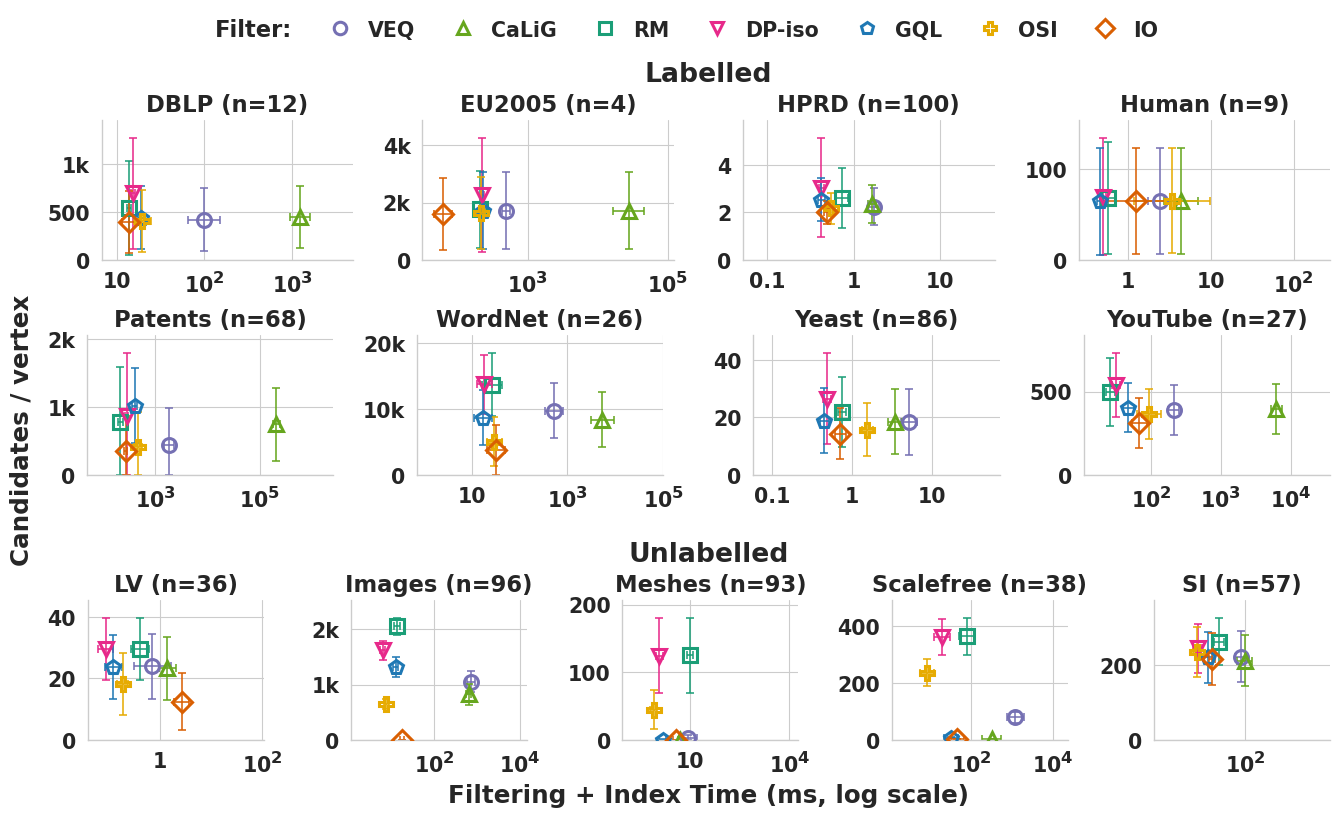

In [16]:
def fig_sota_filter():
    import math
    setup(13.5, TEXT_IN)
    CI_ALPHA, CI_WIDTH, CI_CAP = 0.8, 1.4, 3
    # hollow markers need the darker palette: the cactus plots' colours
    COLOR = CACTUS_COLOR
    EDGE = 2.2
    Z = 1.96
    ORDER = plot_tool_order()
    gqf = {b: graphql_filter(b) for b in ("imsm", "mccreesh")}
    if any(g is not None for g in gqf.values()):
        ORDER = ORDER[:-2] + [GRAPHQL] + ORDER[-2:]

    def graphql(bench):
        g = gqf[bench]
        if g is None:
            return pd.DataFrame()
        g = g[g.status == "COMPLETED"]
        return pd.DataFrame({"dataset": g.dataset, "pattern_name": g.pattern_name, "method": GRAPHQL,
                             "cost_ms": g.cost_ms, "cand": g.cand})

    def orbitsi(bench):
        o = orbitsi_filter(bench)
        f = csv("labelled_filter_singlepass.csv" if bench == "imsm" else "unlabelled_filter_singlepass.csv")
        f = f[(f.graphlet_size == 4) & (f.use_full_graph == 0)]
        cand = f.avg_cand_after_orbit.where(f.outcome != "refuted", 0.0) if "outcome" in f else f.avg_cand_after_orbit
        cand = dict(zip(zip(f.dataset, f.pattern_name), cand))
        return pd.DataFrame({"dataset": o.dataset, "pattern_name": o.pattern_name, "method": "OrbitSI",
                             "cost_ms": o.cost_ms, "cand": [cand.get(k, np.nan) for k in zip(o.dataset, o.pattern_name)]})

    def labelled():
        r = csv("labelled_filter_fixpoint_rounds.csv")
        r = r[(r.graphlet_size == 4) & (r["round"] <= 3)].sort_values("round")
        ox = r.groupby(["dataset", "pattern_name"], as_index=False).last()
        ox = pd.DataFrame({"dataset": ox.dataset, "pattern_name": ox.pattern_name, "method": "IterOrbit",
                           "cost_ms": ox.cumulative_cost_ms, "cand": ox.avg_candidates})
        s = csv("labelled_sota_runs.csv")
        s = s[s.status == "COMPLETED"]
        s = pd.DataFrame({"dataset": s.dataset, "pattern_name": s.pattern_name,
                          "method": s.tool.map({"rapidmatch": "RM", "calig": "CaLiG", "veq": "VEQ", "dpiso": "DP-iso"}),
                          "cost_ms": s.filter_vertices_time_s * 1000.0, "cand": s.num_candidates_avg})
        return pd.concat([ox, orbitsi("imsm"), s, graphql("imsm")], ignore_index=True), PLOT_IMSM

    def unlabelled():
        f = csv("unlabelled_filter_fixpoint.csv")
        f = f[f.graphlet_size == 5]
        ox = pd.DataFrame({"dataset": f.dataset, "pattern_name": f.pattern_name, "method": "IterOrbit",
                           "cost_ms": f.total_filter_ms,
                           "cand": np.where(f.outcome == "refuted", 0.0, f.avg_cand_after_orbit_final)})
        s = csv("unlabelled_sota_filter_candidates.csv")
        s = s[s.status == "COMPLETED"]
        s = pd.DataFrame({"dataset": s.dataset, "pattern_name": s.pattern_name, "method": s.tool,
                          "cost_ms": s.filter_ms, "cand": s.avg_candidates})
        return pd.concat([ox, orbitsi("mccreesh"), s, graphql("mccreesh")], ignore_index=True), MCC

    def restrict(d):
        d = d.dropna(subset=["cost_ms", "cand"])
        o = d[d.method == "OrbitSI"]
        osi_keys = set(zip(o.dataset, o.pattern_name))
        d = d[[k in osi_keys for k in zip(d.dataset, d.pattern_name)]]
        base = d[~d.method.isin(["IterOrbit", "OrbitSI"])]
        nb = base.method.nunique()
        k = base.groupby(["dataset", "pattern_name"]).method.nunique()
        keys = set(k[k == nb].index)
        return d[[x in keys for x in zip(d.dataset, d.pattern_name)]]

    def yfmt(v, _):
        return f"{v / 1000:g}k" if v >= 1000 else f"{v:g}"

    def xfmt(v, _):
        return rf"$\mathbf{{10^{{{int(round(math.log10(v)))}}}}}$" if v >= 100 else f"{v:g}"

    fig, lab, unl = bench_grid((13.5, 9.6), top=0.88, bottom=0.085, left=0.075, right=0.995, hspace=0.72, wspace=0.28, block_gap=0.045)
    for row, (bench, loader, axes) in enumerate((("imsm", labelled, lab), ("mccreesh", unlabelled, unl))):
        d, datasets = loader()
        d = restrict(d[d.dataset.isin(datasets)])
        if INCLUDE_INDEX:
            d = with_index(d.assign(tool=d.method), bench).drop(columns="tool")
            d["cost_ms"] = d.cost_ms + d["index"]
            print(f"\n{bench}: mean index share of the plotted time: " + "  ".join(
                f"{t} {100 * (g['index'] / g.cost_ms).mean():.0f}%" for t, g in d.groupby("method")))
        pooled = d.groupby("method").agg(n=("cand", "size"), cost=("cost_ms", lambda c: gmean(c, 1e-3)),
                                         cand=("cand", "mean")).reindex(ORDER).dropna()
        print(f"\n{['Labelled', 'Unlabelled'][row]}: pooled (n, geo ms, mean cand/vertex)\n{pooled.round(2).to_string()}")
        for ax, ds in zip(axes, datasets):
            x = d[d.dataset == ds]
            m = x.groupby("method").agg(
                cost=("cost_ms", lambda c: gmean(c, 1e-3)), cand=("cand", "mean"),
                lse=("cost_ms", lambda c: Z * np.log(np.maximum(c, 1e-3)).std(ddof=1) / np.sqrt(len(c)) if len(c) > 1 else 0.0),
                kse=("cand", lambda c: Z * c.std(ddof=1) / np.sqrt(len(c)) if len(c) > 1 else 0.0),
                refuted=("cand", lambda c: int((c == 0).sum()))).reindex(ORDER).dropna(subset=["cost"])
            m["c1"], m["c3"] = m.cost / np.exp(m.lse), m.cost * np.exp(m.lse)
            m["k1"], m["k3"] = (m.cand - m.kse).clip(lower=0), m.cand + m.kse
            n = x[x.method == "RM"].pattern_name.nunique()
            print(f"  {ds:14s} n={n:3d}  " + "  ".join(f"{t} {m.loc[t, 'cost']:.3g}ms/{m.loc[t, 'cand']:.3g}"
                                                       f"(ref {m.loc[t, 'refuted']:.0f})" for t in m.index))
            ax.set_xscale("log")
            ax.xaxis.set_major_formatter(mticker.FuncFormatter(xfmt))
            xmin, xmax = max(x.cost_ms.min(), 0.05), x.cost_ms.max()
            x0, x1 = xmin / 1.3, xmax * (xmax / xmin) ** 0.15
            ax.set_xlim(x0, x1)
            top = max(m.cand.max(), m.k3.max())
            y1 = top * 1.15 if top > 0 else 1
            ax.set_ylim(0, y1)
            ax.yaxis.set_major_formatter(mticker.FuncFormatter(yfmt))
            for t, r in m.iterrows():
                col = COLOR[t]
                ax.errorbar(r.cost, r.cand, xerr=[[r.cost - r.c1], [r.c3 - r.cost]], yerr=[[r.cand - r.k1], [r.k3 - r.cand]],
                            fmt="none", ecolor=col, elinewidth=CI_WIDTH, capsize=CI_CAP, capthick=CI_WIDTH, alpha=CI_ALPHA, zorder=2)
                ax.plot(r.cost, r.cand, marker=TOOL_MARKER[t], markersize=10, markerfacecolor="none",
                        markeredgecolor=col, markeredgewidth=EDGE, linestyle="none", zorder=4 if t == "IterOrbit" else 3)
            style_axis(ax, f"{LABEL[ds]} (n={n})")

    for row in (lab[:4], lab[4:], unl):
        equal_gaps(fig, row, left=0.045, right=0.995, gap=0.022)
    # Rows stacked in inches (2026-10-27, user's request: a shorter figure): 1.4 in panels, rows only as far
    # apart as their titles and tick labels need, with room for the block headings, the legend above and the
    # shared x label below.
    height = stack_rows(fig, [lab[:4], lab[4:], unl], panel_in=1.4, gap_in=0.12, heading_in=[0.42, 0.0, 0.5],
                        top_in=0.42, bottom_in=0.48)
    block_heading(fig, lab, "Labelled")
    block_heading(fig, unl, "Unlabelled")
    shared_ylabel(fig, lab + unl, "Candidates / vertex")
    shared_xlabel(fig, lab + unl, "Filtering + Index Time (ms, log scale)" if INCLUDE_INDEX else "Filtering Time (ms, log scale)")
    handles = [plt.Line2D([0], [0], marker=TOOL_MARKER[t], linestyle="none", markersize=9, markerfacecolor="none",
                          markeredgecolor=COLOR[t], markeredgewidth=EDGE, label=SHORT.get(t, t)) for t in ORDER]
    legend_row(fig, "Filter:", handles, 1 - 0.2 / height, columnspacing=1.2, handletextpad=0.3)
    save(fig, "sota_filter")


fig_sota_filter()

## Enumeration (first $10^5$ embeddings, one at a time; Table `tab:enum`)
Every system visits the embeddings one at a time up to $10^5$ (Sun and Luo's protocol), without symmetry
breaking or last-level counting; GuP joins as a seventh system (unlabelled patterns of at most 256 vertices).

In [17]:
SEVEN = SIX + ["GuP"]
ENUM_LIMIT = 100000


def enum_section():
    """Count checks against the counting runs; per benchmark, completed, fastest and IterOrbit's speed-up over
    each system, next to the same numbers when counting; per dataset, the speed-ups."""
    e = csv("enum_e2e.csv")
    ref_l = csv("labelled_e2e_per_pattern.csv")[["dataset", "pattern_name", "ox_emb"]]
    ref_m = csv("unlabelled_e2e_results.csv")
    ref_m = ref_m[ref_m.tool == "OrbitEX"][["dataset", "pattern_name", "count"]].rename(columns={"count": "ox_emb"})
    ref = pd.concat([ref_l, ref_m]).dropna()
    c = e[e.status == "COMPLETED"].merge(ref, on=["dataset", "pattern_name"], how="left")
    c["expect"] = np.minimum(c.ox_emb, ENUM_LIMIT)
    ok = np.where(c.ox_emb >= ENUM_LIMIT, c["count"] >= ENUM_LIMIT, c["count"] == c.ox_emb)
    bad = c[c.ox_emb.notna() & ~ok]
    over = c[c["count"] > ENUM_LIMIT]
    print(f"count checks: {int(c.ox_emb.notna().sum())} completed runs with a reference, {len(bad)} wrong; "
          f"over the limit: {over.groupby(['bench', 'tool']).size().to_dict()} (max {int(over['count'].max()) if len(over) else 0})")
    if len(bad):
        print(bad.groupby(["bench", "tool"]).size().to_string())
        print(bad[["bench", "tool", "dataset", "pattern_name", "count", "expect"]].head(20).to_string(index=False))
    nr = c[c.ox_emb.isna()].assign(capped=lambda f: np.minimum(f["count"], ENUM_LIMIT))
    spread = nr.groupby(["bench", "dataset", "pattern_name"]).capped.agg(["min", "max", "size"])
    dis = spread[spread["min"] != spread["max"]]
    print(f"without a reference: {len(nr)} completed runs on {len(spread)} instances "
          f"({int((spread['size'] > 1).sum())} completed by two or more systems), {len(dis)} with disagreeing capped counts")
    if len(dis):
        print(dis.head(20).to_string())
    print(f"runs reaching the limit: " + e[e.status == "COMPLETED"].assign(r=lambda f: f.limit_reached.astype(float)).groupby(["bench", "tool"]).r.mean().round(2).to_dict().__repr__())

    def speedup(t, a, ref="IterOrbit"):
        k = t[a].notna() & t[ref].notna()
        r = t[a][k] / t[ref][k]
        return (gmean(r) if k.any() else np.nan), int(k.sum())

    for bench, datasets in (("imsm", IMSM_ALL), ("mccreesh", MCC)):
        x = e[(e.bench == bench) & (e.status == "COMPLETED") & e.dataset.isin(datasets)].copy()
        x = with_index(x, bench)
        x["t"] = phase_time(x)
        t = x.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first").reindex(columns=SEVEN)
        _, tc = e2e_times(bench, datasets)
        tc = tc.reindex(columns=SEVEN)
        print(f"\n==== {BENCH[bench]}: enumeration (10^5, tab:enum) vs counting (tab:count)")
        keys = t.index.union(tc.index)
        t, tc = t.reindex(keys), tc.reindex(keys)
        fe = t.eq(t.min(axis=1), axis=0).sum()
        fe6 = t[SIX].eq(t[SIX].min(axis=1), axis=0).sum()
        fc = tc.eq(tc.min(axis=1), axis=0).sum()
        print(f"  fastest of the six without GuP: " + ", ".join(f"{q} {int(fe6[q])}" for q in SIX))
        for s in SEVEN:
            line = f"  {s:10s} done {int(t[s].notna().sum()):3d} (count {int(tc[s].notna().sum()):3d})  fastest {int(fe[s]):3d} (count {int(fc[s]):3d})"
            if s != "IterOrbit":
                ge, ne = speedup(t, s)
                gc, nc = speedup(tc, s)
                line += f"  IO speed-up {ge:.2f}x on {ne} (count {gc:.2f}x on {nc})"
            print(line)
        g = x[x.tool == "GuP"]
        if len(g):
            gi = x[x.tool.isin(["GuP", "IterOrbit"])].assign(t=lambda f: np.where(f.tool == "GuP", (f.t - f["index"]).clip(lower=TIME_FLOOR_MS), f.t))
            ts = gi.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")
            gs, ns = speedup(ts, "GuP")
            print(f"  GuP: index build median {g['index'].median():.1f} ms, {100 * (g['index'] / g.t).median():.0f}% of its time; "
                  f"IO speed-up over GuP without its index {gs:.2f}x on {ns}")
        io = x[x.tool == "IterOrbit"]
        print(f"  IterOrbit filter share of its time: median {100 * (io['filter'] / io.t).median():.0f}%")
        print("  per dataset, IO speed-up over each (enumeration | counting):")
        for ds in datasets:
            te, tcc = t.loc[ds], tc.loc[ds]
            print(f"    {LABEL[ds]:10s} " + "  ".join(f"{SHORT.get(s, s)} {speedup(te, s)[0]:.2f}|{speedup(tcc, s)[0]:.2f}" for s in SEVEN[1:])
                  + f"  | fastest IO {int(te.eq(te.min(axis=1), axis=0).sum()['IterOrbit'])}/{int(tcc.eq(tcc.min(axis=1), axis=0).sum()['IterOrbit'])}")


enum_section()

count checks: 6059 completed runs with a reference, 0 wrong; over the limit: {('imsm', 'RM'): 399, ('imsm', 'VEQ'): 317, ('mccreesh', 'RM'): 29, ('mccreesh', 'VEQ'): 11} (max 3867289617)
without a reference: 2354 completed runs on 358 instances (357 completed by two or more systems), 0 with disagreeing capped counts
runs reaching the limit: {('imsm', 'CaLiG'): 0.69, ('imsm', 'DP-iso'): 0.68, ('imsm', 'GuP'): 0.69, ('imsm', 'IterOrbit'): 0.69, ('imsm', 'OrbitSI'): 0.68, ('imsm', 'RM'): 0.69, ('imsm', 'VEQ'): 0.63, ('mccreesh', 'CaLiG'): 0.12, ('mccreesh', 'DP-iso'): 0.12, ('mccreesh', 'GuP'): 0.13, ('mccreesh', 'IterOrbit'): 0.26, ('mccreesh', 'OrbitSI'): 0.11, ('mccreesh', 'RM'): 0.12, ('mccreesh', 'VEQ'): 0.11}

==== Labelled: enumeration (10^5, tab:enum) vs counting (tab:count)
  fastest of the six without GuP: IterOrbit 200, OrbitSI 116, RM 192, DP-iso 277, VEQ 13, CaLiG 2
  IterOrbit  done 796 (count 472)  fastest 158 (count 165)
  OrbitSI    done 776 (count 458)  fastest 115 (coun

    YouTube    OSI 3.41|1.57  RM 0.94|0.80  DP-iso 1.04|3.92  VEQ 80.07|33.44  CaLiG 130.65|43.97  GuP 0.82|nan  | fastest IO 5/5

==== Unlabelled: enumeration (10^5, tab:enum) vs counting (tab:count)
  fastest of the six without GuP: IterOrbit 81, OrbitSI 340, RM 24, DP-iso 44, VEQ 8, CaLiG 13
  IterOrbit  done 470 (count 444)  fastest  81 (count 103)
  OrbitSI    done 465 (count 435)  fastest 330 (count 312)  IO speed-up 0.55x on 463 (count 0.63x on 434)
  RM         done 467 (count 431)  fastest  22 (count   5)  IO speed-up 3.43x on 464 (count 3.97x on 430)
  DP-iso     done 425 (count 391)  fastest  44 (count  40)  IO speed-up 2.26x on 425 (count 2.41x on 391)
  VEQ        done 378 (count 351)  fastest   8 (count   9)  IO speed-up 32.59x on 378 (count 37.09x on 351)
  CaLiG      done 452 (count 417)  fastest  13 (count  12)  IO speed-up 7.66x on 451 (count 8.63x on 417)
  GuP        done 374 (count   0)  fastest  22 (count   0)  IO speed-up 5.14x on 372 (count nanx on 0)
  GuP: ind

### By pattern size and density (Table `tab:size-density`, from the enumeration runs)
Per bin: instances any system completed, how many each system completed and won, and IterOrbit's speed-up
over each system. Enumeration compares eight systems (the six, GuP and GraphQL; indexes charged per query, as in
the table); counting, printed first, the six. Dense = average degree >= 3 (Sun and Luo's split; the labelled corpus's
own names are kept, which call every 4-vertex pattern dense).

In [18]:
def size_density(mode="count"):
    assert mode in ("enum", "count")
    SIZE_BINS = {"imsm": [0, 8, 16, 24, 32], "mccreesh": [0, 16, 32, 128, 10 ** 6]}
    e = csv("enum_e2e.csv")
    lab = csv("labelled_patterns.csv").assign(bench="imsm", nv=lambda d: d.vertex_count, nE=lambda d: d.edge_count)
    unl = csv("unlabelled_pairs.csv")
    unl = unl.assign(bench="mccreesh", pattern_name=unl.instance, nv=unl.pattern_n, nE=unl.pattern_m)
    cols = ["bench", "dataset", "pattern_name", "nv", "nE"]
    inst = pd.concat([lab[cols], unl[cols]], ignore_index=True)
    inst["dense"] = 2 * inst.nE / inst.nv >= 3
    ok = inst.bench == "imsm"
    inst.loc[ok, "dense"] = inst[ok].pattern_name.str.contains("dense")

    def speedup(t, a):
        k = t[a].notna() & t["IterOrbit"].notna()
        return (gmean(t[a][k] / t["IterOrbit"][k]) if k.any() else np.nan), int(k.sum())

    def table(t, groups):
        fast = t.eq(t.min(axis=1), axis=0)
        for name, keys in groups:
            tt, ff = t.loc[keys], fast.loc[keys]
            line = f"  {name:12s} n={len(tt):3d}  "
            line += "  ".join(f"{SHORT.get(s, s)} {int(tt[s].notna().sum()):3d}/{int(ff[s].sum()):3d}" for s in systems)
            line += "  | IO speed-up " + "  ".join(
                f"{SHORT.get(s, s)} {g:5.2f}x({n})" for s in systems[1:] for g, n in [speedup(tt, s)])
            print(line)

    systems = SIX if mode == "count" else SEVEN + [GRAPHQL]
    for bench, datasets in (("imsm", IMSM_ALL), ("mccreesh", MCC)):
        if mode == "count":
            _, t = e2e_times(bench, datasets)
            t = t.reindex(columns=systems).dropna(how="all")
        else:
            x = e[(e.bench == bench) & (e.status == "COMPLETED") & e.dataset.isin(datasets)].copy()
            gq = graphql_phases(bench, "enum")
            if gq is not None:
                x = pd.concat([x, gq[gq.dataset.isin(datasets)].assign(bench=bench, status="COMPLETED")], ignore_index=True)
            x = with_index(x, bench, charge=E2E_INDEX_CHARGE)
            x["t"] = phase_time(x)
            t = x.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first").reindex(columns=systems)
        meta = inst[inst.bench == bench].set_index(["dataset", "pattern_name"]).reindex(t.index)
        assert meta.nv.notna().all()
        size = pd.cut(meta.nv, SIZE_BINS[bench])
        print(f"\n==== {BENCH[bench]} ({mode}): completed/fastest per system, IterOrbit's speed-up (instances both completed)")
        print(" by |V(q)|:")
        table(t, [(f"{iv.left + 1}-{iv.right}" if iv.right < 10 ** 6 else f">{iv.left}", t.index[size == iv])
                  for iv in size.cat.categories])
        print(" by density:")
        table(t, [(n, t.index[meta.dense == v]) for n, v in (("sparse", False), ("dense", True))])
        print(" by |V(q)| x density:")
        table(t, [(f"{'D' if v else 'S'} {iv.left + 1}-{iv.right}" if iv.right < 10 ** 6 else f"{'D' if v else 'S'} >{iv.left}",
                   t.index[(size == iv) & (meta.dense == v)]) for iv in size.cat.categories for v in (False, True)])
        if mode == "count":
            continue
        lim = x.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="limit_reached", aggfunc="first")
        r = lim.reindex(t.index)["IterOrbit"].astype(float)
        print(" IterOrbit runs reaching 10^5, by |V(q)|: " + ", ".join(
            f"{iv}: {r[size == iv].mean():.2f}" for iv in size.cat.categories))


size_density("count")
size_density("enum")


==== Labelled (count): completed/fastest per system, IterOrbit's speed-up (instances both completed)
 by |V(q)|:
  1-8          n= 86  IO  86/ 23  OSI  83/ 15  RM  84/ 32  DP-iso  83/ 14  VEQ  81/  3  CaLiG  83/  0  | IO speed-up OSI  1.21x(83)  RM  1.14x(84)  DP-iso  2.22x(83)  VEQ 13.05x(81)  CaLiG 36.44x(83)
  9-16         n=165  IO 156/ 74  OSI 150/ 31  RM 151/ 31  DP-iso 135/ 16  VEQ  92/ 13  CaLiG 143/  0  | IO speed-up OSI  1.74x(150)  RM  1.65x(151)  DP-iso  8.94x(135)  VEQ 11.90x(83)  CaLiG 42.94x(143)
  17-24        n=118  IO 114/ 36  OSI 114/ 21  RM 114/ 29  DP-iso  99/ 22  VEQ  82/  8  CaLiG 104/  2  | IO speed-up OSI  1.74x(113)  RM  1.53x(113)  DP-iso  2.74x(99)  VEQ  5.78x(80)  CaLiG 15.93x(103)
  25-32        n=118  IO 116/ 32  OSI 111/ 27  RM 118/ 27  DP-iso 105/ 29  VEQ  92/  3  CaLiG 106/  0  | IO speed-up OSI  2.01x(110)  RM  1.59x(116)  DP-iso  2.04x(105)  VEQ  5.78x(92)  CaLiG 12.93x(106)
 by density:
  sparse       n= 71  IO  66/ 11  OSI  67/ 12  RM  68/ 30  DP-


==== Labelled (enum): completed/fastest per system, IterOrbit's speed-up (instances both completed)
 by |V(q)|:
  1-8          n= 89  IO  89/ 76  OSI  89/  6  RM  89/  6  DP-iso  89/  1  VEQ  89/  0  CaLiG  89/  0  GuP  89/  0  GQL  89/  0  | IO speed-up OSI  3.37x(89)  RM  4.14x(89)  DP-iso  5.24x(89)  VEQ 16.97x(89)  CaLiG 52.19x(89)  GuP 10.86x(89)  GQL 12.16x(89)
  9-16         n=236  IO 236/152  OSI 232/ 44  RM 236/ 29  DP-iso 231/  5  VEQ 184/  1  CaLiG 236/  0  GuP 236/  0  GQL 232/  5  | IO speed-up OSI  2.51x(232)  RM  2.45x(236)  DP-iso  5.73x(231)  VEQ 13.95x(184)  CaLiG 47.78x(236)  GuP  6.22x(236)  GQL 13.75x(232)
  17-24        n=236  IO 236/194  OSI 230/ 10  RM 234/ 13  DP-iso 227/  5  VEQ 188/  1  CaLiG 236/  0  GuP 236/  4  GQL 229/ 10  | IO speed-up OSI  4.13x(230)  RM  3.28x(234)  DP-iso  4.72x(227)  VEQ 10.95x(188)  CaLiG 45.75x(236)  GuP  7.47x(236)  GQL  7.19x(229)
  25-32        n=239  IO 235/217  OSI 225/  0  RM 227/  6  DP-iso 232/  8  VEQ 185/  2  CaLiG 238/ 

 IterOrbit runs reaching 10^5, by |V(q)|: (0, 16]: 0.77, (16, 32]: 0.92, (32, 128]: 0.34, (128, 1000000]: 0.10


### Figure `enum_cactus.pdf`
The cactus plot of the enumeration sweep (both panels to the full 800 / 480 instances; GuP placed in the
legend by its geometric mean over the instances all seven completed).

legend: GuP placed by 956 instances all seven completed: VEQ 178, CaLiG 228, RM 37.1, DP-iso 30.7, OrbitSI 21.9, IterOrbit 10.6, GuP 71.9
legend: GraphQL placed by 950 instances all completed: VEQ 173, CaLiG 219, GuP 70.3, RM 36.2, DP-iso 30.1, OrbitSI 21.2, IterOrbit 10.4, GraphQL 45.1


Labelled: instances completed  VEQ 646  CaLiG 799  GuP 800  GraphQL 770  RM 786  DP-iso 779  OrbitSI 776  IterOrbit 796
Unlabelled: instances completed  VEQ 378  CaLiG 452  GuP 374  GraphQL 439  RM 467  DP-iso 425  OrbitSI 465  IterOrbit 470


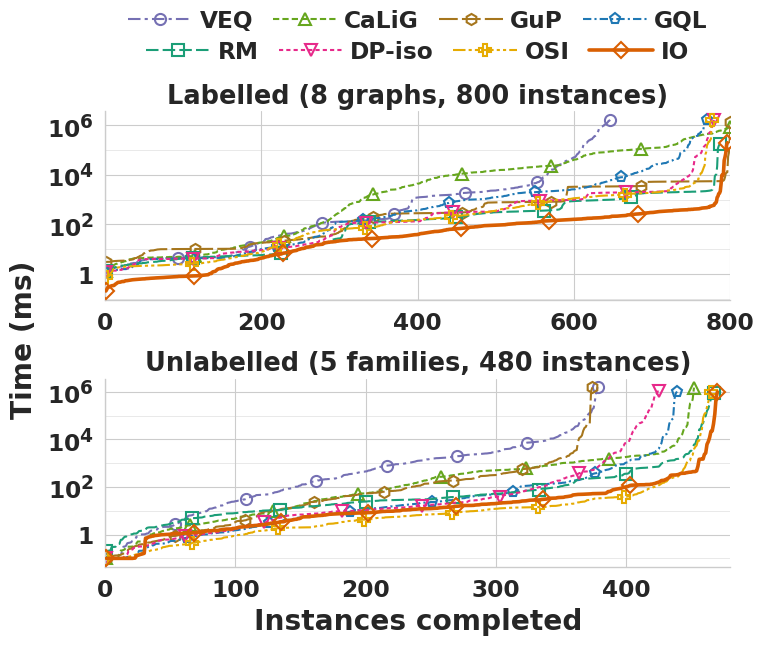

In [19]:
def fig_enum_cactus():
    setup(7.4)
    GUP = "GuP"
    X = {"imsm": (800, 200), "mccreesh": (480, 100)}
    e = csv("enum_e2e.csv")
    gq = [graphql_phases(b, "enum") for b in ("imsm", "mccreesh")]
    if all(g is not None for g in gq):
        e = pd.concat([e] + [g.assign(bench=b, status="COMPLETED") for g, b in zip(gq, ("imsm", "mccreesh"))],
                      ignore_index=True)

    def legend_order():
        order = plot_tool_order()
        x = e[(e.status == "COMPLETED")].copy()
        x = pd.concat([with_index(x[x.bench == b], b, charge=E2E_INDEX_CHARGE) for b in ("imsm", "mccreesh")])
        x["t"] = phase_time(x)
        t = x.pivot_table(index=["bench", "dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")[order + [GUP]].dropna()
        g = {c: gmean(t[c]) for c in t.columns}
        i = min(next((k for k, c in enumerate(order) if g[c] < g[GUP]), len(order)), len(order) - 2)
        print(f"legend: GuP placed by {len(t)} instances all seven completed: " + ", ".join(f"{c} {g[c]:.3g}" for c in t.columns))
        order = order[:i] + [GUP] + order[i:]
        if GRAPHQL in set(x.tool):
            order = place_by_gmean(order, GRAPHQL, x.pivot_table(index=["bench", "dataset", "pattern_name"], columns="tool",
                                                                  values="t", aggfunc="first"))
        return order

    order = legend_order()
    fig, axes = plt.subplots(2, 1, figsize=(7.4, 6.2))
    for ax, (bench, datasets) in zip(axes, [("imsm", PLOT_IMSM), ("mccreesh", MCC)]):
        d = e[(e.bench == bench) & (e.status == "COMPLETED") & e.dataset.isin(datasets)].copy()
        d = with_index(d, bench, charge=E2E_INDEX_CHARGE)
        done = {}
        for t in order:
            y = np.sort(phase_time(d[d.tool == t]).to_numpy())
            done[t] = len(y)
            if len(y):
                _cactus_line(ax, t, y)
        print(f"{BENCH[bench]}: instances completed  " + "  ".join(f"{t} {n}" for t, n in done.items()))
        _cactus_axis(ax)
        ax.set_xlim(0, X[bench][0])
        ax.xaxis.set_major_locator(mticker.MultipleLocator(X[bench][1]))
        style_axis(ax, CACTUS_TITLE[bench])
    _cactus_finish(fig, axes, order, "enum_cactus")


fig_enum_cactus()

### Figure `e2e_phases_enum.pdf` (not in the paper)
`e2e_phases.pdf` for the enumeration sweep, with GuP as a seventh bar (its single timer counts as enumeration,
plus its index build); the unlabelled bars cover only the pairs GuP accepts.


Labelled: shifted geometric-mean time (ms, shift 10 s, unsolved at 1800 s) and shares (index/filter/order/enumerate/unsolved) over instances some system solved
  dblp           n=100  VEQ 1159 [9/4/0/88/0]  CaLiG 2516 [4/88/0/8/0]  GuP 285.2 [90/0/0/10/0]  GraphQL 2576 [4/1/0/27/68]  RM 3203 [3/1/0/3/94]  DP-iso 4439 [2/0/0/26/71]  OrbitSI 3267 [2/3/0/3/92]  IterOrbit 808.3 [0/3/0/30/67]
                 of 100: VEQ done 100 fastest 1  CaLiG done 100 fastest 0  GuP done 100 fastest 2  GQL done 97 fastest 0  RM done 95 fastest 0  DP-iso done 95 fastest 2  OSI done 95 fastest 0  IO done 99 fastest 95
  eu2005         n=100  VEQ 2.831e+04 [4/3/0/23/70]  CaLiG 8.859e+04 [1/99/0/0/0]  GuP 3419 [97/0/0/3/0]  GraphQL 1.398e+04 [7/1/0/32/59]  RM 6925 [13/1/0/17/69]  DP-iso 5072 [17/2/0/30/51]  OrbitSI 1.097e+04 [7/14/0/29/49]  IterOrbit 1163 [0/18/0/35/47]
                 of 100: VEQ done 82 fastest 0  CaLiG done 100 fastest 0  GuP done 100 fastest 2  GQL done 90 fastest 0  RM done 93 fastes

  hprd           n=100  VEQ 4.527 [80/13/1/6/0]  CaLiG 5.253 [69/25/0/6/0]  GuP 10.25 [93/0/0/7/0]  GraphQL 4.496 [80/10/0/10/0]  RM 5.201 [69/8/4/18/0]  DP-iso 4.184 [86/5/0/9/0]  OrbitSI 2.327 [72/23/0/5/0]  IterOrbit 0.7153 [0/82/2/16/0]
                 of 100: VEQ done 100 fastest 0  CaLiG done 100 fastest 0  GuP done 100 fastest 0  GQL done 100 fastest 0  RM done 100 fastest 0  DP-iso done 100 fastest 0  OSI done 100 fastest 0  IO done 100 fastest 100
  human          n=100  VEQ 3730 [0/0/0/18/82]  CaLiG 100 [2/68/0/30/0]  GuP 541.8 [2/0/0/98/0]  GraphQL 550.9 [0/0/0/2/97]  RM 553.6 [0/1/0/3/96]  DP-iso 1709 [0/0/0/34/66]  OrbitSI 6179 [0/1/0/2/97]  IterOrbit 400.9 [0/3/0/97/0]
                 of 100: VEQ done 95 fastest 1  CaLiG done 100 fastest 0  GuP done 100 fastest 0  GQL done 99 fastest 15  RM done 99 fastest 33  DP-iso done 98 fastest 8  OSI done 91 fastest 8  IO done 100 fastest 36


  patents        n=100  VEQ 2.384e+04 [9/5/0/31/55]  CaLiG 2.844e+05 [1/98/0/0/2]  GuP 5435 [94/0/0/6/0]  GraphQL 1.187e+04 [16/4/0/47/33]  RM 3031 [56/7/0/17/20]  DP-iso 3567 [48/9/0/26/17]  OrbitSI 2639 [34/28/0/16/22]  IterOrbit 1372 [0/24/0/36/40]
                 of 100: VEQ done 87 fastest 0  CaLiG done 99 fastest 0  GuP done 100 fastest 2  GQL done 95 fastest 0  RM done 99 fastest 0  DP-iso done 99 fastest 1  OSI done 99 fastest 0  IO done 99 fastest 97
  wordnet        n=100  VEQ 4.77e+05 [0/0/0/18/82]  CaLiG 1.945e+04 [0/94/0/6/0]  GuP 1432 [2/0/0/98/0]  GraphQL 5.288e+04 [0/0/0/74/25]  RM 192 [5/36/0/60/0]  DP-iso 1.842e+04 [0/0/0/55/45]  OrbitSI 251.1 [2/20/0/78/0]  IterOrbit 122.6 [0/63/0/37/0]
                 of 100: VEQ done 39 fastest 0  CaLiG done 100 fastest 0  GuP done 100 fastest 2  GQL done 91 fastest 0  RM done 100 fastest 2  DP-iso done 91 fastest 3  OSI done 100 fastest 47  IO done 100 fastest 46


  yeast          n=100  VEQ 2520 [0/0/0/77/23]  CaLiG 15.17 [6/46/0/48/0]  GuP 9.265 [30/0/0/70/0]  GraphQL 112.5 [1/1/0/99/0]  RM 4.715 [20/15/4/61/0]  DP-iso 45.69 [2/1/0/97/0]  OrbitSI 487.2 [0/0/0/99/0]  IterOrbit 4.238 [0/25/0/74/0]
                 of 100: VEQ done 99 fastest 2  CaLiG done 100 fastest 0  GuP done 100 fastest 1  GQL done 100 fastest 0  RM done 100 fastest 19  DP-iso done 100 fastest 0  OSI done 100 fastest 5  IO done 100 fastest 73
  youtube        n=100  VEQ 2.886e+05 [0/0/0/14/86]  CaLiG 1.165e+04 [2/98/0/0/0]  GuP 803.7 [93/0/0/7/0]  GraphQL 3734 [7/2/0/58/33]  RM 404.4 [65/6/0/29/0]  DP-iso 715.6 [37/5/0/58/0]  OrbitSI 2072 [8/16/0/21/55]  IterOrbit 660.9 [0/12/0/6/81]
                 of 100: VEQ done 44 fastest 0  CaLiG done 100 fastest 0  GuP done 100 fastest 1  GQL done 98 fastest 0  RM done 100 fastest 0  DP-iso done 100 fastest 1  OSI done 98 fastest 0  IO done 99 fastest 98



Unlabelled: shifted geometric-mean time (ms, shift 10 s, unsolved at 1800 s) and shares (index/filter/order/enumerate/unsolved) over instances some system solved
  LV             n= 93  VEQ 1.01e+04 [0/0/0/20/80]  CaLiG 2900 [0/1/0/55/44]  GuP 5674 [0/0/0/25/75]  RM 3399 [0/0/3/77/19]  GraphQL 4632 [0/0/0/41/59]  DP-iso 7542 [0/0/0/50/50]  OrbitSI 2770 [0/0/0/54/46]  IterOrbit 2649 [0/0/0/52/48]
                 of 100: VEQ done 83 fastest 8  CaLiG done 91 fastest 9  GuP done 87 fastest 5  RM done 92 fastest 13  GQL done 89 fastest 24  DP-iso done 88 fastest 18  OSI done 91 fastest 37  IO done 91 fastest 29
  images-CVIU11  n=100  VEQ 8266 [0/15/0/50/35]  CaLiG 872 [0/100/0/0/0]  GuP 359 [0/0/0/100/0]  RM 38.32 [1/46/2/51/0]  GraphQL 256.7 [0/6/0/94/0]  DP-iso 21.51 [1/37/2/60/0]  OrbitSI 9.216 [1/97/0/2/0]  IterOrbit 15.99 [0/100/0/0/0]
                 of 100: VEQ done 96 fastest 0  CaLiG done 100 fastest 0  GuP done 100 fastest 0  RM done 100 fastest 0  GQL done 100 fastest 0  DP-i

  meshes-CVIU11  n=100  VEQ 482.4 [0/30/0/70/0]  CaLiG 9.268 [2/95/0/2/0]  GuP 19.69 [2/0/0/98/0]  RM 20.66 [1/77/2/20/0]  GraphQL 2.841 [7/88/1/4/0]  DP-iso 4.743 [4/43/1/52/0]  OrbitSI 1.665 [4/92/1/3/0]  IterOrbit 5.445 [0/100/0/0/0]
                 of 100: VEQ done 100 fastest 0  CaLiG done 100 fastest 1  GuP done 100 fastest 7  RM done 100 fastest 0  GQL done 100 fastest 2  DP-iso done 100 fastest 13  OSI done 100 fastest 71  IO done 100 fastest 9
  scalefree      n= 80  VEQ 2.029e+05 [0/3/1/7/89]  CaLiG 1226 [0/92/0/8/0]  GuP 4.856e+05 [0/0/0/0/100]  RM 2652 [0/10/3/33/55]  GraphQL 274.9 [0/30/0/69/0]  DP-iso 3.923e+04 [0/0/0/18/82]  OrbitSI 2203 [0/1/0/34/65]  IterOrbit 598 [0/17/0/83/0]


                 of 80: VEQ done 38 fastest 0  CaLiG done 80 fastest 1  GuP done 20 fastest 0  RM done 78 fastest 0  GQL done 80 fastest 6  DP-iso done 60 fastest 0  OSI done 78 fastest 73  IO done 80 fastest 0
  si             n=100  VEQ 8.048e+04 [0/1/0/7/92]  CaLiG 2.257e+04 [0/3/0/13/84]  GuP 5.475e+04 [0/0/0/8/92]  RM 3116 [0/5/0/37/57]  GraphQL 4.53e+04 [0/0/0/9/91]  DP-iso 2.825e+04 [0/0/0/11/89]  OrbitSI 3830 [0/0/0/36/64]  IterOrbit 942.7 [0/4/0/38/58]
                 of 100: VEQ done 61 fastest 0  CaLiG done 81 fastest 0  GuP done 67 fastest 0  RM done 97 fastest 5  GQL done 70 fastest 2  DP-iso done 77 fastest 3  OSI done 96 fastest 50  IO done 99 fastest 40


figure 13.5 x 8.7 in drawn; at \textwidth 6.85 x 4.39 in


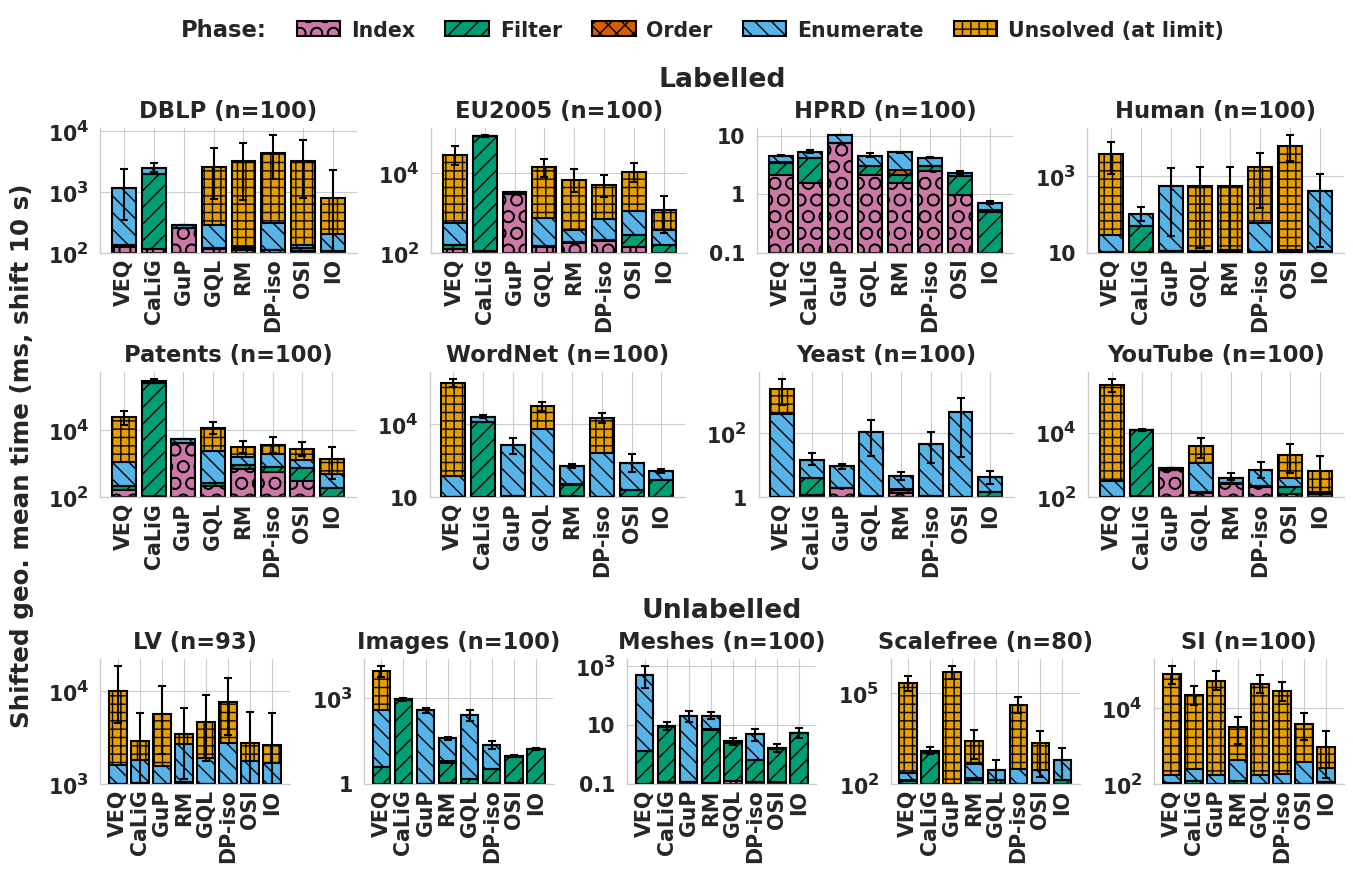

In [20]:
fig_e2e_phases(enum=True)

# Exploratory analyses
Analyses behind decisions and checks that are not, or no longer, in the paper.

## IterOrbit without its search accelerations, and the one-at-a-time ablation
The no-acceleration rerun (`--no-symmetry --no-edge-orbit-filter`, same frozen binary) against the default run
and the four baselines; then, on 70 instances, each acceleration alone (a timeout counts as 1800 s).

In [21]:
def no_accel(all_imsm=False):
    BASE = ["RM", "DP-iso", "VEQ", "CaLiG"]
    NO, ON = "No accel.", "IterOrbit"
    T_MS = 1800000.0

    def load(bench):
        d = iterorbit_sweep("no_accel", bench)[["dataset", "pattern_name", "status", "filter", "order", "enumerate", "count"]]
        print(f"no_accel ({bench}): {len(d)} logs, {d.status.value_counts().to_dict()}")
        return d

    def report(bench, loader, datasets):
        raw = load(bench)
        raw = raw[raw.dataset.isin(datasets)]
        old = raw[raw.status == "COMPLETED"].assign(tool=NO, read=0.0)
        old[["order", "enumerate"]] = old[["order", "enumerate"]].fillna(0)
        d = pd.concat([loader(), old], ignore_index=True)
        d = d[d.dataset.isin(datasets)]
        d["t"] = phase_time(d)
        t = d.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")
        print(f"\n================ {BENCH[bench]}: {len(raw)} instances run ================")
        print("completed: " + ", ".join(f"{k} {int(t[k].notna().sum())}" for k in [NO, ON] + BASE))
        best = t[BASE].min(axis=1)
        out = []
        for me in (NO, ON):
            for o in BASE + ["fastest of four"]:
                other = best if o == "fastest of four" else t[o]
                both = t[me].notna() & other.notna()
                r = other[both] / t[me][both]
                out.append({"config": me, "vs": o, "both": int(both.sum()), "speedup": round(gmean(r), 2),
                            "wins": int((r > 1).sum()), "losses": int((r < 1).sum())})
        print(pd.DataFrame(out).to_string(index=False))
        both = t[NO].notna() & t[ON].notna()
        r = t[NO][both] / t[ON][both]
        print(f"accelerations' speed-up (no accel. / default), {int(both.sum())} both completed: {gmean(r):.2f}x")
        per = []
        for ds in datasets:
            s, b = t.loc[ds], best.loc[ds]
            row = {"dataset": ds, "done_no": int(s[NO].notna().sum()), "done_on": int(s[ON].notna().sum()),
                   "done_RM": int(s.RM.notna().sum()), "done_best": int(s[BASE].notna().sum().max())}
            for me, tag in ((NO, "no"), (ON, "on")):
                k = s[me].notna() & b.notna()
                row[f"{tag}_vs_fastest"] = round(gmean(b[k] / s[me][k]), 2)
                k = s[me].notna() & s.RM.notna()
                row[f"{tag}_vs_RM"] = round(gmean(s.RM[k] / s[me][k]), 2)
            k = s[NO].notna() & s[ON].notna()
            row["accel_speedup"] = round(gmean(s[NO][k] / s[ON][k]), 2)
            per.append(row)
        print(pd.DataFrame(per).to_string(index=False))
        anyb = t[BASE].notna().any(axis=1)
        print(f"only no-accel completes: {int((t[NO].notna() & ~anyb).sum())}; "
              f"no-accel times out but a baseline completes: {int((t[NO].isna() & anyb).sum())}")
        return raw

    def counts_check(raw, ref, name):
        j = raw.dropna(subset=["count"]).merge(ref, on=["dataset", "pattern_name"])
        bad = j[j["count"] != j.ref]
        print(f"{name}: counts compared {len(j)}, mismatches {len(bad)}")
        if len(bad):
            print(bad.to_string(index=False))

    imsm = report("imsm", imsm_phases, IMSM + (["dblp", "eu2005", "youtube"] if all_imsm else []))
    mcc = report("mccreesh", mcc_phases, MCC)
    print()
    ox = csv("labelled_iterorbit_e2e.csv")
    emb = next(c for c in ox.columns if "emb" in c.lower() or "match" in c.lower())
    counts_check(imsm, ox[ox.status == "COMPLETED"][["dataset", "pattern_name", emb]].rename(columns={emb: "ref"}), "Labelled")
    e = csv("unlabelled_e2e_results.csv")
    e = e[(e.tool == "OrbitEX") & (e.status == "COMPLETED")]
    counts_check(mcc, e[["dataset", "pattern_name", "count"]].rename(columns={"count": "ref"}), "Unlabelled")

    abl = csv("accel_ablation_instances.csv")
    for r in iterorbit_sweep("accel_ablation").itertuples():
        row, cfg = divmod(int(r.task), 2)
        name = ("edge", "sym")[cfg]
        done = r.status == "COMPLETED"
        ms = sum(np.nan_to_num(v) for v in (r.filter_ms, r.order_us / 1e3, r.search_ms))
        abl.loc[row, name] = max(ms, TIME_FLOOR_MS) if done else T_MS
        if name == "sym" and isinstance(r.symmetry_multiplier, str):
            abl.loc[row, "multiplier"] = int(r.symmetry_multiplier)

    def eff(raw, loader, datasets):
        off = raw.assign(t=np.where(raw.status == "COMPLETED",
                                    phase_time(raw.assign(read=0.0).fillna({"order": 0, "enumerate": 0})), T_MS))
        on = loader()
        on = on[(on.tool == "IterOrbit") & on.dataset.isin(datasets)].assign(t=lambda x: phase_time(x))
        return off.set_index(["dataset", "pattern_name"]).t, on.set_index(["dataset", "pattern_name"]).t

    off_i, on_i = eff(imsm, imsm_phases, IMSM)
    off_m, on_m = eff(mcc, mcc_phases, MCC)
    off_all, on_all = pd.concat([off_i, off_m]), pd.concat([on_i, on_m])
    k = list(zip(abl.dataset, abl.pattern_name))
    abl["off"] = off_all.reindex(k).to_numpy()
    abl["on"] = on_all.reindex(k).fillna(T_MS).to_numpy()
    x = abl[abl.dataset.isin(IMSM + MCC) & abl.off.notna()].copy()
    print(f"\n================ single-feature ablation: {len(x)} instances "
          f"({x.groupby('bench').size().to_dict()}) ================")
    for c in ("off", "edge", "sym", "on"):
        x[f"{c}_done"] = x[c] < T_MS
    print("completed:", {c: int(x[f"{c}_done"].sum()) for c in ("off", "edge", "sym", "on")})
    for name, g in [("all", x)] + list(x.groupby("bench")):
        print(f"{name:9s} speed-up over both off: edge only {gmean(g.off / g.edge):.2f}x, "
              f"symmetry only {gmean(g.off / g.sym):.2f}x, both {gmean(g.off / g.on):.2f}x")
    sf = x.dataset == "scalefree"
    for label, g in (("scalefree", x[sf]), ("not scalefree", x[~sf])):
        print(f"{label} ({len(g)}): edge-only time / both off {gmean(g.edge / g.off):.3f} "
              f"({gmean(g.off / g.edge):.1f}x); symmetry-only / both off {gmean(g.sym / g.off):.3f}")
    print(f"symmetric patterns (multiplier > 1): {int((x.multiplier > 1).sum())} of {len(x)}, "
          f"median multiplier {x[x.multiplier > 1].multiplier.median():.0f}")
    gain = ~x.off_done & x.on_done
    print(f"both off times out, both on completes: {int(gain.sum())}; symmetry only completes "
          f"{int((gain & x.sym_done).sum())}, edge only {int((gain & x.edge_done).sum())}")
    return x


no_accel();

no_accel (imsm): 800 logs, {'COMPLETED': 463, 'TIMEOUT': 337}

================ Labelled: 500 instances run ================
completed: No accel. 380, IterOrbit 387, RM 384, DP-iso 357, VEQ 293, CaLiG 368
   config              vs  both  speedup  wins  losses
No accel.              RM   380     1.42   244     136
No accel.          DP-iso   357     3.09   252     105
No accel.             VEQ   291     7.63   276      15
No accel.           CaLiG   367    19.81   364       3
No accel. fastest of four   380     0.87   156     224
IterOrbit              RM   381     1.65   285      96
IterOrbit          DP-iso   357     3.35   226     131
IterOrbit             VEQ   291     7.81   275      16
IterOrbit           CaLiG   368    22.01   363       5
IterOrbit fastest of four   382     1.01   172     210
accelerations' speed-up (no accel. / default), 380 both completed: 1.15x
dataset  done_no  done_on  done_RM  done_best  no_vs_fastest  no_vs_RM  on_vs_fastest  on_vs_RM  accel_speedup
   hpr

symmetric patterns (multiplier > 1): 56 of 66, median multiplier 20
both off times out, both on completes: 17; symmetry only completes 15, edge only 2


## The original OrbitSI filter with IterOrbit's search
One round of LDF + NLF, the induced candidate subgraph and the orbit filter (`--iterate 1
--disable-semi-join`, g=4, no edge-orbit index filter), with IterOrbit's order, symmetry breaking and search;
all 13 datasets, against IterOrbit and the four baselines.

In [22]:
def orbitsi_filter_e2e():
    ME = "OrbitSI"
    BASE = ["RM", "DP-iso", "VEQ", "CaLiG"]
    key = ["dataset", "pattern_name"]
    r = iterorbit_sweep("orbitsi_filter")
    d = pd.DataFrame({"bench": r.bench, "dataset": r.dataset, "pattern_name": r.pattern_name, "pattern_path": r.pattern_path,
                      "status": r.status, "filter": r["filter"], "order": np.nan_to_num(r["order"]),
                      "enumerate": np.nan_to_num(r["enumerate"]), "count": r["count"],
                      "refuted": (r.status == "COMPLETED") & r.search_ms.isna()})
    print(f"logs {len(d)}, duplicates {int(d.duplicated(key).sum())}")
    print("status:", d.groupby("bench").status.value_counts().unstack(fill_value=0).to_dict("index"))

    ox = d[d.status == "COMPLETED"].assign(tool=ME, read=0.0)
    for bench, loader, datasets in (("imsm", lambda: imsm_phases(IMSM_ALL), IMSM_ALL), ("mccreesh", mcc_phases, MCC)):
        x = pd.concat([loader(), ox[ox.bench == bench]], ignore_index=True)
        x = x[x.dataset.isin(datasets)]
        x["t"] = phase_time(x)
        t = x.pivot_table(index=key, columns="tool", values="t", aggfunc="first")
        tools = [ME, "IterOrbit"] + BASE
        for label, dsets in ([("all 8", IMSM_ALL), ("paper's 5", IMSM)] if bench == "imsm" else [("all 5", MCC)]):
            s = t[t.index.get_level_values(0).isin(dsets)]
            print(f"\n================ {BENCH[bench]}, {label} ({len(s)} instances) ================")
            print("completed: " + ", ".join(f"{k} {int(s[k].notna().sum())}" for k in tools))
            best = s[BASE].min(axis=1)
            out = []
            for o in ["IterOrbit"] + BASE + ["fastest of four"]:
                other = best if o == "fastest of four" else s[o]
                both = s[ME].notna() & other.notna()
                rr = other[both] / s[ME][both]
                out.append({"vs": o, "both": int(both.sum()), "speedup (other/OrbitSI)": round(gmean(rr), 2),
                            "OrbitSI wins": int((rr > 1).sum()), "losses": int((rr < 1).sum())})
            print(pd.DataFrame(out).to_string(index=False))
        per = []
        for ds in datasets:
            s = t.loc[ds]
            best = s[BASE].min(axis=1)
            row = {"dataset": ds, **{f"done_{k}": int(s[k].notna().sum()) for k in [ME, "IterOrbit", "RM"]},
                   "done_best_base": int(s[BASE].notna().sum().max())}
            for o, other in (("IterOrbit", s.IterOrbit), ("RM", s.RM), ("fastest4", best)):
                k = s[ME].notna() & other.notna()
                row[f"{o}/OrbitSI"] = round(gmean(other[k] / s[ME][k]), 2)
            per.append(row)
        print("\nper dataset (speed-up columns: other's time / OrbitSI's, >1 = OrbitSI faster)")
        print(pd.DataFrame(per).to_string(index=False))

    print("\n================ filtering ================")
    ref_i = csv("labelled_iterorbit_e2e.csv")
    ref_m = csv("unlabelled_e2e_phases.csv")
    ref_m = ref_m[ref_m.tool == "OrbitEX"]
    f = pd.concat([ref_i[key + ["filter_time_ms"]].rename(columns={"filter_time_ms": "io_filter"}),
                   ref_m[key + ["filter_ms"]].rename(columns={"filter_ms": "io_filter"})])
    f = d.merge(f, on=key).dropna(subset=["filter", "io_filter"])
    for b, g in f.groupby("bench"):
        print(f"{BENCH[b]}: OrbitSI filter geo {gmean(g['filter']):.2f} ms vs IterOrbit {gmean(g.io_filter):.2f} ms "
              f"({gmean(g.io_filter / g['filter'].clip(lower=1e-3)):.2f}x); refuted by OrbitSI's filter: {int(g.refuted.sum())}")
    emb = ref_i[ref_i.status == "COMPLETED"][key + ["embeddings"]].rename(columns={"embeddings": "ref"})
    e = csv("unlabelled_e2e_results.csv")
    e = e[(e.tool == "OrbitEX") & (e.status == "COMPLETED")][key + ["count"]].rename(columns={"count": "ref"})
    j = d.dropna(subset=["count"]).merge(pd.concat([emb, e]), on=key)
    bad = j[j["count"] != j.ref]
    print(f"\ncounts vs IterOrbit: {len(j)} compared, {len(bad)} mismatches")
    if len(bad):
        print(bad[key + ["count", "ref"]].to_string(index=False))


orbitsi_filter_e2e()

logs 1280, duplicates 0
status: {'imsm': {'COMPLETED': 472, 'TIMEOUT': 328}, 'mccreesh': {'COMPLETED': 442, 'TIMEOUT': 38}}

================ Labelled, all 8 (488 instances) ================
completed: OrbitSI 472, IterOrbit 472, RM 467, DP-iso 422, VEQ 347, CaLiG 436
             vs  both  speedup (other/OrbitSI)  OrbitSI wins  losses
      IterOrbit   471                     0.82           161     310
             RM   464                     1.16           231     232
         DP-iso   422                     2.69           216     205
            VEQ   336                     6.12           312      24
          CaLiG   435                    19.63           430       5
fastest of four   466                     0.76           125     340

================ Labelled, paper's 5 (393 instances) ================
completed: OrbitSI 388, IterOrbit 387, RM 384, DP-iso 357, VEQ 293, CaLiG 368
             vs  both  speedup (other/OrbitSI)  OrbitSI wins  losses
      IterOrbit   387         

## Unlabelled: the OrbitSI filter with and without symmetry breaking
Against IterOrbit with and without its search accelerations and the four baselines. OrbitSI-nosym and
IterOrbit-noacc differ only in the filter.

In [23]:
def orbitsi_filter_nosym():
    KEY = ["dataset", "pattern_name"]
    BASE = ["RM", "DP-iso", "VEQ", "CaLiG"]

    def load(sweep, tool):
        r = iterorbit_sweep(sweep)
        r = r[r.dataset.isin(MCC)]
        d = pd.DataFrame({"tool": tool, "dataset": r.dataset, "pattern_name": r.pattern_name, "status": r.status, "read": 0.0,
                          "filter": r["filter"], "order": np.nan_to_num(r["order"]), "enumerate": np.nan_to_num(r["enumerate"]),
                          "count": r["count"], "searched": r.search_ms.notna()})
        assert not d.duplicated(KEY).any(), sweep
        print(f"{tool}: {len(d)} logs, {d.status.value_counts().to_dict()}")
        return d

    runs = pd.concat([load("orbitsi_filter", "OrbitSI"), load("orbitsi_filter_nosym", "OrbitSI-nosym"),
                      load("no_accel", "IterOrbit-noacc")], ignore_index=True)
    done = runs[runs.status == "COMPLETED"]
    d = pd.concat([mcc_phases(), done], ignore_index=True)
    d["t"] = phase_time(d)
    t = d.pivot_table(index=KEY, columns="tool", values="t", aggfunc="first")
    CONF = ["OrbitSI", "OrbitSI-nosym", "IterOrbit", "IterOrbit-noacc"]
    print("\ncompleted (of 480): " + ", ".join(f"{k} {int(t[k].notna().sum())}" for k in CONF + BASE))
    print("decided by the filter alone (completed, no search): "
          + ", ".join(f"{k} {int((~g.searched & (g.status == 'COMPLETED')).sum())}" for k, g in runs.groupby("tool")))
    best = t[BASE].min(axis=1)
    rows = []
    for me in CONF:
        r = {"config": me}
        for o in CONF + BASE + ["fastest of four"]:
            if o == me:
                continue
            other = best if o == "fastest of four" else t[o]
            both = t[me].notna() & other.notna()
            r[o] = round(gmean(other[both] / t[me][both]), 2)
        rows.append(r)
    print("\nspeed-up of each configuration (row) over each system (column): column's time / row's, >1 = row faster")
    print(pd.DataFrame(rows).set_index("config").to_string())
    print("\nper family: speed-up of OrbitSI-nosym over ...")
    per = []
    for ds in MCC:
        s = t.loc[ds]
        row = {"family": ds, **{f"done {k}": int(s[k].notna().sum()) for k in CONF}}
        for o in ["OrbitSI", "IterOrbit-noacc", "IterOrbit", "RM"]:
            k = s["OrbitSI-nosym"].notna() & s[o].notna()
            row[o] = round(gmean(s[o][k] / s["OrbitSI-nosym"][k]), 2)
        k = s["OrbitSI-nosym"].notna() & best.loc[ds].notna()
        row["fastest4"] = round(gmean(best.loc[ds][k] / s["OrbitSI-nosym"][k]), 2)
        per.append(row)
    print(pd.DataFrame(per).to_string(index=False))
    lost = t["OrbitSI"].notna() & t["OrbitSI-nosym"].isna()
    print(f"\ncompleted with symmetry, not without: {int(lost.sum())} "
          f"{lost[lost].groupby(level=0).size().to_dict()}")
    e = csv("unlabelled_e2e_results.csv")
    ref = e[(e.tool == "OrbitEX") & (e.status == "COMPLETED")][KEY + ["count"]].rename(columns={"count": "ref"})
    for k, g in runs.groupby("tool"):
        j = g.dropna(subset=["count"]).merge(ref, on=KEY)
        print(f"counts {k} vs IterOrbit: {len(j)} compared, {int((j['count'] != j.ref).sum())} mismatches")


orbitsi_filter_nosym()

OrbitSI: 480 logs, {'COMPLETED': 442, 'TIMEOUT': 38}
OrbitSI-nosym: 480 logs, {'COMPLETED': 434, 'TIMEOUT': 46}


IterOrbit-noacc: 480 logs, {'COMPLETED': 434, 'TIMEOUT': 46}

completed (of 480): OrbitSI 442, OrbitSI-nosym 434, IterOrbit 444, IterOrbit-noacc 434, RM 431, DP-iso 391, VEQ 351, CaLiG 417
decided by the filter alone (completed, no search): IterOrbit-noacc 251, OrbitSI 116, OrbitSI-nosym 116

speed-up of each configuration (row) over each system (column): column's time / row's, >1 = row faster
                 OrbitSI-nosym  IterOrbit  IterOrbit-noacc    RM  DP-iso    VEQ  CaLiG  fastest of four  OrbitSI
config                                                                                                          
OrbitSI                   1.34       2.19             2.54  8.87    5.64  87.15  20.54             3.06      NaN
OrbitSI-nosym              NaN       1.69             1.92  6.58    4.37  67.14  15.24             2.27     0.75
IterOrbit                 0.60        NaN             1.14  3.96    2.36  36.90   8.57             1.35     0.46
IterOrbit-noacc           0.53       0

counts IterOrbit-noacc vs IterOrbit: 434 compared, 0 mismatches
counts OrbitSI vs IterOrbit: 442 compared, 0 mismatches
counts OrbitSI-nosym vs IterOrbit: 434 compared, 0 mismatches


## IterOrbit with a single filtering round
IterOrbit at g=4 with one round (`--iterate 1`, otherwise the end-to-end build and options) against the paper's
configuration and the baselines (labelled: HPRD, Human, Patents, WordNet, Yeast; unlabelled: all 480 pairs).

In [24]:
def single_pass():
    d = csv("single_pass_e2e.csv")
    print(f"finished tasks: {len(d)} {d.groupby(['bench', 'status']).size().to_dict()}")

    def gm(x):
        return float(np.exp(np.log(np.asarray(x, dtype=float)).mean())) if len(x) else np.nan

    BASE = ["RM", "DP-iso", "VEQ", "CaLiG"]
    for bench, ph in (("imsm", imsm_phases()), ("mccreesh", mcc_phases())):
        o = d[d.bench == bench].set_index(["dataset", "pattern_name"])
        if o.empty:
            continue
        nol = ph.assign(t=phase_time(ph)).pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t")
        if bench == "imsm":
            pp = csv("labelled_e2e_per_pattern.csv").set_index(["dataset", "pattern_name"])
            cols = {"IterOrbit": "ox", "RM": "RapidMatch", "DP-iso": "DP-iso", "VEQ": "VEQ", "CaLiG": "CaLiG"}
            done = pd.DataFrame({k: pp[f"{v}_done"].astype(bool) for k, v in cols.items()})
            emb = pp.ox_emb
        else:
            e = csv("unlabelled_e2e_results.csv").replace({"tool": {"OrbitEX": "IterOrbit", "RapidMatch": "RM"}})
            done = e.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="done", aggfunc="first").astype(bool)
            emb = e[e.tool == "IterOrbit"].set_index(["dataset", "pattern_name"])["count"]
        idx = o.index
        done = done.reindex(idx)
        t = nol.reindex(idx)[TOOLS].where(done[TOOLS])
        t["OrbitSI"] = o.nol_ms.where(o.done)
        print(f"\n===== {BENCH[bench]}: {len(idx)} instances finished so far "
              f"({o.groupby(level=0).size().to_dict()}) =====")
        comp = {k: int(t[k].notna().sum()) for k in ["OrbitSI"] + TOOLS}
        comp["fastest of four"] = int(t[BASE].notna().any(axis=1).sum())
        print("completed:", comp)
        both = o.done & done.IterOrbit
        mism = (o["count"][both] != emb.reindex(idx)[both]).sum()
        print(f"count mismatches vs IterOrbit (both completed): {int(mism)} of {int(both.sum())}")
        print("speed-up of the single pass over X (X's time / the single pass's, excluding loading; >1 = single pass faster):")
        for x in TOOLS + ["fastest of four"]:
            other = t[BASE].min(axis=1) if x == "fastest of four" else t[x]
            ok = t.OrbitSI.notna() & other.notna()
            r = other[ok] / t.OrbitSI[ok]
            print(f"  vs {x:15s} n={int(ok.sum()):4d}  {gm(r):6.2f}x  single pass wins {(r > 1).sum():4d}, losses {(r < 1).sum():4d}")
        ok = t.OrbitSI.notna() & t.IterOrbit.notna()
        r = (t.IterOrbit[ok] / t.OrbitSI[ok]).rename("r").reset_index()
        print("per dataset, IterOrbit's time / the single pass's (<1 = iterating pays off):")
        print(r.groupby("dataset").r.agg(n="size", ratio=gm, single_faster=lambda x: (x > 1).sum(),
                                         iterorbit_faster=lambda x: (x < 1).sum()).round(2).to_string())
        print("only the single pass completes:", int((t.OrbitSI.notna() & t.IterOrbit.isna()).sum()),
              "; only IterOrbit completes:", int((t.OrbitSI.isna() & t.IterOrbit.notna()).sum()))


single_pass()

finished tasks: 980 {('imsm', 'COMPLETED'): 388, ('imsm', 'TIMEOUT'): 112, ('mccreesh', 'COMPLETED'): 444, ('mccreesh', 'TIMEOUT'): 36}

===== Labelled: 500 instances finished so far ({'hprd': 100, 'human': 100, 'patents': 100, 'wordnet': 100, 'yeast': 100}) =====
completed: {'OrbitSI': 388, 'IterOrbit': 387, 'RM': 384, 'DP-iso': 357, 'VEQ': 293, 'CaLiG': 368, 'fastest of four': 387}
count mismatches vs IterOrbit (both completed): 0 of 387
speed-up of the single pass over X (X's time / the single pass's, excluding loading; >1 = single pass faster):
  vs IterOrbit       n= 387    1.09x  single pass wins  294, losses   93
  vs RM              n= 381    1.80x  single pass wins  291, losses   90
  vs DP-iso          n= 357    3.69x  single pass wins  252, losses  105
  vs VEQ             n= 291    8.57x  single pass wins  277, losses   14
  vs CaLiG           n= 368   24.20x  single pass wins  364, losses    4
  vs fastest of four n= 382    1.10x  single pass wins  201, losses  181
per dat


===== Unlabelled: 480 instances finished so far ({'LV': 100, 'images-CVIU11': 100, 'meshes-CVIU11': 100, 'scalefree': 80, 'si': 100}) =====
completed: {'OrbitSI': 444, 'IterOrbit': 444, 'RM': 431, 'DP-iso': 391, 'VEQ': 351, 'CaLiG': 417, 'fastest of four': 434}
count mismatches vs IterOrbit (both completed): 0 of 444
speed-up of the single pass over X (X's time / the single pass's, excluding loading; >1 = single pass faster):
  vs IterOrbit       n= 444    1.71x  single pass wins  365, losses   60
  vs RM              n= 430    6.71x  single pass wins  422, losses    8
  vs DP-iso          n= 391    4.16x  single pass wins  302, losses   76
  vs VEQ             n= 351   67.08x  single pass wins  338, losses    1
  vs CaLiG           n= 417   15.01x  single pass wins  400, losses    5
  vs fastest of four n= 433    2.29x  single pass wins  328, losses   89
per dataset, IterOrbit's time / the single pass's (<1 = iterating pays off):
                 n  ratio  single_faster  iterorbit_fa

## Oracle: the faster of the paper's configuration and a single pass, per instance
How much a per-instance choice of filter effort could gain, from runs that already exist (labelled: the five
datasets the single pass ran on; unlabelled: all pairs). OSI is the OrbitSI package, for reference.

In [25]:
def oracle():
    FIVE = ["hprd", "human", "patents", "wordnet", "yeast"]

    def io_times(bench):
        d = imsm_phases(PLOT_IMSM) if bench == "imsm" else mcc_phases()
        d = d[d.tool == "IterOrbit"]
        return pd.Series(phase_time(d).to_numpy(), index=pd.MultiIndex.from_arrays([d.dataset, d.pattern_name]))

    def pass_times(bench):
        o = csv("single_pass_e2e.csv")
        o = o[(o.bench == bench) & (o.status == "COMPLETED")]
        t = (o.filter_ms + o.order_ms + o.search_ms).clip(lower=TIME_FLOOR_MS)
        return pd.Series(t.to_numpy(), index=pd.MultiIndex.from_arrays([o.dataset, o.pattern_name])), \
            pd.Series(o["count"].to_numpy(), index=pd.MultiIndex.from_arrays([o.dataset, o.pattern_name]))

    def osi_times(bench):
        d = with_index(orbitsi_phases(bench), bench)
        return pd.Series(phase_time(d).to_numpy(), index=pd.MultiIndex.from_arrays([d.dataset, d.pattern_name]))

    def report(bench, datasets, universe):
        io, ps, osi = io_times(bench), pass_times(bench)[0], osi_times(bench)
        keep = lambda s: s[s.index.get_level_values(0).isin(datasets)]
        io, ps, osi = keep(io), keep(ps), keep(osi)
        t = pd.DataFrame({"IO": io, "pass": ps, "OSI": osi})
        print(f"\n=== {BENCH[bench]} ({', '.join(LABEL[d] for d in datasets)}; {universe} instances) ===")
        print(f"completed: IO {t.IO.notna().sum()}, single pass {t['pass'].notna().sum()}, "
              f"either (oracle) {(t.IO.notna() | t['pass'].notna()).sum()}, OSI {t.OSI.notna().sum()}")
        both = t.dropna(subset=["IO", "pass"])
        faster = (both["pass"] < both.IO).sum()
        print(f"both IO and single pass complete: {len(both)}; single pass faster on {faster} ({100 * faster / len(both):.0f}%), "
              f"IO faster on {(both.IO < both['pass']).sum()}")
        orc = both[["IO", "pass"]].min(axis=1)
        print(f"  geo time: IO {gmean(both.IO):.3g} ms, single pass {gmean(both['pass']):.3g} ms, oracle {gmean(orc):.3g} ms "
              f"-> oracle {gmean(both.IO) / gmean(orc):.2f}x faster than always-IO, {gmean(both['pass']) / gmean(orc):.2f}x than always-pass")
        save_ = (both.IO - orc)
        print(f"  total time: IO {both.IO.sum() / 1e3:.1f} s, oracle {orc.sum() / 1e3:.1f} s "
              f"({100 * save_.sum() / both.IO.sum():.1f}% saved); where single pass wins, it saves a median "
              f"{np.median(save_[save_ > 0]):.2g} ms (IO median there {np.median(both.IO[save_ > 0]):.2g} ms)")
        big = both[(both.IO >= 1000) | (both["pass"] >= 1000)]
        if len(big):
            bo = big[["IO", "pass"]].min(axis=1)
            print(f"  instances taking >= 1 s in either: {len(big)}; single pass faster on {(big['pass'] < big.IO).sum()}; "
                  f"oracle {gmean(big.IO) / gmean(bo):.2f}x over IO there")
        only_io = t.IO.notna() & t["pass"].isna()
        only_ps = t["pass"].notna() & t.IO.isna()
        print(f"  completed only by IO: {only_io.sum()}, only by the single pass: {only_ps.sum()}")
        print("  per dataset (n both, single pass faster, oracle speed-up over IO):")
        for ds in datasets:
            b = both[both.index.get_level_values(0) == ds]
            if len(b):
                o = b[["IO", "pass"]].min(axis=1)
                print(f"    {LABEL[ds]:10s} n={len(b):3d}  pass faster {(b['pass'] < b.IO).sum():3d}  "
                      f"oracle {gmean(b.IO) / gmean(o):.2f}x  (IO/pass {gmean(b.IO) / gmean(b['pass']):.2f})")
        tri = t.dropna()
        if len(tri):
            o3 = tri[["IO", "pass"]].min(axis=1)
            print(f"  vs OSI on the {len(tri)} instances all three complete: IO/OSI {gmean(tri.IO) / gmean(tri.OSI):.2f}, "
                  f"oracle/OSI {gmean(o3) / gmean(tri.OSI):.2f} (below 1: faster than OSI); OSI fastest of the three on "
                  f"{((tri.OSI < tri.IO) & (tri.OSI < tri['pass'])).sum()}")
        ioc = None
        if bench == "imsm":
            ox = csv("labelled_iterorbit_e2e.csv")
            ox = ox[ox.status == "COMPLETED"]
            ioc = pd.Series(ox.embeddings.to_numpy(), index=pd.MultiIndex.from_arrays([ox.dataset, ox.pattern_name]))
        else:
            e = csv("unlabelled_e2e_phases.csv")
            e = e[(e.status == "COMPLETED") & (e.tool == "OrbitEX")]
            if "count" in e:
                ioc = pd.Series(e["count"].to_numpy(), index=pd.MultiIndex.from_arrays([e.dataset, e.pattern_name]))
        if ioc is not None:
            pc = pass_times(bench)[1]
            j = pd.DataFrame({"io": ioc, "ps": pc}).dropna()
            print(f"  counts: {len(j)} compared, {(j.io != j.ps).sum()} differ")

    report("imsm", FIVE, 500)
    report("mccreesh", MCC, 480)


oracle()


=== Labelled (HPRD, Human, Patents, WordNet, Yeast; 500 instances) ===
completed: IO 387, single pass 388, either (oracle) 388, OSI 381
both IO and single pass complete: 387; single pass faster on 294 (76%), IO faster on 93
  geo time: IO 34.8 ms, single pass 31.8 ms, oracle 31.2 ms -> oracle 1.12x faster than always-IO, 1.02x than always-pass
  total time: IO 12925.5 s, oracle 12876.9 s (0.4% saved); where single pass wins, it saves a median 1.2 ms (IO median there 11 ms)
  instances taking >= 1 s in either: 61; single pass faster on 33; oracle 1.02x over IO there
  completed only by IO: 0, only by the single pass: 1
  per dataset (n both, single pass faster, oracle speed-up over IO):
    HPRD       n=100  pass faster  85  oracle 1.13x  (IO/pass 1.11)
    Human      n= 16  pass faster  12  oracle 1.12x  (IO/pass 1.11)
    Patents    n= 84  pass faster  63  oracle 1.04x  (IO/pass 1.03)
    WordNet    n= 94  pass faster  63  oracle 1.16x  (IO/pass 1.11)
    Yeast      n= 93  pass faste


=== Unlabelled (LV, Images, Meshes, Scalefree, SI; 480 instances) ===
completed: IO 444, single pass 444, either (oracle) 444, OSI 435
both IO and single pass complete: 444; single pass faster on 365 (82%), IO faster on 60
  geo time: IO 13 ms, single pass 7.6 ms, oracle 7.26 ms -> oracle 1.79x faster than always-IO, 1.05x than always-pass
  total time: IO 1929.2 s, oracle 1903.9 s (1.3% saved); where single pass wins, it saves a median 2.5 ms (IO median there 10 ms)
  instances taking >= 1 s in either: 21; single pass faster on 12; oracle 1.05x over IO there
  completed only by IO: 0, only by the single pass: 0
  per dataset (n both, single pass faster, oracle speed-up over IO):
    LV         n= 69  pass faster  45  oracle 2.00x  (IO/pass 1.84)
    Images     n=100  pass faster  92  oracle 1.31x  (IO/pass 1.30)
    Meshes     n=100  pass faster  89  oracle 2.32x  (IO/pass 2.29)
    Scalefree  n= 80  pass faster  51  oracle 1.20x  (IO/pass 1.17)
    SI         n= 95  pass faster  88 

## The IterOrbit re-sweep of 2026-10-17
A later build of IterOrbit (marked IterOrbit* elsewhere) against the paper's sweep and the other systems;
"+sym" adds the binary's separate symmetry timer.

In [26]:
def resweep():
    ALL8 = IMSM_ALL
    SOTA = ["RM", "DP-iso", "VEQ", "CaLiG"]

    def sp(a, b):
        k = a.notna() & b.notna()
        r = a[k].clip(lower=TIME_FLOOR_MS) / b[k].clip(lower=TIME_FLOOR_MS)
        return f"{gmean(r):.2f}x ({(r > 1).sum()}/{(r < 1).sum()})" if k.any() else "-"

    def report(name, new, old_t, old_done, old_count, others):
        done = new.status == "COMPLETED"
        od = old_done.reindex(new.index).fillna(False).astype(bool)
        print(f"\n== {name}: new completed {int(done.sum())}/{len(new)} (old {int(od.sum())}); "
              f"newly completed {int((done & ~od).sum())}, newly timed out {int((~done & od).sum())}; "
              + ", ".join(f"{c} {int(others[c].notna().sum())}" for c in others.columns))
        oc = old_count.reindex(new.index)
        k = done & od & oc.notna()
        sat = k & ((oc >= 2**63 - 1) | (new["count"] >= 2**63 - 1))
        print(f"  counts vs old sweep: {int(k.sum())} compared, mismatches {int(((new['count'] != oc) & k & ~sat).sum())}, saturated {int(sat.sum())}")
        nt = new.t.where(done)
        print(f"  new vs old IterOrbit (paper convention): {sp(old_t.reindex(new.index).where(od), nt)}")
        for conv, col in (("paper", "t"), ("+sym", "t_sym")):
            x = new[col].where(done)
            fastest = others[SOTA].min(axis=1)
            print(f"  [{conv}] " + "; ".join(f"{c} {sp(others[c], x)}" for c in others.columns) + f"; fastest-SOTA {sp(fastest, x)}")

    new = iterorbit_resweep("imsm")
    ox = csv("labelled_iterorbit_e2e.csv").set_index(["dataset", "pattern_name"])
    ox_done = ox.status == "COMPLETED"
    ox_t = (ox.filter_time_ms + ox.order_time_us.fillna(0) / 1e3 + ox.search_time_ms.fillna(0)).where(ox_done)
    s = csv("labelled_sota_runs.csv")
    s = s[s.status == "COMPLETED"]
    s["t"] = (s.filter_vertices_time_s + s.generate_query_plan_time_s.fillna(0) + s.build_table_time_s.fillna(0)
              + s.enumerate_time_s.fillna(0)) * 1e3
    oth = s.assign(tool=s.tool.map({"rapidmatch": "RM", "dpiso": "DP-iso", "veq": "VEQ", "calig": "CaLiG"})) \
        .pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first").reindex(new.index)[SOTA]
    oth["OrbitSI"] = orbitsi_e2e_totals("imsm").t.reindex(new.index)
    for name, ds in (("LABELLED, 5 graphs", IMSM), ("LABELLED, 8 graphs", ALL8)):
        m = new.index.get_level_values(0).isin(ds)
        report(name, new[m], ox_t, ox_done, ox.embeddings, oth[m])
    print("  per dataset, new vs old IterOrbit / vs RM (paper convention):")
    for d in ALL8:
        m = new.index.get_level_values(0) == d
        nt = new.t.where(new.status == "COMPLETED")[m]
        print(f"    {d:8s} {sp(ox_t.reindex(nt.index), nt):18s} {sp(oth.RM[m], nt)}")

    new = iterorbit_resweep("mccreesh")
    e = csv("unlabelled_e2e_results.csv").replace({"tool": {"OrbitEX": "IterOrbit", "RapidMatch": "RM"}}) \
        .set_index(["dataset", "pattern_name"])
    old = e[e.tool == "IterOrbit"]
    ph = mcc_phases()
    ph["t"] = ph["filter"] + ph["order"] + ph["enumerate"]
    pv = ph.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")
    oth = pv.reindex(new.index)[SOTA]
    oth["OrbitSI"] = orbitsi_e2e_totals("mccreesh").t.reindex(new.index)
    g = glasgow_runs()
    oth["Glasgow (1 ms floor)"] = g.runtime[g.decided].reindex(new.index).clip(lower=1.0)
    report("UNLABELLED, 480", new, pv.IterOrbit, old.done.astype(bool), e[e.tool == "Glasgow"].ref_count.fillna(old["count"]), oth)
    print("  per family, new vs old IterOrbit / vs RM / vs OrbitSI (paper convention):")
    for d, grp in new.groupby(level=0):
        nt = grp.t.where(grp.status == "COMPLETED")
        print(f"    {d:14s} {sp(pv.IterOrbit.reindex(grp.index), nt):18s} {sp(oth.RM.loc[grp.index], nt):18s} {sp(oth.OrbitSI.loc[grp.index], nt)}")


resweep()


== LABELLED, 5 graphs: new completed 387/500 (old 387); newly completed 0, newly timed out 0; RM 384, DP-iso 357, VEQ 293, CaLiG 368, OrbitSI 381
  counts vs old sweep: 387 compared, mismatches 0, saturated 1
  new vs old IterOrbit (paper convention): 1.01x (215/170)
  [paper] RM 1.70x (285/96); DP-iso 3.47x (239/118); VEQ 8.13x (277/14); CaLiG 22.79x (364/4); OrbitSI 1.74x (250/129); fastest-SOTA 1.04x (183/199)
  [+sym] RM 1.68x (285/96); DP-iso 3.43x (234/122); VEQ 8.02x (277/14); CaLiG 22.54x (364/4); OrbitSI 1.72x (248/131); fastest-SOTA 1.03x (178/203)

== LABELLED, 8 graphs: new completed 471/800 (old 472); newly completed 0, newly timed out 1; RM 467, DP-iso 422, VEQ 347, CaLiG 436, OrbitSI 458
  counts vs old sweep: 471 compared, mismatches 0, saturated 1
  new vs old IterOrbit (paper convention): 1.01x (252/217)
  [paper] RM 1.47x (297/166); DP-iso 3.47x (279/143); VEQ 8.56x (318/18); CaLiG 25.14x (431/4); OrbitSI 1.68x (303/153); fastest-SOTA 0.96x (192/273)
  [+sym] RM 1.4

    yeast    1.01x (54/38)      1.42x (62/30)
    youtube  0.99x (24/39)      0.72x (6/57)



== UNLABELLED, 480: new completed 444/480 (old 444); newly completed 0, newly timed out 0; RM 431, DP-iso 391, VEQ 351, CaLiG 417, OrbitSI 435, Glasgow (1 ms floor) 437
  counts vs old sweep: 444 compared, mismatches 0, saturated 1
  new vs old IterOrbit (paper convention): 1.07x (314/109)
  [paper] RM 4.65x (406/24); DP-iso 2.80x (224/158); VEQ 43.34x (325/18); CaLiG 10.12x (384/21); OrbitSI 0.73x (99/326); Glasgow (1 ms floor) 2.30x (289/146); fastest-SOTA 1.59x (245/176)
  [+sym] RM 4.41x (405/25); DP-iso 2.65x (221/161); VEQ 41.03x (325/18); CaLiG 9.58x (379/26); OrbitSI 0.69x (99/326); Glasgow (1 ms floor) 2.19x (283/152); fastest-SOTA 1.51x (242/179)
  per family, new vs old IterOrbit / vs RM / vs OrbitSI (paper convention):
    LV             1.03x (37/16)      13.56x (52/13)     2.55x (31/26)
    images-CVIU11  1.16x (100/0)      2.30x (100/0)      0.60x (0/100)
    meshes-CVIU11  0.99x (48/47)      5.36x (98/2)       0.35x (16/84)
    scalefree      1.14x (74/6)       4.76x (

## The OrbitSI package end to end
The package's published configuration (C++ core) on both benchmarks: completions, counts against the other
systems' and Glasgow's, and speed-ups without loading (its stage timers) and wall clock (its load + stages).

In [27]:
def orbitsi_package_e2e():
    ALL8 = IMSM_ALL
    BASE = ["IterOrbit", "RM", "DP-iso", "VEQ", "CaLiG"]

    def gm(x):
        return gmean(np.asarray(x, dtype=float))

    def compare(o, t_no, t_wall, label):
        print(f"  {label}: OrbitSI completed {int(o.t.notna().sum())}/{len(o)}; "
              + ", ".join(f"{b} {int(t_no[b].notna().sum())}" for b in t_no.columns))
        for name, t, oc in (("without loading", t_no, o.t), ("wall clock", t_wall, o.wall.where(o.t.notna()))):
            out = []
            for b in list(t.columns) + ["fastest-SOTA"]:
                other = t[["RM", "DP-iso", "VEQ", "CaLiG"]].min(axis=1) if b == "fastest-SOTA" else t[b]
                k = oc.notna() & other.notna()
                r = other[k].clip(lower=TIME_FLOOR_MS) / oc[k].clip(lower=TIME_FLOOR_MS)
                out.append(f"{b} {gm(r):.2f}x ({(r > 1).sum()}/{(r < 1).sum()})")
            print(f"    {name:16s} " + "; ".join(out))

    o = orbitsi_e2e_totals("imsm")
    pp = csv("labelled_e2e_per_pattern.csv").set_index(["dataset", "pattern_name"])
    col = {"IterOrbit": "ox", "RM": "RapidMatch", "DP-iso": "DP-iso", "VEQ": "VEQ", "CaLiG": "CaLiG"}
    done = pd.DataFrame({k: pp[f"{v}_done"].astype(bool) for k, v in col.items()})
    emb = pd.DataFrame({k: pp[f"{v}_emb"] for k, v in col.items()}).where(done)
    wall = pd.DataFrame({k: pp[f"{v}_ms"] for k, v in col.items()}).where(done)
    ox = csv("labelled_iterorbit_e2e.csv")
    ox = ox[ox.status == "COMPLETED"].set_index(["dataset", "pattern_name"])
    s = csv("labelled_sota_runs.csv")
    s = s[s.status == "COMPLETED"]
    s["t"] = (s.filter_vertices_time_s + s.generate_query_plan_time_s.fillna(0) + s.build_table_time_s.fillna(0)
              + s.enumerate_time_s.fillna(0)) * 1e3
    nol = s.assign(tool=s.tool.map({"rapidmatch": "RM", "dpiso": "DP-iso", "veq": "VEQ", "calig": "CaLiG"})) \
        .pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")
    nol["IterOrbit"] = ox.filter_time_ms + ox.order_time_us.fillna(0) / 1e3 + ox.search_time_ms.fillna(0)
    nol = nol.reindex(o.index)[BASE].where(done.reindex(o.index))
    wall = wall.reindex(o.index)
    ref = emb.IterOrbit.copy()
    for b in ["RM", "DP-iso", "CaLiG", "VEQ"]:
        e = emb[b].where(emb[b] < 2**32) if b == "VEQ" else emb[b]
        ref = ref.fillna(e)
    ref = ref.reindex(o.index)
    oc = o["count"].astype(float)
    k = oc.notna() & ref.notna()
    sat = k & (ref >= 2**63 - 1)
    print("== LABELLED")
    print(f"  counts: {int(k.sum())} checkable of {int(oc.notna().sum())} completed; mismatches "
          f"{int(((oc != ref) & k & ~sat).sum())}; IterOrbit saturated at 2^63-1 (OrbitSI's u128 count shown): "
          + ", ".join(f"{i[0]}/{i[1]} {int(o['count'][i])}" for i in oc[sat].index)
          + f"; completed only by OrbitSI (no reference): {int((oc.notna() & ref.isna()).sum())}")
    for name, ds in (("5 graphs", IMSM), ("8 graphs", ALL8)):
        m = o.index.get_level_values(0).isin(ds)
        compare(o[m], nol[m], wall[m], name)
    print("  per dataset (without loading, vs RM / DP-iso / IterOrbit; completed OrbitSI/RM/DP-iso/IterOrbit):")
    for d in ALL8:
        m = o.index.get_level_values(0) == d
        oo, tt = o[m], nol[m]
        sp = []
        for b in ["RM", "DP-iso", "IterOrbit"]:
            kk = oo.t.notna() & tt[b].notna()
            sp.append(f"{b} {gm(tt[b][kk].clip(lower=TIME_FLOOR_MS) / oo.t[kk].clip(lower=TIME_FLOOR_MS)):.2f}x")
        print(f"    {d:8s} {int(oo.t.notna().sum()):3d}/{int(tt.RM.notna().sum()):3d}/{int(tt['DP-iso'].notna().sum()):3d}/"
              f"{int(tt.IterOrbit.notna().sum()):3d}  " + ", ".join(sp) + f"  load {oo.load.median():.0f} ms (median)")

    o = orbitsi_e2e_totals("mccreesh")
    e = csv("unlabelled_e2e_results.csv").replace({"tool": {"OrbitEX": "IterOrbit", "RapidMatch": "RM"}})
    e = e.set_index(["dataset", "pattern_name"])
    ref = e[e.tool == "Glasgow"].ref_count.reindex(o.index)
    ph = mcc_phases()
    nol = ph.assign(t=ph["filter"] + ph["order"] + ph["enumerate"]) \
        .pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first").reindex(o.index)[BASE]
    wall = e[e.tool.isin(BASE) & e.done.astype(bool)].reset_index() \
        .pivot_table(index=["dataset", "pattern_name"], columns="tool", values="wall_ms", aggfunc="first").reindex(o.index)[BASE]
    oc = o["count"].astype(float)
    k = oc.notna() & ref.notna()
    print("\n== UNLABELLED")
    print(f"  counts: {int(k.sum())} checkable against the reference (ref_count) of {int(oc.notna().sum())} completed; "
          f"mismatches {int(((oc != ref) & k & (ref < 2**63 - 1)).sum())}; reference saturated: {int((k & (ref >= 2**63 - 1)).sum())}")
    compare(o, nol, wall, "all 480")
    for d, grp in o.groupby(level=0):
        tt = nol.loc[grp.index]
        sp = []
        for b in ["RM", "DP-iso", "IterOrbit"]:
            kk = grp.t.notna() & tt[b].notna()
            sp.append(f"{b} {gm(tt[b][kk].clip(lower=TIME_FLOOR_MS) / grp.t[kk].clip(lower=TIME_FLOOR_MS)):.2f}x")
        print(f"    {d:14s} {int(grp.t.notna().sum()):3d}/{int(tt.RM.notna().sum()):3d}/{int(tt['DP-iso'].notna().sum()):3d}/"
              f"{int(tt.IterOrbit.notna().sum()):3d}  " + ", ".join(sp))
    g = glasgow_runs()
    g = g.runtime[g.decided].reindex(o.index)
    kk = g.notna() & o.t.notna()
    r = g[kk].clip(lower=1.0) / o.t[kk].clip(lower=1.0)
    print(f"  vs Glasgow (completed {int(g.notna().sum())}; both floored at 1 ms, without loading): {gm(r):.2f}x "
          f"({(r > 1).sum()}/{(r < 1).sum()})")


orbitsi_package_e2e()

== LABELLED
  counts: 458 checkable of 458 completed; mismatches 0; IterOrbit saturated at 2^63-1 (OrbitSI's u128 count shown): ; completed only by OrbitSI (no reference): 0
  5 graphs: OrbitSI completed 381/500; IterOrbit 382, RM 384, DP-iso 357, VEQ 293, CaLiG 368
    without loading  IterOrbit 0.59x (134/245); RM 0.98x (181/200); DP-iso 2.15x (217/140); VEQ 5.12x (265/26); CaLiG 13.59x (336/31); fastest-SOTA 0.61x (122/259)
    wall clock       IterOrbit 0.23x (34/345); RM 0.48x (77/304); DP-iso 1.21x (170/187); VEQ 1.14x (128/163); CaLiG 2.63x (233/134); fastest-SOTA 0.40x (39/342)
  8 graphs: OrbitSI completed 458/800; IterOrbit 466, RM 467, DP-iso 422, VEQ 347, CaLiG 436
    without loading  IterOrbit 0.61x (157/299); RM 0.88x (186/272); DP-iso 2.19x (259/162); VEQ 5.63x (304/31); CaLiG 15.47x (400/32); fastest-SOTA 0.58x (125/333)


    wall clock       IterOrbit 0.20x (37/419); RM 0.42x (80/378); DP-iso 1.05x (190/231); VEQ 1.02x (140/195); CaLiG 2.42x (271/161); fastest-SOTA 0.35x (40/418)
  per dataset (without loading, vs RM / DP-iso / IterOrbit; completed OrbitSI/RM/DP-iso/IterOrbit):
    dblp      14/ 14/ 12/ 15  RM 0.63x, DP-iso 3.18x, IterOrbit 0.78x  load 2724 ms (median)
    eu2005     5/  5/  5/  5  RM 0.69x, DP-iso 2.45x, IterOrbit 0.98x  load 24565 ms (median)
    hprd     100/100/100/100  RM 2.96x, DP-iso 1.07x, IterOrbit 1.12x  load 94 ms (median)
    human     11/ 12/  9/ 12  RM 0.48x, DP-iso 4.19x, IterOrbit 0.20x  load 127 ms (median)
    patents   86/ 87/ 82/ 84  RM 0.68x, DP-iso 1.51x, IterOrbit 0.66x  load 50470 ms (median)
    wordnet   93/ 93/ 78/ 94  RM 0.93x, DP-iso 15.95x, IterOrbit 0.51x  load 398 ms (median)
    yeast     91/ 92/ 88/ 92  RM 0.48x, DP-iso 1.04x, IterOrbit 0.34x  load 36 ms (median)
    youtube   58/ 64/ 48/ 64  RM 0.48x, DP-iso 2.27x, IterOrbit 0.67x  load 9395 ms (media


== UNLABELLED
  counts: 435 checkable against the reference (ref_count) of 435 completed; mismatches 0; reference saturated: 0
  all 480: OrbitSI completed 435/480; IterOrbit 444, RM 431, DP-iso 391, VEQ 351, CaLiG 417
    without loading  IterOrbit 1.49x (326/99); RM 6.27x (388/43); DP-iso 4.19x (325/54); VEQ 61.07x (327/13); CaLiG 14.86x (380/26); fastest-SOTA 2.17x (322/97)
    wall clock       IterOrbit 1.10x (266/168); RM 1.61x (270/161); DP-iso 1.82x (218/173); VEQ 13.70x (314/37); CaLiG 3.91x (313/102); fastest-SOTA 1.01x (187/245)
    LV              66/ 65/ 63/ 69  RM 5.09x, DP-iso 2.66x, IterOrbit 0.44x
    images-CVIU11  100/100/100/100  RM 3.81x, DP-iso 1.87x, IterOrbit 1.93x
    meshes-CVIU11  100/100/100/100  RM 15.18x, DP-iso 2.19x, IterOrbit 2.80x
    scalefree       78/ 78/ 60/ 80  RM 16.26x, DP-iso 45.13x, IterOrbit 3.91x
    si              91/ 88/ 68/ 95  RM 2.03x, DP-iso 6.66x, IterOrbit 0.60x
  vs Glasgow (completed 437; both floored at 1 ms, without loading): 2.

## PAR-5
The mean time over every instance, a run that did not complete within the 1800 s limit counting as 5 x 1800 s;
without loading and wall clock. IterOrbit* is the 2026-10-17 re-sweep.

In [28]:
def par5():
    LIMIT_S = 1800.0
    PENALTY_S = 5 * LIMIT_S

    def score(t_ms, n):
        t = np.asarray(t_ms, dtype=float) / 1e3
        return (t.sum() + (n - len(t)) * PENALTY_S) / n if n else np.nan

    def table(times, keys, groups, title):
        rows = []
        for name, ds in groups:
            k = [x for x in keys if x[0] in ds]
            r = {"set": name, "n": len(k)}
            for tool, s in times.items():
                s = s.reindex(pd.MultiIndex.from_tuples(k)).dropna()
                r[tool] = score(s.clip(lower=TIME_FLOOR_MS), len(k))
                r[f"{tool} done"] = len(s)
            rows.append(r)
        d = pd.DataFrame(rows).set_index("set")
        tools = list(times)
        print(f"\n{title} (PAR-5, s; completed in brackets)")
        print(d.apply(lambda r: pd.Series({"n": int(r.n), **{t: f"{r[t]:8.1f} ({int(r[f'{t} done'])})" for t in tools}}),
                      axis=1).to_string())
        return d

    def series(d, col):
        return d.set_index(["dataset", "pattern_name"])[col]

    keys = instance_keys("imsm")
    ph = imsm_phases(IMSM_ALL)
    ph["t"] = ph["filter"] + ph["order"] + ph["enumerate"]
    osi = orbitsi_phases("imsm")
    osi["t"] = osi["filter"] + osi["order"] + osi["enumerate"]
    new = iterorbit_resweep("imsm")
    nol = {t: series(ph[ph.tool == t], "t") for t in TOOLS}
    nol["IterOrbit*"] = new.t.where(new.status == "COMPLETED").dropna()
    nol["OrbitSI"] = series(osi, "t")
    pp = csv("labelled_e2e_per_pattern.csv").set_index(["dataset", "pattern_name"])
    col = {"IterOrbit": "ox", "RM": "RapidMatch", "DP-iso": "DP-iso", "VEQ": "VEQ", "CaLiG": "CaLiG"}
    wall = {k: pp[f"{v}_ms"].where(pp[f"{v}_done"].astype(bool)).dropna() for k, v in col.items()}
    wall["IterOrbit*"] = new.elapsed_ms.where(new.status == "COMPLETED").dropna()
    wall["OrbitSI"] = series(osi.assign(w=osi.read + osi.t), "w")
    order = ["IterOrbit", "IterOrbit*", "OrbitSI", "RM", "DP-iso", "VEQ", "CaLiG"]
    groups = [(LABEL[d], [d]) for d in IMSM_ALL] + [("all 8", IMSM_ALL), ("paper's 5", IMSM)]
    table({t: nol[t] for t in order}, keys, groups, "LABELLED, without loading")
    table({t: wall[t] for t in order}, keys, groups, "LABELLED, wall clock")

    e = csv("unlabelled_e2e_results.csv").replace({"tool": {"OrbitEX": "IterOrbit", "RapidMatch": "RM"}})
    keys = [tuple(x) for x in e[e.tool == "IterOrbit"][["dataset", "pattern_name"]].values]
    ph = mcc_phases()
    ph["t"] = ph["filter"] + ph["order"] + ph["enumerate"]
    osi = orbitsi_phases("mccreesh")
    osi["t"] = osi["filter"] + osi["order"] + osi["enumerate"]
    new = iterorbit_resweep("mccreesh")
    nol = {t: series(ph[ph.tool == t], "t") for t in TOOLS}
    nol["IterOrbit*"] = new.t.where(new.status == "COMPLETED").dropna()
    nol["OrbitSI"] = series(osi, "t")
    g = glasgow_runs()
    g = g[g.decided]
    nol["Glasgow"] = g.runtime
    done = e[e.done.astype(bool)]
    wall = {t: series(done[done.tool == t], "wall_ms") for t in TOOLS}
    wall["IterOrbit*"] = new.elapsed_ms.where(new.status == "COMPLETED").dropna()
    wall["OrbitSI"] = series(osi.assign(w=osi.read + osi.t), "w")
    wall["Glasgow"] = g.wall
    order += ["Glasgow"]
    groups = [(LABEL[d], [d]) for d in MCC] + [("all 480", MCC)]
    table({t: nol[t] for t in order}, keys, groups, "UNLABELLED, without loading")
    table({t: wall[t] for t in order}, keys, groups, "UNLABELLED, wall clock")


par5()


LABELLED, without loading (PAR-5, s; completed in brackets)
             n       IterOrbit      IterOrbit*         OrbitSI              RM          DP-iso             VEQ           CaLiG
set                                                                                                                           
DBLP       100     7592.9 (16)     7592.4 (16)     7769.1 (14)     7758.4 (14)     7920.1 (12)     7145.5 (21)     7920.2 (12)
EU2005     100      8550.3 (5)      8550.3 (5)      8550.4 (5)      8550.3 (5)      8558.2 (5)      8466.1 (6)      8558.3 (5)
HPRD       100       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)
Human      100     7594.0 (16)     7594.3 (16)     8023.9 (11)     7951.8 (12)      8190.6 (9)     7830.9 (13)      8190.5 (9)
Patents    100     1459.8 (84)     1460.1 (84)     1304.0 (86)     1226.1 (87)     1683.5 (82)     2920.3 (68)     1971.3 (81)
WordNet    100      572.7 (94)      572.3 (94)    


LABELLED, wall clock (PAR-5, s; completed in brackets)
             n       IterOrbit      IterOrbit*         OrbitSI              RM          DP-iso             VEQ           CaLiG
set                                                                                                                           
DBLP       100     7593.0 (16)     7592.4 (16)     7769.5 (14)     7758.4 (14)     7920.2 (12)     7145.6 (21)     7920.3 (12)
EU2005     100      8550.4 (5)      8550.3 (5)      8551.6 (5)      8550.5 (5)      8558.4 (5)      8466.3 (6)      8558.5 (5)
HPRD       100       0.0 (100)       0.0 (100)       0.1 (100)       0.1 (100)       0.1 (100)       0.1 (100)       0.1 (100)
Human      100     7594.0 (16)     7594.3 (16)     8023.9 (11)     7951.8 (12)      8190.6 (9)     7830.9 (13)      8190.6 (9)
Patents    100     1461.0 (84)     1461.2 (84)     1347.5 (86)     1231.6 (87)     1688.6 (82)     2924.6 (68)     1976.4 (81)
WordNet    100      572.8 (94)      572.3 (94)      668


UNLABELLED, without loading (PAR-5, s; completed in brackets)
             n       IterOrbit      IterOrbit*         OrbitSI              RM          DP-iso             VEQ           CaLiG         Glasgow
set                                                                                                                                           
LV         100     2792.2 (69)     2792.1 (69)     3075.8 (66)     3160.7 (65)     3362.4 (63)     3612.0 (60)     3157.3 (65)     2885.1 (68)
Images     100       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)      368.3 (96)       0.9 (100)       0.1 (100)
Meshes     100       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)       0.0 (100)       0.9 (100)       0.0 (100)       0.0 (100)
Scalefree   80        1.8 (80)        1.8 (80)      234.8 (78)      229.5 (78)     2261.8 (60)     4754.6 (38)        1.3 (80)        0.1 (80)
SI         100      465.6 (95)      465.7 (95)      831.5 (91)     1093.7 (88) 

## The earlier five-graph end-to-end summary
The end-to-end numbers as the drafts of 2026-10-04 to 10-17 reported them: labelled restricted to HPRD, Human,
Patents, WordNet and Yeast, no index charge, IterOrbit against the four baselines, wall clock and without loading.

In [29]:
def five_graph_e2e():
    BASE = ["RM", "DP-iso", "VEQ", "CaLiG"]

    def head_to_head(t, done, label):
        print(f"\n--- {label} ---")
        rows = []
        for o in BASE + ["fastest of four"]:
            other = t[BASE].min(axis=1) if o == "fastest of four" else t[o]
            both = t["IterOrbit"].notna() & other.notna()
            r = other[both] / t["IterOrbit"][both]
            rows.append({"vs": o, "both": int(both.sum()), "speedup": round(gmean(r), 2),
                         "wins": int((r > 1).sum()), "losses": int((r < 1).sum())})
        print(pd.DataFrame(rows).to_string(index=False))
        best = t[BASE].min(axis=1)
        both = t["IterOrbit"].notna() & best.notna()
        r = (best[both] / t["IterOrbit"][both]).rename("r").reset_index()
        print("per dataset vs fastest of four:")
        print(r.groupby("dataset").r.agg(n="size", speedup=gmean, wins=lambda x: int((x > 1).sum()),
                                         losses=lambda x: int((x < 1).sum())).round(2).to_string())
        for o in BASE:
            b = t["IterOrbit"].notna() & t[o].notna()
            rr = (t[o][b] / t["IterOrbit"][b]).rename("r").reset_index()
            print(f"  per dataset vs {o}: " + ", ".join(f"{d} {gmean(g.r):.2f}" for d, g in rr.groupby("dataset")))
        return r

    def report(name, done, wall, ph):
        print(f"\n================ {name} ================")
        n = len(done)
        comp = done.sum().astype(int)
        anyb = done[BASE].any(axis=1)
        print(f"instances {n}; completed: " + ", ".join(f"{k} {comp[k]}" for k in TOOLS)
              + f", fastest of four {int(anyb.sum())}")
        print("completed per dataset:")
        print(done.groupby(level="dataset").sum().astype(int).to_string())
        only_ox = done.IterOrbit & ~anyb
        lost = ~done.IterOrbit & anyb
        print(f"only IterOrbit completes: {int(only_ox.sum())}; IterOrbit times out but a baseline completes: "
              f"{int(lost.sum())} {lost[lost].groupby(level='dataset').size().to_dict()}")
        for d in done.index.get_level_values(0).unique():
            sub = done.loc[d]
            print(f"  {d}: IterOrbit {int(sub.IterOrbit.sum())}, best baseline {int(sub[BASE].sum().max())}, "
                  f"only IterOrbit {int((sub.IterOrbit & ~sub[BASE].any(axis=1)).sum())}")
        head_to_head(wall.where(done), done, "wall clock (loading included)")
        nol = ph.assign(t=(ph["filter"] + ph["order"] + ph["enumerate"]).clip(lower=TIME_FLOOR_MS)) \
            .pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t")
        nol = nol.reindex(done.index)[TOOLS].where(done)
        r = head_to_head(nol, done, "without loading (filter + order + enumerate)")
        ox = ph[ph.tool == "IterOrbit"]
        tot = ox.read + ox["filter"] + ox.order + ox.enumerate
        print(f"\nIterOrbit: median loading share {100 * (ox.read / tot).median():.0f}%; "
              f"filter share of non-loading time, median {100 * (ox['filter'] / (tot - ox.read).clip(lower=1e-3)).median():.0f}%")
        lossy = r[r.r < 1]
        print(f"losses to fastest of four (without loading): {len(lossy)}; of those under 10 ms (IterOrbit): "
              f"{int((nol.IterOrbit.reindex(pd.MultiIndex.from_frame(lossy[['dataset', 'pattern_name']])) < 10).sum())}")

    pp = csv("labelled_e2e_per_pattern.csv")
    pp = pp[pp.dataset.isin(IMSM)].set_index(["dataset", "pattern_name"])
    col = {"IterOrbit": "ox", "RM": "RapidMatch", "DP-iso": "DP-iso", "VEQ": "VEQ", "CaLiG": "CaLiG"}
    done = pd.DataFrame({k: pp[f"{v}_done"].astype(bool) for k, v in col.items()})
    wall = pd.DataFrame({k: pp[f"{v}_ms"] for k, v in col.items()})
    report("LABELLED (5 datasets)", done, wall, imsm_phases())
    emb = pd.DataFrame({k: pp[f"{v}_emb"] for k, v in col.items()})
    print(f"\nVEQ counts above 2^32 differing from IterOrbit's: "
          f"{int(((emb.VEQ != emb.IterOrbit) & done.VEQ & done.IterOrbit & (emb.IterOrbit >= 2**32)).sum())}; "
          f"other count mismatches (both completed, below 2^32): "
          f"{int(sum(((emb[k] != emb.IterOrbit) & done[k] & done.IterOrbit & (emb.IterOrbit < 2**32)).sum() for k in BASE))}; "
          f"IterOrbit saturated (2^63-1): {int((emb.IterOrbit >= 2**63 - 1).sum())}")
    e = csv("unlabelled_e2e_results.csv").replace({"tool": {"OrbitEX": "IterOrbit", "RapidMatch": "RM"}})
    e = e[e.tool.isin(TOOLS)]
    done = e.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="done", aggfunc="first").astype(bool)[TOOLS]
    wall = e.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="wall_ms", aggfunc="first")[TOOLS]
    report("UNLABELLED", done, wall, mcc_phases())


five_graph_e2e()


================ LABELLED (5 datasets) ================
instances 500; completed: IterOrbit 387, RM 384, DP-iso 357, VEQ 293, CaLiG 368, fastest of four 387
completed per dataset:
         IterOrbit   RM  DP-iso  VEQ  CaLiG
dataset                                    
hprd           100  100     100  100    100
human           16   12       9   13      9
patents         84   87      82   68     81
wordnet         94   93      78   26     89
yeast           93   92      88   86     89
only IterOrbit completes: 5; IterOrbit times out but a baseline completes: 5 {'human': 2, 'patents': 3}
  hprd: IterOrbit 100, best baseline 100, only IterOrbit 0
  human: IterOrbit 16, best baseline 13, only IterOrbit 4
  patents: IterOrbit 84, best baseline 87, only IterOrbit 0
  wordnet: IterOrbit 94, best baseline 93, only IterOrbit 0
  yeast: IterOrbit 93, best baseline 92, only IterOrbit 1

--- wall clock (loading included) ---
             vs  both  speedup  wins  losses
             RM   381     2.

             vs  both  speedup  wins  losses
             RM   430     1.49   263     159
         DP-iso   391     1.56   169     204
            VEQ   351    12.55   303      44
          CaLiG   417     3.40   287     121
fastest of four   433     0.93   160     256
per dataset vs fastest of four:
                 n  speedup  wins  losses
dataset                                  
LV              66     1.05    23      37
images-CVIU11  100     0.76    22      76
meshes-CVIU11  100     0.59    24      68
scalefree       80     1.62    57      23
si              87     1.06    34      52
  per dataset vs RM: LV 2.64, images-CVIU11 1.24, meshes-CVIU11 1.17, scalefree 2.07, si 1.17
  per dataset vs DP-iso: LV 2.35, images-CVIU11 0.82, meshes-CVIU11 0.70, scalefree 5.22, si 3.06
  per dataset vs VEQ: LV 3.11, images-CVIU11 82.26, meshes-CVIU11 3.67, scalefree 32.75, si 10.46
  per dataset vs CaLiG: LV 1.82, images-CVIU11 19.42, meshes-CVIU11 0.79, scalefree 2.89, si 4.88

--- without loa

## Charging the index builds
What charging each system's loader-built indexes does to IterOrbit's speed-ups: none, the indexes the filter
reads ("used", as in the paper), or every index the loader builds ("all"); with the build times themselves.

In [30]:
def index_charge():
    ib = csv("index_build_logs.csv")
    ix = ib[ib.kind == "INDEX"].groupby("path")[["load", "reverse", "edge", "nlf"]].median()
    ix["used"] = ix.reverse + ix.nlf
    ix["all"] = ix.used + ix.edge
    BASE = ["OrbitSI", "RM", "DP-iso", "VEQ", "CaLiG"]
    osi_ix = ib[ib.kind == "LOADSPLIT"].dropna(axis=1, how="all").groupby("path").median(numeric_only=True)
    osi_ix["used"] = osi_ix.label_index + osi_ix.nlf
    osi_ix["all"] = osi_ix.used + osi_ix.nlf_table

    def compare(name, ph, charge, datasets, osi_charge):
        ph = ph.assign(t=ph["filter"] + ph["order"] + ph["enumerate"])
        t = ph.pivot_table(index=["dataset", "pattern_name"], columns="tool", values="t", aggfunc="first")
        print(f"\n== {name}")
        for label, ds in [(LABEL.get(d, d), [d]) for d in datasets] + [("pooled", datasets)]:
            x = t[t.index.get_level_values(0).isin(ds)]
            out = []
            for b in BASE:
                k = x.IterOrbit.notna() & x[b].notna()
                cells = []
                for extra in ("none", "used", "all"):
                    src = osi_charge if b == "OrbitSI" else charge
                    add = 0 if extra == "none" else src[extra].reindex(x.index[k]).fillna(0)
                    r = (x[b][k] + add).clip(lower=TIME_FLOOR_MS) / x.IterOrbit[k].clip(lower=TIME_FLOOR_MS)
                    cells.append(f"{gmean(r):.2f}x {(r > 1).sum()}/{(r < 1).sum()}")
                out.append(f"{b}: " + " -> ".join(cells))
            print(f"  {label:12s} " + " | ".join(out))

    lab = ix[ix.index.str.contains("dataset-imsm")].copy()
    lab.index = [p.split("/")[-1].replace(".graph", "") for p in lab.index]
    print("Labelled index build times (ms, median of 3):")
    print(lab.round(1).to_string())
    ol = osi_ix[osi_ix.index.str.contains("dataset-imsm")].copy()
    ol.index = [p.split("/")[-1].replace(".graph", "") for p in ol.index]
    print("\nOrbitSI loading steps (ms, median of 3):")
    print(ol[["parse", "graph_index", "nlf_table", "copy", "label_index", "nlf", "used", "all"]].round(1).to_string())
    print(f"one-time warm-up: {osi_ix.warm_up.max():.1f} ms")
    ph = pd.concat([imsm_phases(IMSM_ALL), orbitsi_phases("imsm")], ignore_index=True)
    keys = ph[["dataset", "pattern_name"]].drop_duplicates().set_index(["dataset", "pattern_name"])
    charge = pd.DataFrame({c: [lab.loc[d, c] for d, _ in keys.index] for c in ("used", "all")}, index=keys.index)
    osi_charge = pd.DataFrame({c: [ol.loc[d, c] for d, _ in keys.index] for c in ("used", "all")}, index=keys.index)
    compare("LABELLED (speed-up of IterOrbit: no index charge -> used indexes -> all loader indexes; wins/losses)",
            ph, charge, IMSM_ALL, osi_charge)

    pairs = csv("unlabelled_pairs.csv").set_index(["dataset", "instance"])
    unl = ix[ix.index.str.contains("dataset-mccreesh")]
    tgt = pairs.target_path
    charge = pd.DataFrame({c: tgt.map(unl[c]) for c in ("used", "all")})
    charge.index.names = ["dataset", "pattern_name"]
    print("\nUnlabelled index build times per family (ms, median over target graphs):")
    print(charge.groupby(level=0).median().round(2).to_string())
    ou = osi_ix[osi_ix.index.str.contains("dataset-mccreesh")]
    osi_charge = pd.DataFrame({c: tgt.map(ou[c]) for c in ("used", "all")})
    osi_charge.index.names = ["dataset", "pattern_name"]
    print("\nOrbitSI index build times per family (ms, median over target graphs):")
    print(osi_charge.groupby(level=0).median().round(2).to_string())
    ph = pd.concat([mcc_phases(), orbitsi_phases("mccreesh")], ignore_index=True)
    compare("UNLABELLED", ph, charge, MCC, osi_charge)


index_charge()

Labelled index build times (ms, median of 3):
           load  reverse   edge     nlf    used     all
dblp      311.7      0.8   53.1    97.3    98.1   151.2
eu2005   3539.8      2.3  772.3   785.2   787.6  1559.9
hprd       12.6      0.0    4.6     3.6     3.6     8.2
human      13.2      0.0    3.0     1.9     1.9     4.9
patents  6034.7      9.6  973.6  1657.8  1667.3  2641.0
wordnet    34.0      0.1    4.5     8.7     8.8    13.3
yeast       3.3      0.0    0.8     0.9     1.0     1.7
youtube   905.1      3.0  145.9   258.6   261.6   407.6

OrbitSI loading steps (ms, median of 3):
           parse  graph_index  nlf_table   copy  label_index    nlf   used     all
dblp      2293.7        234.7       25.7    8.4         13.7   34.2   47.9    73.6
eu2005   21016.9       1474.5      255.2  157.0         43.4  645.3  688.8   944.0
hprd        68.4          7.6        9.4    0.3          0.4    1.3    1.7    11.1
human       88.4          6.1        0.9    0.7          0.1    1.4    1.5  


== LABELLED (speed-up of IterOrbit: no index charge -> used indexes -> all loader indexes; wins/losses)
  DBLP         OrbitSI: 1.28x 7/7 -> 2.18x 13/1 -> 2.55x 13/1 | RM: 0.81x 3/11 -> 2.27x 12/2 -> 2.87x 13/1 | DP-iso: 3.94x 9/3 -> 7.95x 12/0 -> 9.25x 12/0 | VEQ: 1.99x 10/4 -> 3.15x 11/3 -> 3.68x 11/3 | CaLiG: 26.24x 12/0 -> 27.84x 12/0 -> 28.70x 12/0
  EU2005       OrbitSI: 1.02x 3/2 -> 4.66x 5/0 -> 5.64x 5/0 | RM: 0.70x 1/4 -> 4.40x 4/1 -> 7.04x 4/1 | DP-iso: 2.50x 4/1 -> 10.67x 5/0 -> 15.95x 5/0 | VEQ: 6.76x 4/0 -> 11.87x 4/0 -> 16.84x 4/0 | CaLiG: 116.47x 5/0 -> 119.40x 5/0 -> 122.25x 5/0
  HPRD         OrbitSI: 0.89x 32/68 -> 3.49x 100/0 -> 17.41x 100/0 | RM: 2.64x 99/1 -> 8.32x 99/1 -> 15.16x 99/1 | DP-iso: 0.96x 29/71 -> 6.52x 100/0 -> 13.43x 100/0 | VEQ: 2.84x 98/2 -> 8.45x 99/1 -> 15.17x 99/1 | CaLiG: 2.83x 100/0 -> 8.56x 100/0 -> 15.54x 100/0
  Human        OrbitSI: 5.04x 8/3 -> 5.38x 9/2 -> 5.55x 9/2 | RM: 2.62x 8/4 -> 3.26x 9/3 -> 3.84x 10/2 | DP-iso: 18.64x 8/1 -> 20.65

  pooled       OrbitSI: 1.67x 299/157 -> 3.06x 410/46 -> 4.76x 414/42 | RM: 1.45x 298/166 -> 3.16x 381/83 -> 4.16x 393/71 | DP-iso: 3.44x 274/148 -> 9.13x 416/6 -> 12.41x 417/5 | VEQ: 8.47x 317/19 -> 14.76x 319/17 -> 19.26x 319/17 | CaLiG: 24.88x 431/4 -> 33.85x 431/4 -> 40.05x 431/4



Unlabelled index build times per family (ms, median over target graphs):
               used   all
dataset                  
LV             0.01  0.03
images-CVIU11  0.29  0.46
meshes-CVIU11  0.12  0.20
scalefree      0.07  0.16
si             0.04  0.11

OrbitSI index build times per family (ms, median over target graphs):
               used   all
dataset                  
LV             0.01  0.04
images-CVIU11  0.10  0.17
meshes-CVIU11  0.04  0.08
scalefree      0.02  0.06
si             0.02  0.06

== UNLABELLED
  LV           OrbitSI: 2.48x 31/26 -> 2.51x 31/26 -> 2.63x 35/26 | RM: 13.19x 52/13 -> 13.29x 52/13 -> 13.35x 52/13 | DP-iso: 5.10x 39/16 -> 5.18x 40/16 -> 5.26x 40/16 | VEQ: 9.90x 42/10 -> 9.98x 45/10 -> 10.04x 45/10 | CaLiG: 4.67x 45/11 -> 4.73x 47/10 -> 4.79x 47/10
  Images       OrbitSI: 0.52x 0/100 -> 0.53x 0/100 -> 0.53x 0/100 | RM: 1.98x 100/0 -> 2.00x 100/0 -> 2.02x 100/0 | DP-iso: 0.97x 27/73 -> 0.99x 28/72 -> 1.00x 28/72 | VEQ: 184.72x 96/0 -> 184.75x 96/0 -> 

  pooled       OrbitSI: 0.68x 99/326 -> 0.70x 100/325 -> 0.72x 104/325 | RM: 4.34x 407/23 -> 4.37x 407/23 -> 4.39x 407/23 | DP-iso: 2.60x 202/180 -> 2.72x 213/171 -> 2.78x 218/166 | VEQ: 40.56x 328/15 -> 41.02x 331/15 -> 41.23x 331/15 | CaLiG: 9.42x 383/22 -> 9.56x 387/21 -> 9.63x 388/20


## Convergence of the fixpoint per dataset (the former Table `tab:convergence`)
Labelled: reduction after rounds 1-3 and at the fixpoint as 1 - geometric mean of the surviving fractions
(five datasets, all graphlet sizes); unlabelled: arithmetic means. Replaced in the paper by `iteration_gain.pdf`.

In [31]:
def convergence_table():
    def geo_red(pct):
        surv = np.clip(1.0 - np.asarray(pct, dtype=float) / 100.0, 1e-9, None)
        return 100.0 * (1.0 - float(np.exp(np.log(surv).mean())))

    def rows(prefix, datasets, avg):
        fix = csv(f"{prefix}_filter_fixpoint.csv")
        fix = fix[fix.dataset.isin(datasets) & fix.reduction_vs_semijoin.notna()]
        r = csv(f"{prefix}_filter_fixpoint_rounds.csv")
        r = r[r.dataset.isin(datasets)].assign(pct=lambda x: 100.0 - x.pct_of_sj_baseline)
        keys = ["dataset", "pattern_name", "graphlet_size"]
        r = r.merge(fix[keys])
        wide = r.pivot_table(index=keys, columns="round", values="pct").reindex(columns=range(1, 61)).ffill(axis=1)
        final = fix.set_index(keys).reduction_vs_semijoin * 100.0
        out = []
        for ds in datasets:
            w = wide.loc[ds]
            f = final.loc[ds]
            gain = f > 1e-9
            cap3 = (100.0 * w[3][gain.values] / f[gain]).mean()
            out.append({"dataset": LABEL[ds], "round 1": avg(w[1]), "round 2": avg(w[2]), "round 3": avg(w[3]), "fixpoint": avg(f),
                        "mean rounds": fix[fix.dataset == ds].n_rounds.mean(), "median rounds": fix[fix.dataset == ds].n_rounds.median(),
                        "max rounds": fix[fix.dataset == ds].n_rounds.max(), "with gain": f"{int(gain.sum())}/{len(f)}",
                        "captured by round 3 (%)": cap3})
        return pd.DataFrame(out).set_index("dataset")

    for bench, prefix, datasets, avg in (("imsm", "labelled", IMSM, geo_red), ("mccreesh", "unlabelled", MCC, np.mean)):
        print(f"\n{BENCH[bench]}:\n" + rows(prefix, datasets, avg).to_string(float_format=lambda v: f"{v:.1f}"))


convergence_table()


Labelled:
         round 1  round 2  round 3  fixpoint  mean rounds  median rounds  max rounds with gain  captured by round 3 (%)
dataset                                                                                                                
HPRD         1.2      2.3      2.3       2.3          2.1            2.0           4    38/300                    100.0
Human        1.2      2.1      2.2       2.2          2.3            2.0           5   102/300                     99.7
Patents      7.7     50.9     55.4      55.6          3.5            3.0           7   282/300                     99.3
WordNet     66.4     81.1     81.7      81.9          5.1            5.0          15   291/300                     99.8
Yeast        6.4     12.7     13.0      13.1          2.9            3.0           7   209/300                     99.6

Unlabelled:
           round 1  round 2  round 3  fixpoint  mean rounds  median rounds  max rounds with gain  captured by round 3 (%)
dataset       